# Explainable AI and Racial Disparity in Recidivism Prediction: A Race-Blind Model Audit of the COMPAS Dataset

**Author:** (anonymized for peer review)
**Data source:** ProPublica COMPAS Recidivism Dataset (Broward County, FL, 2013–2014)
**Notebook version:** v15 (second revision)

This notebook reproduces every number, table and figure in the accompanying manuscript. It is organized as follows:

1. Setup, data loading and reproducibility information
2. Data cleaning (ProPublica filtering criteria)
3. Exploratory data analysis
4. Predictive modeling: race-blind Random Forest and XGBoost, an interpretable logistic-regression baseline, and COMPAS; bootstrap confidence intervals; paired AUC comparisons (4.1: cross-validation, per-fold paired comparison and pooled out-of-fold predictions)
5. Post-hoc explanation with SHAP, and the logistic-regression coefficients
6. Fairness audit of error rates by race, with bootstrap confidence intervals
7. Mechanism analysis: where does the false-positive-rate gap come from? (stratified and counterfactual-reweighting analysis)
8. Calibration, overall and by race, for both the race-blind model and COMPAS
9. Classification-threshold sensitivity (relative *and* absolute disparity, with confidence intervals)
10. Sensitivity checks (class weighting, out-of-fold full-sample audit)
11. Race-aware comparison: what changes when `race` is added as a predictor?
12. Summary of findings
13. Limitations
14. Revision analyses (Round 2 reviews): reweighting diagnostics, COMPAS interpretation, equalized-odds uncertainty, retraining-aware intervals, practical significance, race-aware controls, unified calibration, sample flow, label-bias tipping points, run metadata

**Design note.** All inferential uncertainty is quantified with a nonparametric bootstrap (B = 2,000 resamples of the held-out test set, or of the pooled out-of-fold predictions where stated). The same resampled indices are reused across models so that comparisons are paired.

## 1. Setup and Data Loading

In [1]:
import os, json, warnings, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import scipy.stats as st
from statsmodels.stats.proportion import proportion_confint

import sklearn, xgboost, shap
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (roc_auc_score, accuracy_score, brier_score_loss, roc_curve,
                             f1_score, confusion_matrix)
from sklearn.calibration import calibration_curve
from xgboost import XGBClassifier

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60); pd.set_option('display.width', 200)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})

SEED = 42          # single seed used everywhere
B = 2000           # bootstrap resamples
FIG_DIR, OUT_DIR = 'figures', 'outputs'
os.makedirs(FIG_DIR, exist_ok=True); os.makedirs(OUT_DIR, exist_ok=True)
AA, CA = 'African-American', 'Caucasian'
COL = {AA: '#d55e00', CA: '#0072b2'}
R = {}             # collects every reported number

def savefig(name):
    plt.savefig(f'{FIG_DIR}/{name}.png', dpi=200, bbox_inches='tight')

print('python', platform.python_version(), '| numpy', np.__version__, '| pandas', pd.__version__,
      '| sklearn', sklearn.__version__, '| xgboost', xgboost.__version__, '| shap', shap.__version__)

python 3.13.18 | numpy 2.5.3 | pandas 3.0.5 | sklearn 1.8.0 | xgboost 3.4.1 | shap 0.54.1


/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
LOCAL_PATH = "compas-scores-two-years.csv"
DATA_URL = "https://raw.githubusercontent.com/propublica/compas-analysis/master/compas-scores-two-years.csv"
if os.path.exists(LOCAL_PATH):
    df = pd.read_csv(LOCAL_PATH); print(f"Loaded local copy: {LOCAL_PATH}")
else:
    df = pd.read_csv(DATA_URL); df.to_csv(LOCAL_PATH, index=False); print("Downloaded and saved a local copy")
print("Raw shape:", df.shape)

Loaded local copy: compas-scores-two-years.csv
Raw shape: (7214, 53)


## 2. Data Cleaning

We apply the filtering criteria of ProPublica's original methodology (Larson et al., 2016): exclude cases whose COMPAS screening date is more than 30 days from the arrest date, cases with a missing recidivism outcome (`is_recid == -1`), ordinary traffic offenses (`c_charge_degree == 'O'`), and cases with a missing COMPAS score category.

In [3]:
d = df[(df['days_b_screening_arrest'] <= 30) & (df['days_b_screening_arrest'] >= -30) &
       (df['is_recid'] != -1) & (df['c_charge_degree'] != 'O') & (df['score_text'] != 'N/A')].copy().reset_index(drop=True)
R['N'] = len(d); R['base_rate'] = d['two_year_recid'].mean()
print("Analytic sample N =", len(d), "| two-year recidivism rate =", round(R['base_rate'], 3))
tab = d['race'].value_counts().to_frame('n'); tab['percent'] = (100*tab['n']/len(d)).round(1); display(tab)
print("Share male: %.1f%% | mean age %.1f (SD %.1f)" % (100*(d['sex']=='Male').mean(), d['age'].mean(), d['age'].std()))
print(d[['age','priors_count','juv_fel_count','juv_misd_count','juv_other_count','c_charge_degree','sex','race','decile_score','two_year_recid']].isna().sum().sum(), "missing values in the analysis columns")
R['sample'] = dict(n_aa=int((d.race==AA).sum()), n_ca=int((d.race==CA).sum()), n_hisp=int((d.race=='Hispanic').sum()),
                   n_other=int((~d.race.isin([AA, CA, 'Hispanic'])).sum()), pct_male=100*(d.sex=='Male').mean(),
                   age_mean=d.age.mean(), age_sd=d.age.std())

Analytic sample N = 6172 | two-year recidivism rate = 0.455


,n,percent
race,,
African-American,3175,51.4
Caucasian,2103,34.1
Hispanic,509,8.2
Other,343,5.6
Asian,31,0.5
Native American,11,0.2


Share male: 81.0% | mean age 34.5 (SD 11.7)
0 missing values in the analysis columns


## 3. Exploratory Data Analysis

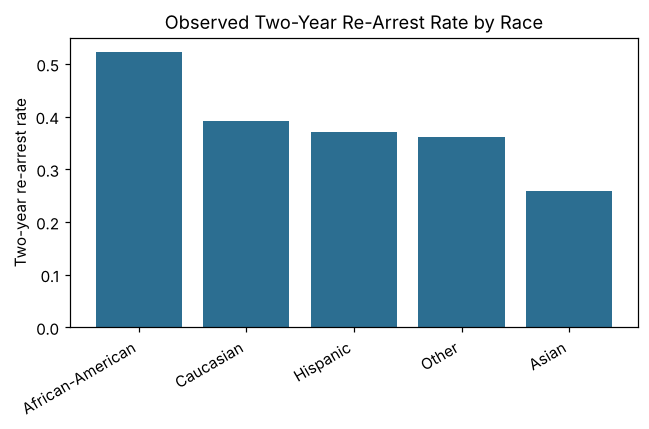

,mean,count
race,,
African-American,0.523,3175
Caucasian,0.391,2103
Hispanic,0.371,509
Other,0.362,343
Asian,0.258,31


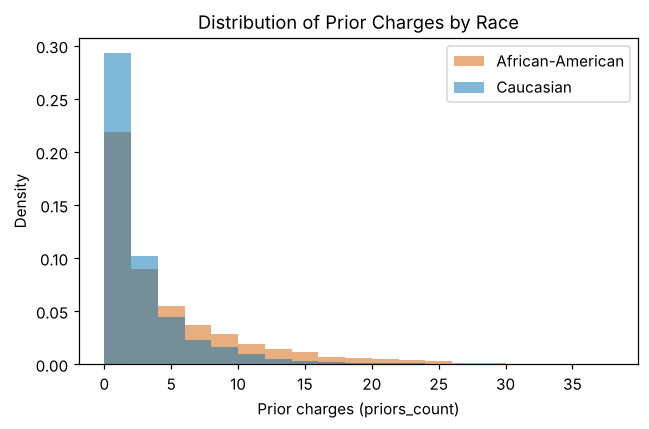

priors_count: African-American mean 4.24 (median 2); Caucasian mean 2.29 (median 1); Mann-Whitney p = 5.68e-44


In [4]:
rates = d.groupby('race')['two_year_recid'].agg(['mean','count']); rates = rates[rates['count'] >= 30].sort_values('mean', ascending=False)
fig, ax = plt.subplots(figsize=(6,4))
ax.bar(rates.index, rates['mean'], color='#2c6e91')
ax.set_ylabel('Two-year re-arrest rate'); ax.set_title('Observed Two-Year Re-Arrest Rate by Race')
plt.xticks(rotation=30, ha='right'); plt.tight_layout(); savefig('fig1a_recid_by_race'); plt.show()
display(rates.round(3))

fig, ax = plt.subplots(figsize=(6,4))
for g in [AA, CA]:
    ax.hist(d.loc[d.race==g, 'priors_count'], bins=range(0, 40, 2), alpha=0.5, label=g, color=COL[g], density=True)
ax.set_xlabel('Prior charges (priors_count)'); ax.set_ylabel('Density'); ax.set_title('Distribution of Prior Charges by Race')
ax.legend(); plt.tight_layout(); savefig('fig1b_priors_by_race'); plt.show()

pa, pc = d.loc[d.race==AA,'priors_count'], d.loc[d.race==CA,'priors_count']
u = st.mannwhitneyu(pa, pc)
print(f"priors_count: African-American mean {pa.mean():.2f} (median {pa.median():.0f}); Caucasian mean {pc.mean():.2f} (median {pc.median():.0f}); Mann-Whitney p = {u.pvalue:.2e}")
R['priors'] = dict(aa_mean=pa.mean(), aa_med=pa.median(), ca_mean=pc.mean(), ca_med=pc.median(), mw_p=u.pvalue)
R['recid_rate_by_race'] = rates['mean'].to_dict()

**Observation.** The two largest racial groups differ in their distribution of prior arrests. Because `priors_count` is itself an administrative record shaped by enforcement practices (see the manuscript's Discussion), this descriptive difference is the starting point for the mechanism analysis in Section 8.

## 4. Predictive Modeling

`race` is **excluded from the feature set**. The models use only conventional inputs to actuarial instruments: age, prior criminal history (adult and juvenile), current charge degree and sex. `race` and the COMPAS `decile_score` are kept *outside* the models and used only for post-hoc auditing (Sections 7–10).

Three race-blind models are compared with COMPAS:
- a **Random Forest** (the main model; explained post hoc with SHAP),
- an **XGBoost** classifier,
- an **interpretable logistic-regression baseline** whose coefficients can be read directly. This baseline is included because ensemble models are *not* transparent in the sense used by the interpretable-modeling literature (Rudin, 2019); they are only explainable post hoc.

Class weighting is used for the Random Forest and the logistic regression so that a 0.50 threshold gives an operating point comparable to COMPAS's medium/high cut-off (decile ≥ 5). Section 11 checks the effect of this choice.

In [5]:
feature_cols = ['age', 'priors_count', 'juv_fel_count', 'juv_misd_count', 'juv_other_count', 'c_charge_degree', 'sex']
X = pd.get_dummies(d[feature_cols], columns=['c_charge_degree', 'sex'], drop_first=True)
y = d['two_year_recid'].astype(int)
race, decile = d['race'], d['decile_score']
print("Model features:", X.columns.tolist())

(X_tr, X_te, y_tr, y_te, race_tr, race_te, dec_tr, dec_te) = train_test_split(
    X, y, race, decile, test_size=0.3, random_state=SEED, stratify=y)
print("Train:", X_tr.shape, "| Test:", X_te.shape)

rf  = RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=20, random_state=SEED, class_weight='balanced')
xgb = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                    random_state=SEED, eval_metric='logloss')
lr  = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight='balanced'))

for m in (rf, xgb, lr): m.fit(X_tr, y_tr)

# numpy views of the test set (used throughout)
yt = y_te.values; rt = race_te.values; dect = dec_te.values
isAA, isCA = (rt == AA), (rt == CA)
S = {'Random Forest': rf.predict_proba(X_te)[:, 1],
     'XGBoost': xgb.predict_proba(X_te)[:, 1],
     'Logistic regression': lr.predict_proba(X_te)[:, 1]}

# COMPAS: the decile score is an ordinal score, not a probability. For AUC it is used as is;
# for Brier score and calibration it is mapped to a probability with a logistic recalibration fitted on the TRAINING set.
cal = LogisticRegression().fit(dec_tr.values.reshape(-1, 1), y_tr)
compas_prob = cal.predict_proba(dect.reshape(-1, 1))[:, 1]
S['COMPAS'] = dect / 10.0                       # ranking only (AUC)
D = {'Random Forest': (S['Random Forest'] >= .5).astype(int), 'XGBoost': (S['XGBoost'] >= .5).astype(int),
     'Logistic regression': (S['Logistic regression'] >= .5).astype(int), 'COMPAS': (dect >= 5).astype(int)}
print("Positive-prediction rate on the test set:", {k: round(v.mean(), 3) for k, v in D.items()})

rng = np.random.default_rng(SEED)
idx = rng.integers(0, len(yt), size=(B, len(yt)), dtype=np.int32)   # shared bootstrap indices (paired comparisons)

Model features: ['age', 'priors_count', 'juv_fel_count', 'juv_misd_count', 'juv_other_count', 'c_charge_degree_M', 'sex_Male']
Train: (4320, 7) | Test: (1852, 7)


Positive-prediction rate on the test set: {'Random Forest': np.float64(0.459), 'XGBoost': np.float64(0.369), 'Logistic regression': np.float64(0.462), 'COMPAS': np.float64(0.442)}


In [6]:
def boot_auc(score):
    return np.array([roc_auc_score(yt[i], score[i]) for i in idx])

aucs, bauc = {}, {}
for k in ['Random Forest', 'XGBoost', 'Logistic regression', 'COMPAS']:
    bauc[k] = boot_auc(S[k]); aucs[k] = roc_auc_score(yt, S[k])

brier = {'Random Forest': brier_score_loss(yt, S['Random Forest']), 'XGBoost': brier_score_loss(yt, S['XGBoost']),
         'Logistic regression': brier_score_loss(yt, S['Logistic regression']),
         'COMPAS': brier_score_loss(yt, compas_prob)}
brier_proxy = brier_score_loss(yt, dect / 10.0)

rows = []
for k in ['Random Forest', 'XGBoost', 'Logistic regression', 'COMPAS']:
    lo, hi = np.percentile(bauc[k], [2.5, 97.5])
    rows.append({'Model': k, 'AUC': aucs[k], 'AUC 95% CI': f'[{lo:.3f}, {hi:.3f}]',
                 'Accuracy': accuracy_score(yt, D[k]), 'Brier': brier[k]})
perf = pd.DataFrame(rows); display(perf.round(3))
print(f"COMPAS Brier with the naive decile/10 'probability' would be {brier_proxy:.3f} (not a valid probability; shown only for reference)")

diffs = {}
for a, b in [('Random Forest', 'COMPAS'), ('XGBoost', 'COMPAS'), ('Logistic regression', 'COMPAS'), ('Random Forest', 'Logistic regression')]:
    dd = bauc[a] - bauc[b]; lo, hi = np.percentile(dd, [2.5, 97.5])
    diffs[f'{a} - {b}'] = dict(diff=aucs[a]-aucs[b], lo=lo, hi=hi, p_boot=2*min((dd <= 0).mean(), (dd >= 0).mean()))
    print(f"AUC({a}) - AUC({b}) = {aucs[a]-aucs[b]:+.3f}  95% CI [{lo:+.3f}, {hi:+.3f}]  (two-sided bootstrap p ≈ {diffs[f'{a} - {b}']['p_boot']:.3f})")
R['perf'] = {r['Model']: dict(auc=r['AUC'], ci=r['AUC 95% CI'], acc=r['Accuracy'], brier=r['Brier']) for r in rows}
R['auc_diffs'] = diffs; R['n_test'] = len(yt)

,Model,AUC,AUC 95% CI,Accuracy,Brier
0,Random Forest,0.738,"[0.715, 0.761]",0.690,0.209
1,XGBoost,0.728,"[0.705, 0.751]",0.687,0.209
2,Logistic regression,0.735,"[0.712, 0.758]",0.678,0.210
3,COMPAS,0.710,"[0.687, 0.734]",0.661,0.215


COMPAS Brier with the naive decile/10 'probability' would be 0.225 (not a valid probability; shown only for reference)
AUC(Random Forest) - AUC(COMPAS) = +0.028  95% CI [+0.006, +0.049]  (two-sided bootstrap p ≈ 0.015)
AUC(XGBoost) - AUC(COMPAS) = +0.018  95% CI [-0.005, +0.040]  (two-sided bootstrap p ≈ 0.115)
AUC(Logistic regression) - AUC(COMPAS) = +0.024  95% CI [+0.004, +0.046]  (two-sided bootstrap p ≈ 0.025)
AUC(Random Forest) - AUC(Logistic regression) = +0.003  95% CI [-0.005, +0.012]  (two-sided bootstrap p ≈ 0.464)


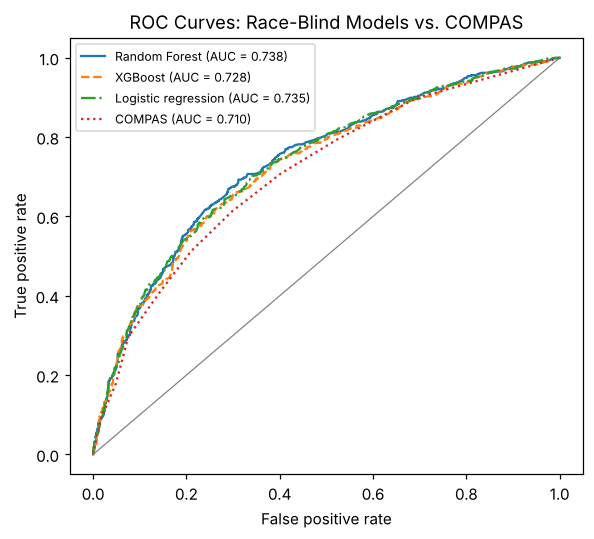

In [7]:
fig, ax = plt.subplots(figsize=(5.5, 5))
for k, ls in [('Random Forest', '-'), ('XGBoost', '--'), ('Logistic regression', '-.'), ('COMPAS', ':')]:
    f_, t_, _ = roc_curve(yt, S[k]); ax.plot(f_, t_, ls, label=f'{k} (AUC = {aucs[k]:.3f})')
ax.plot([0, 1], [0, 1], color='grey', lw=0.8)
ax.set_xlabel('False positive rate'); ax.set_ylabel('True positive rate'); ax.set_title('ROC Curves: Race-Blind Models vs. COMPAS')
ax.legend(fontsize=8); plt.tight_layout(); savefig('fig2_roc'); plt.show()

**Finding.** Race-blind models built on seven public variables reach an AUC of roughly 0.73–0.74 on the held-out test set, against 0.710 for COMPAS. The paired bootstrap shows that the Random Forest advantage over COMPAS (+0.028, 95% CI +0.006 to +0.049) and the logistic-regression advantage (+0.024, +0.004 to +0.046) are small but distinguishable from zero on this single split, whereas the XGBoost difference (+0.018, −0.005 to +0.040) is not. The interpretable logistic regression is statistically indistinguishable from the Random Forest (+0.003, −0.005 to +0.012), consistent with the observation that for this feature set the added flexibility of ensembles buys little (Dressel & Farid, 2018). "Match or modestly exceed" is therefore the appropriate description.

### 4.1 Cross-validation

A single partition can be unrepresentative. We (i) re-estimate AUC with 5-fold stratified cross-validation, using a *t*-based interval for the mean over folds, (ii) compute COMPAS's AUC on exactly the same folds so that differences are **paired**, and (iii) pool the out-of-fold predictions for a full-sample comparison (n = 6,172) with a paired bootstrap. COMPAS is not trained on these data, so its score on any fold is a valid out-of-sample score.

In [8]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
folds = list(skf.split(X, y))
yv, decv = y.values, decile.values
models = {'Random Forest': rf, 'XGBoost': xgb, 'Logistic regression': lr}

fold_auc = {k: [] for k in list(models) + ['COMPAS']}
oof = {}
for k, m in models.items():
    oof[k] = cross_val_predict(m, X, y, cv=folds, method='predict_proba')[:, 1]
    for tr, te in folds: fold_auc[k].append(roc_auc_score(yv[te], oof[k][te]))
for tr, te in folds: fold_auc['COMPAS'].append(roc_auc_score(yv[te], decv[te]))

tcrit = st.t.ppf(0.975, df=4)
cv_rows = []
for k, v in fold_auc.items():
    v = np.array(v); se = v.std(ddof=1)/np.sqrt(5)
    cv_rows.append({'Model': k, 'Mean AUC': v.mean(), 'SD (folds)': v.std(ddof=1), '95% CI (t, 4 df)': f'[{v.mean()-tcrit*se:.3f}, {v.mean()+tcrit*se:.3f}]'})
cv = pd.DataFrame(cv_rows); display(cv.round(3))
print("Per-fold AUC:"); display(pd.DataFrame(fold_auc).round(3))

pair = {}
for k in models:
    dlt = np.array(fold_auc[k]) - np.array(fold_auc['COMPAS']); se = dlt.std(ddof=1)/np.sqrt(5)
    pair[k] = dict(mean=dlt.mean(), lo=dlt.mean()-tcrit*se, hi=dlt.mean()+tcrit*se, folds_positive=int((dlt > 0).sum()))
    print(f"{k:20s} minus COMPAS, paired over folds: {dlt.mean():+.3f}  95% CI [{pair[k]['lo']:+.3f}, {pair[k]['hi']:+.3f}]  (higher in {pair[k]['folds_positive']}/5 folds)")
R['cv'] = {r['Model']: r for r in cv_rows}; R['cv_pair'] = pair
R['cv_fold_auc'] = {k: list(map(float, v)) for k, v in fold_auc.items()}

,Model,Mean AUC,SD (folds),"95% CI (t, 4 df)"
0,Random Forest,0.732,0.011,"[0.718, 0.746]"
1,XGBoost,0.726,0.013,"[0.710, 0.743]"
2,Logistic regression,0.730,0.008,"[0.720, 0.739]"
3,COMPAS,0.710,0.004,"[0.705, 0.715]"


Per-fold AUC:


,Random Forest,XGBoost,Logistic regression,COMPAS
0,0.730,0.720,0.727,0.714
1,0.736,0.722,0.730,0.713
2,0.748,0.748,0.743,0.705
3,0.716,0.714,0.722,0.705
4,0.730,0.727,0.726,0.712


Random Forest        minus COMPAS, paired over folds: +0.022  95% CI [+0.007, +0.037]  (higher in 5/5 folds)
XGBoost              minus COMPAS, paired over folds: +0.016  95% CI [-0.002, +0.035]  (higher in 5/5 folds)
Logistic regression  minus COMPAS, paired over folds: +0.020  95% CI [+0.008, +0.032]  (higher in 5/5 folds)


Pooled OOF AUC Random Forest        0.732 | COMPAS 0.710 | diff +0.022  95% CI [+0.010, +0.033]
Pooled OOF AUC XGBoost              0.726 | COMPAS 0.710 | diff +0.016  95% CI [+0.005, +0.028]
Pooled OOF AUC Logistic regression  0.729 | COMPAS 0.710 | diff +0.020  95% CI [+0.009, +0.031]


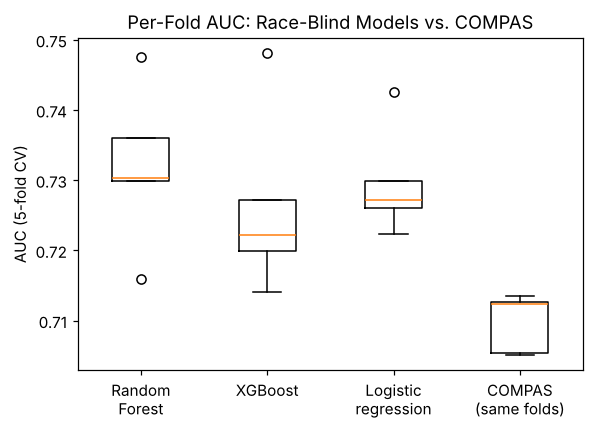

In [9]:
# Pooled out-of-fold comparison on the full sample, paired bootstrap
rng2 = np.random.default_rng(SEED + 1)
idx_full = rng2.integers(0, len(yv), size=(B, len(yv)), dtype=np.int32)
pooled = {}
for k in list(models) + ['COMPAS']:
    s = oof[k] if k in models else decv/10.0
    pooled[k] = dict(point=roc_auc_score(yv, s), boot=np.array([roc_auc_score(yv[i], s[i]) for i in idx_full]))
for k in models:
    dd = pooled[k]['boot'] - pooled['COMPAS']['boot']; lo, hi = np.percentile(dd, [2.5, 97.5])
    pooled[k].update(diff=pooled[k]['point']-pooled['COMPAS']['point'], dlo=lo, dhi=hi)
    print(f"Pooled OOF AUC {k:20s} {pooled[k]['point']:.3f} | COMPAS {pooled['COMPAS']['point']:.3f} | diff {pooled[k]['diff']:+.3f}  95% CI [{lo:+.3f}, {hi:+.3f}]")
R['pooled_auc'] = {k: {kk: (float(vv) if not isinstance(vv, np.ndarray) else None) for kk, vv in v.items()} for k, v in pooled.items()}

fig, ax = plt.subplots(figsize=(5.5, 4))
ax.boxplot([fold_auc['Random Forest'], fold_auc['XGBoost'], fold_auc['Logistic regression'], fold_auc['COMPAS']],
           tick_labels=['Random\nForest', 'XGBoost', 'Logistic\nregression', 'COMPAS\n(same folds)'])
ax.set_ylabel('AUC (5-fold CV)'); ax.set_title('Per-Fold AUC: Race-Blind Models vs. COMPAS')
plt.tight_layout(); savefig('figS1_cv_auc'); plt.show()

## 5. Explanation: SHAP and the Interpretable Baseline

SHAP values (Lundberg & Lee, 2017; TreeExplainer: Lundberg et al., 2020) decompose each Random Forest prediction into additive per-feature contributions. They describe *how the fitted model uses its inputs*; they do not, by themselves, identify the causes of group differences in error rates (Section 8 addresses that).

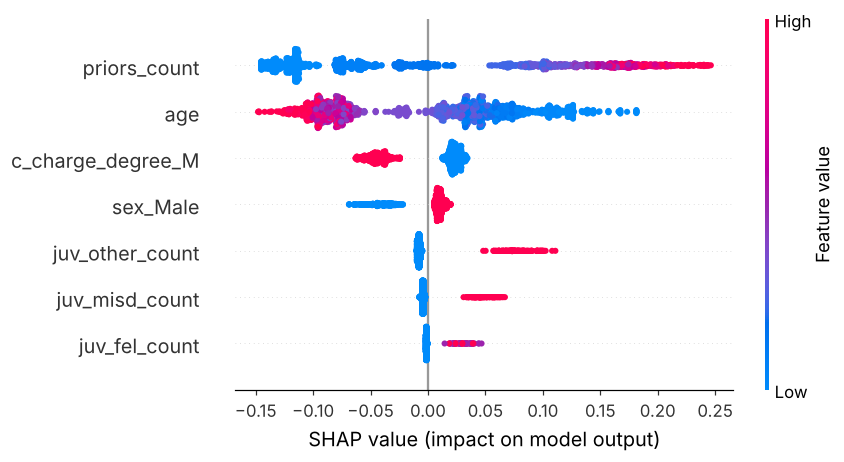

,mean |SHAP|
priors_count,0.108
age,0.070
c_charge_degree_M,0.031
sex_Male,0.016
juv_other_count,0.013
juv_misd_count,0.007
juv_fel_count,0.002


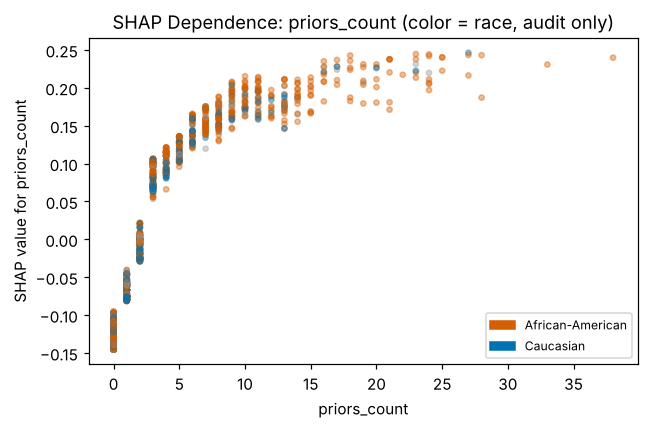

race,African-American,Caucasian
bin,,
0,-0.124,-0.123
1,-0.067,-0.068
2,-0.005,-0.014
3-4,0.093,0.086
5-7,0.140,0.131
8+,0.189,0.179


In [10]:
explainer = shap.TreeExplainer(rf)
sv_raw = explainer.shap_values(X_te)
sv = sv_raw[1] if isinstance(sv_raw, list) else (sv_raw[:, :, 1] if sv_raw.ndim == 3 else sv_raw)

plt.figure(); shap.summary_plot(sv, X_te, show=False); plt.tight_layout(); savefig('fig3_shap_summary'); plt.show()
mean_abs_shap = pd.Series(np.abs(sv).mean(axis=0), index=X_te.columns).sort_values(ascending=False)
display(mean_abs_shap.round(3).to_frame('mean |SHAP|'))
R['shap'] = mean_abs_shap.to_dict()

j = X_te.columns.get_loc('priors_count')
fig, ax = plt.subplots(figsize=(6, 4))
cmap = pd.Series(rt).map({AA: COL[AA], CA: COL[CA]}).fillna('#999999')
ax.scatter(X_te['priors_count'], sv[:, j], c=cmap, alpha=0.4, s=12)
ax.set_xlabel('priors_count'); ax.set_ylabel('SHAP value for priors_count'); ax.set_title('SHAP Dependence: priors_count (color = race, audit only)')
ax.legend(handles=[mpatches.Patch(color=COL[AA], label=AA), mpatches.Patch(color=COL[CA], label=CA)], fontsize=8)
plt.tight_layout(); savefig('fig4_shap_dependence'); plt.show()

# How similar is the learned priors_count -> SHAP relationship across groups? (mean SHAP by priors bin and race)
pb = pd.cut(X_te['priors_count'].values, [-1, 0, 1, 2, 4, 7, 100], labels=['0', '1', '2', '3-4', '5-7', '8+'])
dep = pd.DataFrame({'bin': pb, 'race': rt, 'shap': sv[:, j]}); dep = dep[dep.race.isin([AA, CA])]
display(dep.groupby(['bin', 'race'])['shap'].mean().unstack().round(3))

In [11]:
# Interpretable baseline: standardized logistic-regression coefficients (odds ratios per 1 SD for continuous inputs; per unit for dummies)
coef = lr.named_steps['logisticregression'].coef_[0]
or_tab = pd.DataFrame({'feature': X.columns, 'odds ratio (per SD)': np.exp(coef)}).sort_values('odds ratio (per SD)', ascending=False)
display(or_tab.round(3))
R['lr_or'] = dict(zip(or_tab['feature'], or_tab['odds ratio (per SD)']))

,feature,odds ratio (per SD)
1,priors_count,2.116
6,sex_Male,1.146
4,juv_other_count,1.093
2,juv_fel_count,1.045
3,juv_misd_count,1.009
5,c_charge_degree_M,0.860
0,age,0.610


**Interpretation.** `priors_count` and `age` dominate the Random Forest's predictions, as in the logistic regression, which is consistent with the predictive role of criminal history in the Risk-Need-Responsivity literature (Andrews & Bonta, 2010) and with the age–crime curve (Hirschi & Gottfredson, 1983; Gottfredson & Hirschi, 1990). Because the models never see race, they necessarily map identical feature vectors to identical scores; the dependence plot confirms this for `priors_count` but cannot, on its own, explain group differences in error rates. That requires examining how the *joint distribution of inputs and outcomes* differs between groups (Section 8).

## 6. Fairness Audit: Error-Rate Disparities by Race (with Bootstrap Intervals)

We compare the false positive rate (FPR: predicted high-risk among defendants who did **not** reoffend), false negative rate (FNR) and positive predictive value (PPV) for African-American and Caucasian defendants, following Angwin et al. (2016). All intervals are percentile bootstrap intervals (B = 2,000) over test-set defendants.

In [12]:
def counts(y_, d_, g_, ix=None):
    # confusion-matrix based rates; ix = (B x n) bootstrap indices or None for the point estimate
    if ix is None: ix = np.arange(len(y_))[None, :]
    yb, db, gb = y_[ix], d_[ix], g_[ix]
    neg, pos, pp = (yb == 0) & gb, (yb == 1) & gb, (db == 1) & gb
    fp = (neg & (db == 1)).sum(1); nneg = neg.sum(1); fn = (pos & (db == 0)).sum(1); npos = pos.sum(1)
    tp = (pos & (db == 1)).sum(1); npp = pp.sum(1)
    with np.errstate(divide='ignore', invalid='ignore'):
        return dict(FPR=fp/nneg, FNR=fn/npos, PPV=tp/npp, FP=fp, FLAG=npp/gb.sum(1))

def ci(a): return tuple(np.nanpercentile(a, [2.5, 97.5]))
def fmt(p, c, nd=3): return f'{p:.{nd}f} [{c[0]:.{nd}f}, {c[1]:.{nd}f}]'

def audit(y_, d_, ix):
    out = {}
    for g_name, g_ in [(AA, isAA), (CA, isCA)]:
        out[g_name] = dict(point=counts(y_, d_, g_), boot=counts(y_, d_, g_, ix))
    pa, pc, ba, bc = out[AA]['point'], out[CA]['point'], out[AA]['boot'], out[CA]['boot']
    out['ratio_FPR'] = (pa['FPR'][0]/pc['FPR'][0], ba['FPR']/bc['FPR'])
    out['diff_FPR']  = (pa['FPR'][0]-pc['FPR'][0], ba['FPR']-bc['FPR'])
    out['ratio_FNR'] = (pa['FNR'][0]/pc['FNR'][0], ba['FNR']/bc['FNR'])
    out['diff_FNR']  = (pa['FNR'][0]-pc['FNR'][0], ba['FNR']-bc['FNR'])
    return out

AUD = {m: audit(yt, D[m], idx) for m in ['Random Forest', 'COMPAS', 'Logistic regression', 'XGBoost']}

rows = []
for m in ['Random Forest', 'COMPAS']:
    for g_name, g_ in [(AA, isAA), (CA, isCA)]:
        a = AUD[m][g_name]
        rows.append({'Model': m if m == 'COMPAS' else 'Race-blind RF', 'Group': g_name, 'N': int(g_.sum()), 'Base rate': yt[g_].mean(),
                     'FPR [95% CI]': fmt(a['point']['FPR'][0], ci(a['boot']['FPR'])),
                     'FNR [95% CI]': fmt(a['point']['FNR'][0], ci(a['boot']['FNR'])),
                     'PPV [95% CI]': fmt(a['point']['PPV'][0], ci(a['boot']['PPV'])),
                     'Flagged high-risk': a['point']['FLAG'][0]})
audit_tab = pd.DataFrame(rows); display(audit_tab.round(3))

print("\nDisparity summaries (African-American vs Caucasian), 95% bootstrap CI:")
sumr = []
for m in ['Random Forest', 'XGBoost', 'Logistic regression', 'COMPAS']:
    A = AUD[m]
    sumr.append({'Model': m, 'FPR ratio': fmt(A['ratio_FPR'][0], ci(A['ratio_FPR'][1]), 2), 'FPR difference': fmt(A['diff_FPR'][0], ci(A['diff_FPR'][1])),
                 'FNR ratio': fmt(A['ratio_FNR'][0], ci(A['ratio_FNR'][1]), 2), 'FNR difference': fmt(A['diff_FNR'][0], ci(A['diff_FNR'][1]))})
display(pd.DataFrame(sumr))
R['audit'] = {}
for m, A in AUD.items():
    R['audit'][m] = {g: {k: float(v[0]) for k, v in A[g]['point'].items()} for g in (AA, CA)}
    for g in (AA, CA):
        for k in ('FPR', 'FNR', 'PPV'): R['audit'][m][g][k + '_ci'] = list(map(float, ci(A[g]['boot'][k])))
    for k in ('ratio_FPR', 'diff_FPR', 'ratio_FNR', 'diff_FNR'): R['audit'][m][k] = dict(point=float(A[k][0]), ci=list(map(float, ci(A[k][1]))))
R['audit_N'] = dict(aa=int(isAA.sum()), ca=int(isCA.sum()))
R['base_rate_test'] = dict(aa=float(yt[isAA].mean()), ca=float(yt[isCA].mean()))

,Model,Group,N,Base rate,FPR [95% CI],FNR [95% CI],PPV [95% CI],Flagged high-risk
0,Race-blind RF,African-American,956,0.535,"0.400 [0.353, 0.446]","0.231 [0.194, 0.268]","0.688 [0.651, 0.727]",0.597
1,Race-blind RF,Caucasian,645,0.372,"0.212 [0.174, 0.250]","0.517 [0.453, 0.579]","0.574 [0.505, 0.641]",0.313
2,COMPAS,African-American,956,0.535,"0.411 [0.365, 0.457]","0.297 [0.257, 0.339]","0.662 [0.623, 0.702]",0.567
3,COMPAS,Caucasian,645,0.372,"0.227 [0.187, 0.266]","0.500 [0.435, 0.566]","0.566 [0.498, 0.632]",0.329



Disparity summaries (African-American vs Caucasian), 95% bootstrap CI:


,Model,FPR ratio,FPR difference,FNR ratio,FNR difference
0,Random Forest,"1.88 [1.54, 2.38]","0.188 [0.129, 0.247]","0.45 [0.36, 0.54]","-0.286 [-0.356, -0.215]"
1,XGBoost,"1.89 [1.48, 2.51]","0.137 [0.084, 0.189]","0.60 [0.51, 0.69]","-0.239 [-0.313, -0.167]"
2,Logistic regression,"1.62 [1.32, 2.01]","0.149 [0.086, 0.211]","0.47 [0.38, 0.57]","-0.285 [-0.358, -0.209]"
3,COMPAS,"1.81 [1.49, 2.28]","0.184 [0.123, 0.246]","0.59 [0.49, 0.72]","-0.203 [-0.280, -0.127]"


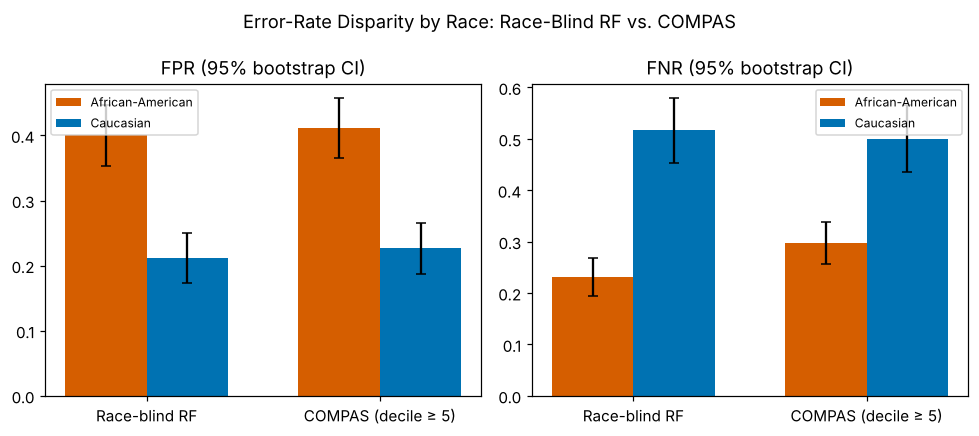

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
labels = ['Race-blind RF', 'COMPAS (decile ≥ 5)']; xs = np.arange(2); w = 0.35
for ax, metric in zip(axes, ['FPR', 'FNR']):
    for off, g_name in [(-w/2, AA), (w/2, CA)]:
        pts = [AUD[m][g_name]['point'][metric][0] for m in ['Random Forest', 'COMPAS']]
        cis = [ci(AUD[m][g_name]['boot'][metric]) for m in ['Random Forest', 'COMPAS']]
        err = np.array([[p - c[0], c[1] - p] for p, c in zip(pts, cis)]).T
        ax.bar(xs + off, pts, w, yerr=err, capsize=3, color=COL[g_name], label=g_name)
    ax.set_xticks(xs); ax.set_xticklabels(labels); ax.set_title(f'{metric} (95% bootstrap CI)'); ax.legend(fontsize=8)
plt.suptitle('Error-Rate Disparity by Race: Race-Blind RF vs. COMPAS'); plt.tight_layout(); savefig('fig5_error_rates'); plt.show()

**Finding.** At the conventional 0.50 threshold the race-blind Random Forest's FPR is 1.88 times higher for African-American than for Caucasian defendants (95% CI 1.54–2.38; absolute difference 0.188, 0.129–0.247), against 1.81 (1.49–2.28) for COMPAS. The ratio is estimated with considerable uncertainty on the 1,601-defendant test subset, and it is smaller (1.72, 1.52–1.94) in the pooled out-of-fold analysis of Section 10. The logistic-regression baseline shows a similar disparity (1.62 on the test set; 1.76 out of fold). Removing race from the feature set therefore did not remove the disparity in error rates in this sample. The positive predictive value also differs by group at this threshold (0.688 vs. 0.574 for the Random Forest), as it does for COMPAS.

## 7. Mechanism Analysis: Where Does the FPR Gap Come From?

A race-blind classifier maps feature vectors to scores identically for every defendant, so any between-group difference in its FPR must arise from differences in the distribution of features **among defendants who did not reoffend** (the FPR is conditional on Y = 0). The informative question is *which* features carry that difference. We examine this on the pooled out-of-fold Random Forest predictions for all African-American and Caucasian defendants (n = 5,278), which gives more precision than the test set alone.

Two analyses:
1. **Stratified view:** recidivism rate, mean model score and FPR within bins of `priors_count`, by race. If the same score means the same thing at a given record, the disparity is carried by the *distribution* of records, not by how records are scored.
2. **Counterfactual reweighting** (in the spirit of DiNardo, Fortin & Lemieux, 1996): reweight Caucasian non-recidivists so that their distribution of one feature (or a feature combination) matches that of African-American non-recidivists, and recompute their FPR. The share of the FPR gap this closes indicates how much of the gap is carried by that feature.

In [14]:
mask = race.isin([AA, CA]).values
M = pd.DataFrame({'y': yv[mask], 'p': oof['Random Forest'][mask], 'race': race.values[mask], 'priors': X['priors_count'].values[mask],
                  'age': X['age'].values[mask]})
M['d'] = (M['p'] >= 0.5).astype(int)
M['pbin'] = pd.cut(M['priors'], [-1, 0, 1, 2, 4, 7, 100], labels=['0', '1', '2', '3-4', '5-7', '8+'])
M['abin'] = pd.cut(M['age'], [0, 24, 34, 44, 100], labels=['<=24', '25-34', '35-44', '45+'])
print("n =", len(M), "| OOF FPR by race:", M[M.y == 0].groupby('race')['d'].mean().round(3).to_dict())

# (1) stratified view
tab1 = M.groupby(['pbin', 'race']).agg(n=('y', 'size'), recid_rate=('y', 'mean'), mean_score=('p', 'mean')).unstack('race')
fpr_bin = M[M.y == 0].groupby(['pbin', 'race'])['d'].mean().unstack('race')
n0_bin = M[M.y == 0].groupby(['pbin', 'race']).size().unstack('race')
display(tab1.round(3)); print("FPR by prior-record bin (non-recidivists only):"); display(fpr_bin.round(3)); print("n non-recidivists per cell:"); display(n0_bin)

share0 = M[M.y == 0].groupby('race')['pbin'].value_counts(normalize=True).unstack(0).round(3)
print("Distribution of prior-record bins among NON-recidivists:"); display(share0)
shareAll = M.groupby('race')['pbin'].value_counts(normalize=True).unstack(0).round(3)
print("Distribution of prior-record bins among ALL defendants:"); display(shareAll)
R['mech_tables'] = dict(share_nonrecid=share0.to_dict(), share_all=shareAll.to_dict(), recid_rate_bin=tab1['recid_rate'].to_dict(),
                        fpr_bin=fpr_bin.to_dict(), n0_bin=n0_bin.to_dict(), n_bin=tab1['n'].to_dict())

n = 5278 | OOF FPR by race: {'African-American': 0.388, 'Caucasian': 0.226}


n                 recid_rate                 mean_score          
race African-American Caucasian African-American Caucasian African-American Caucasian
pbin                                                                                 
0                 846       821            0.340     0.257            0.392     0.342
1                 543       410            0.424     0.354            0.447     0.396
2                 325       258            0.511     0.411            0.514     0.463
3-4               432       272            0.579     0.515            0.610     0.564
5-7               395       180            0.623     0.594            0.656     0.619
8+                634       162            0.759     0.698            0.707     0.673

FPR by prior-record bin (non-recidivists only):


race,African-American,Caucasian
pbin,,
0,0.125,0.056
1,0.166,0.125
2,0.421,0.322
3-4,0.610,0.462
5-7,0.899,0.863
8+,1.000,1.000


n non-recidivists per cell:


race,African-American,Caucasian
pbin,,
0,558,610
1,313,265
2,159,152
3-4,182,132
5-7,149,73
8+,153,49


Distribution of prior-record bins among NON-recidivists:


race,African-American,Caucasian
pbin,,
0,0.369,0.476
1,0.207,0.207
2,0.105,0.119
3-4,0.120,0.103
5-7,0.098,0.057
8+,0.101,0.038


Distribution of prior-record bins among ALL defendants:


race,African-American,Caucasian
pbin,,
0,0.266,0.390
1,0.171,0.195
2,0.102,0.123
3-4,0.136,0.129
5-7,0.124,0.086
8+,0.200,0.077


In [15]:
def cf_fpr(yy, dd, is_aa, cell, ix=None):
    # FPR of Caucasian non-recidivists reweighted so their distribution over `cell` matches African-American non-recidivists.
    if ix is None: ix = np.arange(len(yy))[None, :]
    res = []
    ncell = cell.max() + 1
    for i in ix:
        y_, d_, a_, c_ = yy[i], dd[i], is_aa[i], cell[i]
        neg = (y_ == 0)
        wa = np.bincount(c_[neg & a_], minlength=ncell).astype(float); wc = np.bincount(c_[neg & ~a_], minlength=ncell).astype(float)
        fc = np.bincount(c_[neg & ~a_ & (d_ == 1)], minlength=ncell).astype(float)
        supp = (wa > 0) & (wc > 0)                       # common support
        pa_ = wa / wa.sum(); fc_rate = np.where(wc > 0, fc / np.maximum(wc, 1), 0)
        fpr_cf = (pa_[supp] * fc_rate[supp]).sum() / pa_[supp].sum()
        fpr_aa = ((d_ == 1) & neg & a_).sum() / (neg & a_).sum(); fpr_ca = ((d_ == 1) & neg & ~a_).sum() / (neg & ~a_).sum()
        res.append((fpr_aa, fpr_ca, fpr_cf, pa_[supp].sum() / pa_.sum()))
    return np.array(res)

yy, dd, isaa = M['y'].values, M['d'].values, (M['race'] == AA).values
cells = {'priors bin': M['pbin'].cat.codes.values.astype(int),
         'age bin': M['abin'].cat.codes.values.astype(int),
         'priors x age': (M['pbin'].cat.codes.values * 4 + M['abin'].cat.codes.values).astype(int)}
Bm = 1000; ixm = np.random.default_rng(SEED + 2).integers(0, len(yy), size=(Bm, len(yy)), dtype=np.int32)

rows, R['mech_cf'] = [], {}
for name, c in cells.items():
    pt = cf_fpr(yy, dd, isaa, c)[0]; bt = cf_fpr(yy, dd, isaa, c, ixm)
    gap = pt[0] - pt[1]; closed = (pt[2] - pt[1]) / gap
    closed_b = (bt[:, 2] - bt[:, 1]) / (bt[:, 0] - bt[:, 1])
    rows.append({'Reweight Caucasian non-recidivists to AA distribution of': name, 'FPR AA': pt[0], 'FPR Cauc (observed)': pt[1],
                 'FPR Cauc (reweighted)': pt[2], 'Share of gap closed [95% CI]': f'{closed:.2f} [{np.percentile(closed_b, 2.5):.2f}, {np.percentile(closed_b, 97.5):.2f}]',
                 'AA support covered': pt[3]})
    R['mech_cf'][name] = dict(fpr_aa=float(pt[0]), fpr_ca=float(pt[1]), fpr_cf=float(pt[2]), closed=float(closed),
                              closed_ci=[float(np.percentile(closed_b, 2.5)), float(np.percentile(closed_b, 97.5))], support=float(pt[3]))
display(pd.DataFrame(rows).round(3))

,Reweight Caucasian non-recidivists to AA distribution of,FPR AA,FPR Cauc (observed),FPR Cauc (reweighted),Share of gap closed [95% CI],AA support covered
0,priors bin,0.388,0.226,0.322,"0.59 [0.49, 0.72]",1.0
1,age bin,0.388,0.226,0.282,"0.35 [0.25, 0.47]",1.0
2,priors x age,0.388,0.226,0.386,"0.99 [0.86, 1.14]",1.0


**What this analysis can and cannot show.** Because the classifier is race-blind, the FPR gap is, by definition, the difference between the groups in the distribution of the inputs among non-recidivists, passed through the same scoring function. Reweighting Caucasian non-recidivists on *all* inputs would therefore close the entire gap by construction. The analysis is informative only about *which* inputs carry it: here, prior record and age alone suffice to close essentially all of it, so the remaining five inputs (juvenile record, charge degree, sex) add almost nothing, and neither variable alone is sufficient. It is a descriptive decomposition of where the disparity sits, not a test of whether the disparity exists, and not evidence about why the distributions differ.

**Reading the tables.** African-American non-recidivists are over-represented among defendants with long prior records (e.g., 10% have 8+ priors vs. 4% of Caucasian non-recidivists) and are younger. Reweighting Caucasian non-recidivists to the African-American distribution of prior record alone closes about 59% of the FPR gap (95% CI 0.49–0.72); age alone closes about 35% (0.25–0.47); the combination of prior record and age closes essentially all of it (0.99, 0.86–1.14). Within every prior-record bin the African-American defendants also have a higher observed re-arrest rate and a higher mean score, so the model's scores track the observed outcome rates of each group; the SHAP contribution of `priors_count` itself is nearly identical across groups (Section 5), so the within-bin score differences must come from the other inputs. Age is the most likely candidate (African-American non-recidivists are younger: mean 34.1 vs. 39.4 years), but this was not decomposed separately. These are descriptive decompositions, not causal estimates: they do not explain *why* record distributions differ (see the limitations).

## 8. Calibration

Calibration asks whether a given score means the same observed recidivism rate in each group. Calibration and equal error rates cannot generally both hold when base rates differ (Chouldechova, 2017; Kleinberg et al., 2017).

- **Race-blind Random Forest:** quantile-binned calibration curves (10 bins overall; 6 bins per group), summarized by the mean absolute calibration gap per group, with bootstrap intervals for each gap and for their difference.
- **COMPAS:** the decile score is an ordinal score, not a probability, so we (i) show observed recidivism rates by race within groups of decile scores (a predictive-parity view), and (ii) summarize a calibration gap after the training-set logistic recalibration of Section 4.

In [16]:
def gap_rf(y_, p_, g_, nb=6):
    fp_, mp_ = calibration_curve(y_[g_], p_[g_], n_bins=nb, strategy='quantile'); return np.abs(fp_ - mp_).mean()

p_rf = S['Random Forest']
gaps = {g: gap_rf(yt, p_rf, m) for g, m in [(AA, isAA), (CA, isCA)]}
bg = {AA: [], CA: []}
for i in idx:
    for g, m in [(AA, isAA), (CA, isCA)]: bg[g].append(gap_rf(yt[i], p_rf[i], m[i]))
bg = {g: np.array(v) for g, v in bg.items()}; dgap = bg[AA] - bg[CA]
for g in (AA, CA): print(f"{g:18s} mean |calibration gap| = {gaps[g]:.3f}  95% CI [{np.percentile(bg[g], 2.5):.3f}, {np.percentile(bg[g], 97.5):.3f}]")
print(f"Difference (AA - Cauc) = {gaps[AA]-gaps[CA]:+.3f}  95% CI [{np.percentile(dgap, 2.5):+.3f}, {np.percentile(dgap, 97.5):+.3f}]")
R['calib_rf'] = {g: dict(gap=float(gaps[g]), ci=list(map(float, np.percentile(bg[g], [2.5, 97.5])))) for g in (AA, CA)}
R['calib_rf']['diff'] = dict(point=float(gaps[AA]-gaps[CA]), ci=list(map(float, np.percentile(dgap, [2.5, 97.5]))))

# COMPAS by race: observed recidivism within decile-score groups
sg = pd.cut(dect, [0, 2, 4, 6, 8, 10], labels=['1-2', '3-4', '5-6', '7-8', '9-10'])
crow = []
for g, m in [(AA, isAA), (CA, isCA)]:
    for lab in sg.categories:
        sel = m & (sg == lab); n_ = int(sel.sum()); k_ = int(yt[sel].sum())
        lo, hi = proportion_confint(k_, n_, method='wilson') if n_ > 0 else (np.nan, np.nan)
        crow.append(dict(group=g, score=lab, n=n_, observed=k_/n_ if n_ else np.nan, lo=lo, hi=hi, pred=compas_prob[sel].mean() if n_ else np.nan))
ctab = pd.DataFrame(crow); display(ctab.round(3))
cg = ctab.groupby('group').apply(lambda t: np.nanmean(np.abs(t['observed'] - t['pred']))); print("COMPAS mean |gap| (recalibrated), by group:", cg.round(3).to_dict())
R['calib_compas_gap'] = cg.to_dict(); R['calib_compas_tab'] = ctab.to_dict('records')

African-American   mean |calibration gap| = 0.063  95% CI [0.039, 0.093]
Caucasian          mean |calibration gap| = 0.061  95% CI [0.040, 0.098]
Difference (AA - Cauc) = +0.002  95% CI [-0.042, +0.036]


,group,score,n,observed,lo,hi,pred
0,African-American,1-2,227,0.291,0.236,0.353,0.268
1,African-American,3-4,187,0.460,0.390,0.531,0.390
2,African-American,5-6,187,0.540,0.469,0.610,0.524
3,African-American,7-8,199,0.693,0.626,0.753,0.656
4,African-American,9-10,156,0.769,0.697,0.828,0.769
5,Caucasian,1-2,294,0.252,0.206,0.304,0.257
6,Caucasian,3-4,139,0.331,0.258,0.413,0.386
7,Caucasian,5-6,108,0.500,0.407,0.593,0.520
8,Caucasian,7-8,74,0.635,0.521,0.736,0.653
9,Caucasian,9-10,30,0.633,0.455,0.781,0.764


COMPAS mean |gap| (recalibrated), by group: {'African-American': 0.029, 'Caucasian': 0.046}


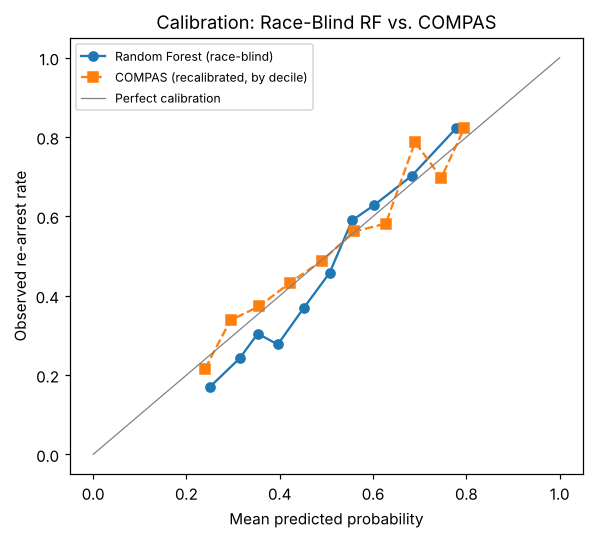

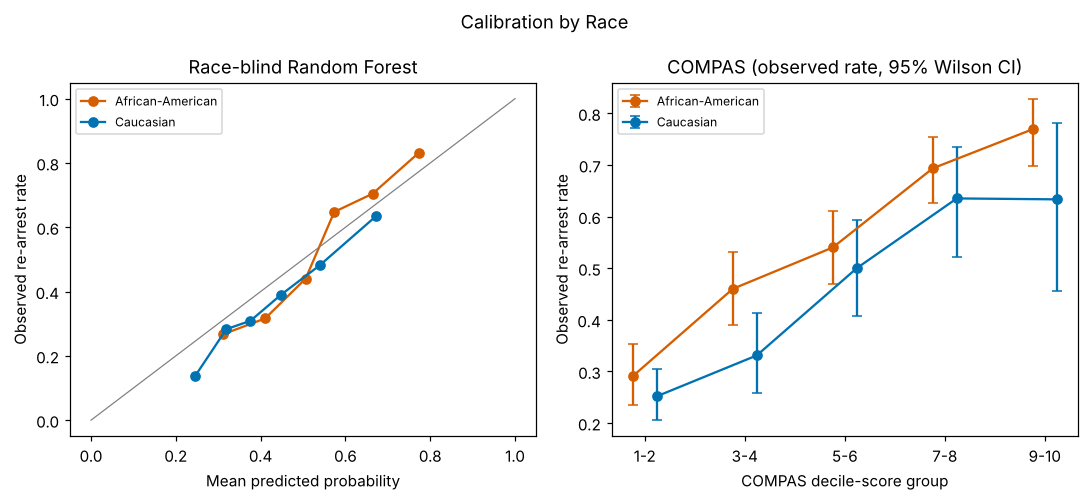

In [17]:
fig, ax = plt.subplots(figsize=(5.5, 5))
fp_, mp_ = calibration_curve(yt, p_rf, n_bins=10, strategy='quantile'); ax.plot(mp_, fp_, 'o-', label='Random Forest (race-blind)')
lv = pd.DataFrame({'p': compas_prob, 'y': yt, 'dec': dect}).groupby('dec').agg(p=('p', 'mean'), y=('y', 'mean'))
ax.plot(lv['p'], lv['y'], 's--', label='COMPAS (recalibrated, by decile)')
ax.plot([0, 1], [0, 1], color='grey', lw=0.8, label='Perfect calibration')
ax.set_xlabel('Mean predicted probability'); ax.set_ylabel('Observed re-arrest rate'); ax.set_title('Calibration: Race-Blind RF vs. COMPAS')
ax.legend(fontsize=8); plt.tight_layout(); savefig('fig6_calibration_overall'); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 4.6))
ax = axes[0]
for g, m in [(AA, isAA), (CA, isCA)]:
    fp_, mp_ = calibration_curve(yt[m], p_rf[m], n_bins=6, strategy='quantile'); ax.plot(mp_, fp_, 'o-', color=COL[g], label=g)
ax.plot([0, 1], [0, 1], color='grey', lw=0.8); ax.set_xlabel('Mean predicted probability'); ax.set_ylabel('Observed re-arrest rate')
ax.set_title('Race-blind Random Forest'); ax.legend(fontsize=8)
ax = axes[1]
for off, g in [(-0.12, AA), (0.12, CA)]:
    t = ctab[ctab.group == g]; xs_ = np.arange(len(t)) + off
    ax.errorbar(xs_, t['observed'], yerr=[t['observed'] - t['lo'], t['hi'] - t['observed']], fmt='o-', color=COL[g], capsize=3, label=g)
ax.set_xticks(range(5)); ax.set_xticklabels(sg.categories); ax.set_xlabel('COMPAS decile-score group'); ax.set_ylabel('Observed re-arrest rate')
ax.set_title('COMPAS (observed rate, 95% Wilson CI)'); ax.legend(fontsize=8)
plt.suptitle('Calibration by Race'); plt.tight_layout(); savefig('fig7_calibration_by_race'); plt.show()

**Finding.** The race-blind Random Forest's mean absolute calibration gap is 0.063 for African-American and 0.061 for Caucasian defendants; the interval for the difference (+0.002, 95% CI −0.042 to +0.036) includes zero, so there is no detectable group difference in calibration at this sample size (a small-sample caveat: each group-specific curve rests on six bins and the intervals for the gaps themselves are wide). Section 10 shows that this conclusion is sensitive to class weighting: the unweighted model gives a larger point estimate for the difference (+0.033, 95% CI −0.015 to +0.055), so the data cannot distinguish equal from modestly unequal calibration. The COMPAS panel shows the analogous predictive-parity view: observed rates at the same score group are similar for the two races at the lowest and highest scores but numerically higher for African-American defendants at 3–4 (0.46 vs. 0.33) with narrowly overlapping intervals, and the Caucasian 9–10 cell is small (n = 30). The absence of a detectable calibration difference alongside unequal error rates is consistent with the impossibility results when base rates differ (53.5% vs. 37.2% in the test set). Score-level calibration is not the same as equal positive predictive value at a threshold: the PPVs in Section 6 differ by group.

## 9. Classification-Threshold Sensitivity

The 0.50 threshold is a convention, not a requirement. We recompute accuracy, F1 and the racial FPR disparity for the race-blind Random Forest over 13 thresholds from 0.20 to 0.80. We report **both the ratio and the absolute difference** of FPRs, because a ratio can rise while the absolute gap falls when both rates approach zero. Intervals are bootstrap intervals; cells with fewer than 30 false positives among Caucasian defendants are flagged as unstable.

In [18]:
def sweep(y_, p_, aa_, ca_, ix, thr=np.round(np.arange(0.20, 0.801, 0.05), 2)):
    rows = []
    for t in thr:
        d_ = (p_ >= t).astype(int)
        ca_c, aa_c = counts(y_, d_, ca_), counts(y_, d_, aa_)
        cb_c, ab_c = counts(y_, d_, ca_, ix), counts(y_, d_, aa_, ix)
        with np.errstate(divide='ignore', invalid='ignore'):
            r_pt = aa_c['FPR'][0] / ca_c['FPR'][0]; r_b = ab_c['FPR'] / cb_c['FPR']
        diff_pt = aa_c['FPR'][0] - ca_c['FPR'][0]; diff_b = ab_c['FPR'] - cb_c['FPR']
        rows.append(dict(threshold=t, accuracy=accuracy_score(y_, d_), f1=f1_score(y_, d_), fpr_aa=aa_c['FPR'][0], fpr_ca=ca_c['FPR'][0],
                         ratio=r_pt, ratio_lo=np.nanpercentile(r_b, 2.5), ratio_hi=np.nanpercentile(r_b, 97.5),
                         diff=diff_pt, diff_lo=np.percentile(diff_b, 2.5), diff_hi=np.percentile(diff_b, 97.5),
                         fp_ca=int(ca_c['FP'][0]), flag_aa=aa_c['FLAG'][0], flag_ca=ca_c['FLAG'][0], unstable=bool(ca_c['FP'][0] < 30)))
    return pd.DataFrame(rows)

sw = sweep(yt, p_rf, isAA, isCA, idx)
show = sw.copy(); show['ratio [95% CI]'] = [f"{r:.2f} [{a:.2f}, {b:.2f}]" for r, a, b in zip(sw.ratio, sw.ratio_lo, sw.ratio_hi)]
show['diff [95% CI]'] = [f"{r:.3f} [{a:.3f}, {b:.3f}]" for r, a, b in zip(sw['diff'], sw.diff_lo, sw.diff_hi)]
display(show[['threshold', 'accuracy', 'f1', 'fpr_aa', 'fpr_ca', 'ratio [95% CI]', 'diff [95% CI]', 'fp_ca', 'flag_aa', 'flag_ca', 'unstable']].round(3))
R['sweep'] = sw.to_dict('records')

,threshold,accuracy,f1,fpr_aa,fpr_ca,ratio [95% CI],diff [95% CI],fp_ca,flag_aa,flag_ca,unstable
0,0.20,0.461,0.628,0.996,0.975,"1.02 [1.00, 1.04]","0.020 [0.004, 0.037]",395,0.998,0.983,False
1,0.25,0.487,0.637,0.973,0.889,"1.09 [1.05, 1.14]","0.084 [0.050, 0.119]",360,0.985,0.921,False
2,0.30,0.538,0.653,0.888,0.736,"1.21 [1.13, 1.29]","0.152 [0.100, 0.204]",298,0.936,0.806,False
3,0.35,0.592,0.663,0.769,0.563,"1.37 [1.24, 1.51]","0.206 [0.144, 0.267]",228,0.859,0.648,False
4,0.40,0.639,0.670,0.631,0.417,"1.51 [1.33, 1.75]","0.214 [0.148, 0.277]",169,0.763,0.516,False
5,0.45,0.672,0.674,0.512,0.314,"1.63 [1.38, 1.96]","0.199 [0.133, 0.265]",127,0.686,0.420,False
6,0.50,0.690,0.660,0.400,0.212,"1.88 [1.54, 2.38]","0.188 [0.129, 0.247]",86,0.597,0.313,False
7,0.55,0.690,0.618,0.272,0.148,"1.84 [1.42, 2.45]","0.124 [0.071, 0.176]",60,0.478,0.237,False
8,0.60,0.665,0.522,0.175,0.079,"2.22 [1.53, 3.35]","0.096 [0.051, 0.139]",32,0.347,0.136,False
9,0.65,0.645,0.447,0.128,0.044,"2.88 [1.78, 5.21]","0.084 [0.047, 0.121]",18,0.267,0.093,True


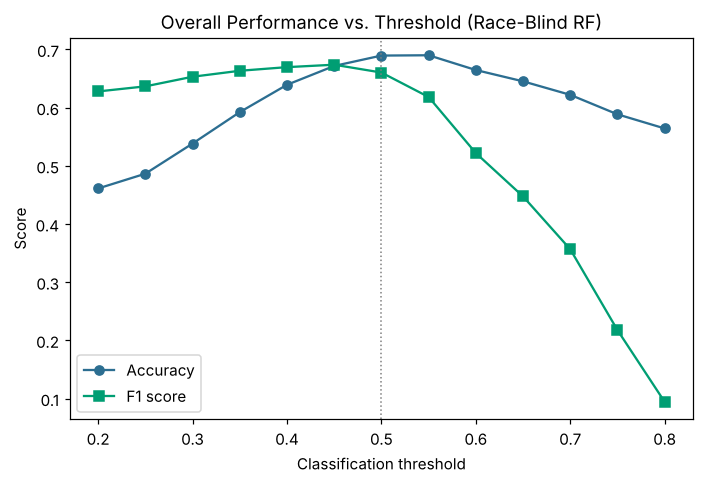

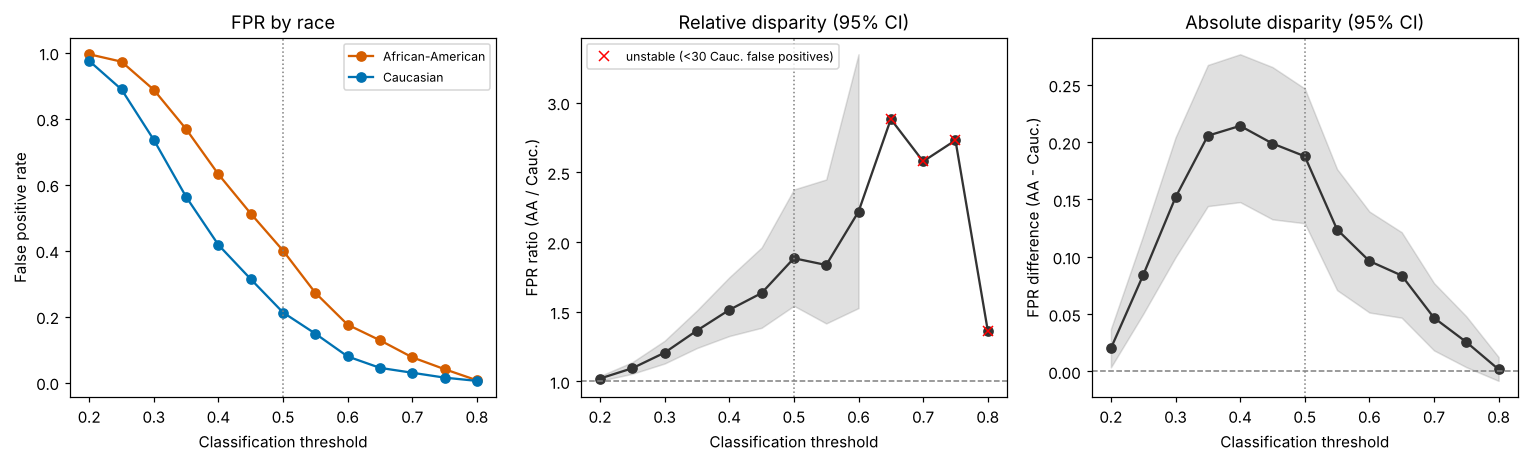

FPR ratio range over thresholds with >=30 Cauc. false positives: 1.02x to 2.22x
Absolute FPR difference: max 0.214 at threshold 0.40


In [19]:
fig, ax1 = plt.subplots(figsize=(6.5, 4.5))
ax1.plot(sw.threshold, sw.accuracy, 'o-', label='Accuracy', color='#2c6e91'); ax1.plot(sw.threshold, sw.f1, 's-', label='F1 score', color='#009e73')
ax1.axvline(0.5, color='grey', ls=':', lw=1); ax1.set_xlabel('Classification threshold'); ax1.set_ylabel('Score')
ax1.set_title('Overall Performance vs. Threshold (Race-Blind RF)'); ax1.legend(); plt.tight_layout(); savefig('figS2_performance_vs_threshold'); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 4.3))
ax = axes[0]; ax.plot(sw.threshold, sw.fpr_aa, 'o-', color=COL[AA], label=AA); ax.plot(sw.threshold, sw.fpr_ca, 'o-', color=COL[CA], label=CA)
ax.set_xlabel('Classification threshold'); ax.set_ylabel('False positive rate'); ax.set_title('FPR by race'); ax.legend(fontsize=8); ax.axvline(0.5, color='grey', ls=':', lw=1)
ax = axes[1]; ok = ~sw.unstable
ax.plot(sw.threshold, sw.ratio, 'o-', color='#333333'); ax.fill_between(sw.threshold[ok], sw.ratio_lo[ok], sw.ratio_hi[ok], color='#333333', alpha=0.15)
ax.plot(sw.threshold[~ok], sw.ratio[~ok], 'x', color='red', label='unstable (<30 Cauc. false positives)')
ax.axhline(1, color='grey', ls='--', lw=1); ax.axvline(0.5, color='grey', ls=':', lw=1)
ax.set_xlabel('Classification threshold'); ax.set_ylabel('FPR ratio (AA / Cauc.)'); ax.set_title('Relative disparity (95% CI)'); ax.legend(fontsize=8)
ax = axes[2]; ax.plot(sw.threshold, sw['diff'], 'o-', color='#333333'); ax.fill_between(sw.threshold, sw.diff_lo, sw.diff_hi, color='#333333', alpha=0.15)
ax.axhline(0, color='grey', ls='--', lw=1); ax.axvline(0.5, color='grey', ls=':', lw=1)
ax.set_xlabel('Classification threshold'); ax.set_ylabel('FPR difference (AA - Cauc.)'); ax.set_title('Absolute disparity (95% CI)')
plt.tight_layout(); savefig('fig8_threshold'); plt.show()
print(f"FPR ratio range over thresholds with >=30 Cauc. false positives: {sw.loc[~sw.unstable,'ratio'].min():.2f}x to {sw.loc[~sw.unstable,'ratio'].max():.2f}x")
print(f"Absolute FPR difference: max {sw['diff'].max():.3f} at threshold {sw.loc[sw['diff'].idxmax(),'threshold']:.2f}")

**Finding.** The relative disparity is not constant. It is close to parity at lenient thresholds that flag nearly everyone (1.02 at τ = 0.20), rises to 1.88 at τ = 0.50 and to 2.22 at τ = 0.60 on the test set, and reaches about 2.5 at τ = 0.70 in the pooled out-of-fold analysis (95% CI 1.84–3.54). Beyond τ ≈ 0.60–0.65 the test-set estimates are unstable (fewer than 30 Caucasian false positives; point estimates of 2.6–2.9 have intervals spanning roughly 1.2 to 9.5) and should not be interpreted. The *absolute* FPR gap peaks at moderate thresholds (0.214 at τ = 0.40 on the test set; 0.214 at τ = 0.35 out of fold) and shrinks at strict thresholds (0.084 at τ = 0.65) because both FPRs fall toward zero. A stricter threshold therefore does not equalize the false-positive burden in relative terms, although it reduces the number of people of both groups who bear it. The threshold is a policy choice with distributional consequences.

## 10. Sensitivity Checks

**(a) Class weighting.** Class-balanced weights shift predicted probabilities, which matters most for calibration. We refit the Random Forest without class weights and compare (i) AUC, Brier score and the FPR ratio at τ = 0.50 and at τ equal to the training base rate, and (ii) the group-specific calibration gaps of Section 8, computed with the same procedure and bootstrap.

**(b) Out-of-fold audit on the full sample.** The Section 6 audit is repeated on pooled out-of-fold predictions for all 5,278 African-American and Caucasian defendants, which has substantially more precision than the 1,601-defendant test subset.

In [20]:
rf_nb = RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=20, random_state=SEED).fit(X_tr, y_tr)
p_nb = rf_nb.predict_proba(X_te)[:, 1]
br = y_tr.mean()
sens = [{'Model': 'RF, class-balanced (main)', 'AUC': aucs['Random Forest'], 'Brier': brier['Random Forest'], 'tau': 0.5},
        {'Model': 'RF, unweighted', 'AUC': roc_auc_score(yt, p_nb), 'Brier': brier_score_loss(yt, p_nb), 'tau': br}]
for r_ in sens:
    pr = p_rf if 'balanced' in r_['Model'] else p_nb
    d_ = (pr >= r_['tau']).astype(int); a_, c_ = counts(yt, d_, isAA), counts(yt, d_, isCA)
    r_['threshold'] = round(r_['tau'], 3); r_['FPR AA'] = a_['FPR'][0]; r_['FPR Cauc'] = c_['FPR'][0]; r_['FPR ratio'] = a_['FPR'][0] / c_['FPR'][0]; r_['flagged'] = d_.mean()
display(pd.DataFrame(sens).drop(columns='tau').round(3)); R['sens_weight'] = sens

# (a2) Group calibration of the UNWEIGHTED Random Forest (class weighting shifts probabilities, which matters most for calibration)
gaps_nb = {g: gap_rf(yt, p_nb, m) for g, m in [(AA, isAA), (CA, isCA)]}
bg_nb = {AA: [], CA: []}
for i in idx:
    for g, m in [(AA, isAA), (CA, isCA)]: bg_nb[g].append(gap_rf(yt[i], p_nb[i], m[i]))
bg_nb = {g: np.array(v) for g, v in bg_nb.items()}; dgap_nb = bg_nb[AA] - bg_nb[CA]
print("\nUnweighted Random Forest, 6-bin calibration by race (same procedure as Section 8):")
for g in (AA, CA): print(f"  {g:18s} mean |calibration gap| = {gaps_nb[g]:.3f}  95% CI [{np.percentile(bg_nb[g], 2.5):.3f}, {np.percentile(bg_nb[g], 97.5):.3f}]")
print(f"  Difference (AA - Cauc) = {gaps_nb[AA]-gaps_nb[CA]:+.3f}  95% CI [{np.percentile(dgap_nb, 2.5):+.3f}, {np.percentile(dgap_nb, 97.5):+.3f}]")
# overall (all defendants) calibration gap and mean predicted vs observed rate, balanced vs unweighted
fo_b, mo_b = calibration_curve(yt, p_rf, n_bins=10, strategy='quantile'); fo_n, mo_n = calibration_curve(yt, p_nb, n_bins=10, strategy='quantile')
print(f"  Overall 10-bin mean |gap|: class-balanced {np.abs(fo_b-mo_b).mean():.3f} | unweighted {np.abs(fo_n-mo_n).mean():.3f}")
print(f"  Mean predicted probability: class-balanced {p_rf.mean():.3f} | unweighted {p_nb.mean():.3f} | observed base rate (test) {yt.mean():.3f}")
R['calib_rf_unweighted'] = {g: dict(gap=float(gaps_nb[g]), ci=list(map(float, np.percentile(bg_nb[g], [2.5, 97.5])))) for g in (AA, CA)}
R['calib_rf_unweighted']['diff'] = dict(point=float(gaps_nb[AA]-gaps_nb[CA]), ci=list(map(float, np.percentile(dgap_nb, [2.5, 97.5]))))
R['calib_rf_unweighted']['overall_gap'] = dict(balanced=float(np.abs(fo_b-mo_b).mean()), unweighted=float(np.abs(fo_n-mo_n).mean()))
R['calib_rf_unweighted']['mean_pred'] = dict(balanced=float(p_rf.mean()), unweighted=float(p_nb.mean()), observed=float(yt.mean()))

# (b) out-of-fold audit on the full sample (AA & Cauc), paired bootstrap with idx_full
mfull = race.isin([AA, CA]).values
y_f, r_f, dec_f = yv, race.values, decv
isAA_f, isCA_f = (r_f == AA), (r_f == CA)
def audit_full(score, thr):
    d_ = (score >= thr).astype(int); out = {}
    for g, m in [(AA, isAA_f), (CA, isCA_f)]: out[g] = (counts(y_f, d_, m), counts(y_f, d_, m, idx_full))
    return out
rows = []
for name, sc, thr in [('Race-blind RF (OOF)', oof['Random Forest'], 0.5), ('Logistic regression (OOF)', oof['Logistic regression'], 0.5),
                      ('XGBoost (OOF)', oof['XGBoost'], 0.5), ('COMPAS (decile >= 5)', dec_f / 10.0, 0.5)]:
    o = audit_full(sc, thr)
    ratio = o[AA][0]['FPR'][0] / o[CA][0]['FPR'][0]; rb = o[AA][1]['FPR'] / o[CA][1]['FPR']
    dif = o[AA][0]['FPR'][0] - o[CA][0]['FPR'][0]; db_ = o[AA][1]['FPR'] - o[CA][1]['FPR']
    fr = o[AA][0]['FNR'][0] / o[CA][0]['FNR'][0]; frb = o[AA][1]['FNR'] / o[CA][1]['FNR']
    rows.append({'Model': name, 'FPR AA': o[AA][0]['FPR'][0], 'FPR Cauc': o[CA][0]['FPR'][0], 'FPR ratio [95% CI]': fmt(ratio, ci(rb), 2),
                 'FPR diff [95% CI]': fmt(dif, ci(db_)), 'FNR ratio (AA/Cauc) [95% CI]': fmt(fr, ci(frb), 2)})
    R.setdefault('oof_audit', {})[name] = dict(fpr_aa=float(o[AA][0]['FPR'][0]), fpr_ca=float(o[CA][0]['FPR'][0]), ratio=float(ratio), ratio_ci=list(map(float, ci(rb))),
                                               diff=float(dif), diff_ci=list(map(float, ci(db_))), fnr_ratio=float(fr), fnr_ratio_ci=list(map(float, ci(frb))))
display(pd.DataFrame(rows).round(3))
R['oof_n'] = dict(aa=int(isAA_f.sum()), ca=int(isCA_f.sum()))

# out-of-fold threshold sweep, full sample (restricted to a subset of bootstrap replicates for speed)
sw_full = sweep(y_f, oof['Random Forest'], isAA_f, isCA_f, idx_full[:1000])
display(sw_full[['threshold', 'fpr_aa', 'fpr_ca', 'ratio', 'ratio_lo', 'ratio_hi', 'diff', 'diff_lo', 'diff_hi', 'fp_ca', 'unstable']].round(3))
R['sweep_oof'] = sw_full.to_dict('records')

,Model,AUC,Brier,threshold,FPR AA,FPR Cauc,FPR ratio,flagged
0,"RF, class-balanced (main)",0.738,0.209,0.500,0.400,0.212,1.884,0.459
1,"RF, unweighted",0.739,0.208,0.455,0.402,0.217,1.851,0.465



Unweighted Random Forest, 6-bin calibration by race (same procedure as Section 8):
  African-American   mean |calibration gap| = 0.058  95% CI [0.042, 0.092]
  Caucasian          mean |calibration gap| = 0.025  95% CI [0.023, 0.071]
  Difference (AA - Cauc) = +0.033  95% CI [-0.015, +0.055]
  Overall 10-bin mean |gap|: class-balanced 0.058 | unweighted 0.047
  Mean predicted probability: class-balanced 0.488 | unweighted 0.450 | observed base rate (test) 0.455


,Model,FPR AA,FPR Cauc,FPR ratio [95% CI],FPR diff [95% CI],FNR ratio (AA/Cauc) [95% CI]
0,Race-blind RF (OOF),0.388,0.226,"1.72 [1.52, 1.94]","0.162 [0.127, 0.195]","0.54 [0.48, 0.60]"
1,Logistic regression (OOF),0.408,0.231,"1.76 [1.58, 1.98]","0.176 [0.144, 0.210]","0.48 [0.43, 0.53]"
2,XGBoost (OOF),0.338,0.182,"1.86 [1.62, 2.14]","0.156 [0.124, 0.189]","0.57 [0.52, 0.62]"
3,COMPAS (decile >= 5),0.423,0.220,"1.92 [1.71, 2.18]","0.203 [0.169, 0.239]","0.57 [0.52, 0.64]"


,threshold,fpr_aa,fpr_ca,ratio,ratio_lo,ratio_hi,diff,diff_lo,diff_hi,fp_ca,unstable
0,0.20,1.000,0.997,1.003,1.001,1.006,0.003,0.001,0.006,1277,False
1,0.25,0.981,0.910,1.078,1.060,1.099,0.071,0.055,0.089,1166,False
2,0.30,0.913,0.769,1.188,1.149,1.229,0.145,0.118,0.172,985,False
3,0.35,0.779,0.565,1.378,1.304,1.458,0.214,0.178,0.248,724,False
4,0.40,0.603,0.403,1.497,1.383,1.624,0.200,0.162,0.237,516,False
5,0.45,0.486,0.301,1.617,1.466,1.783,0.186,0.150,0.222,385,False
6,0.50,0.388,0.226,1.719,1.515,1.923,0.162,0.125,0.194,289,False
7,0.55,0.291,0.159,1.829,1.568,2.128,0.132,0.099,0.162,204,False
8,0.60,0.219,0.105,2.090,1.735,2.520,0.114,0.087,0.141,134,False
9,0.65,0.135,0.062,2.185,1.712,2.780,0.073,0.051,0.093,79,False


### 10(c) Hyper-parameter selection and overfitting check

The hyper-parameters of the main models were fixed a priori to conservative values (shallow trees, a minimum leaf size, a small learning rate with row/column subsampling for XGBoost) rather than tuned. To check that this choice does not drive the results, we (i) compare training, cross-validated (training set only) and held-out test AUC to look for overfitting, and (ii) run a grid search on the **training set only** (5-fold stratified CV, AUC) and compare the best configuration with the a priori configuration in cross-validated AUC, test AUC and the FPR disparity. Because the selected configurations were chosen on the training set only, the held-out test set gives an unbiased comparison: we therefore also compute **paired bootstrap AUC differences** between the selected models and the a priori models, the logistic regression and COMPAS. The test set is never used for selection.

In [21]:
from sklearn.model_selection import GridSearchCV
inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
grids = {'Random Forest': (RandomForestClassifier(n_estimators=300, random_state=SEED, class_weight='balanced'),
                           {'max_depth': [3, 4, 6, 8], 'min_samples_leaf': [5, 10, 20, 40]}, {'max_depth': 6, 'min_samples_leaf': 20}),
         'XGBoost': (XGBClassifier(subsample=0.8, colsample_bytree=0.8, random_state=SEED, eval_metric='logloss'),
                     {'max_depth': [2, 3, 4, 6], 'learning_rate': [0.03, 0.05, 0.1], 'n_estimators': [100, 300]},
                     {'max_depth': 4, 'learning_rate': 0.05, 'n_estimators': 300})}
apriori = {'Random Forest': rf, 'XGBoost': xgb}
rows, R['hp'] = [], {}
PB = {}
for name, (est, grid, ap) in grids.items():
    gs = GridSearchCV(est, grid, scoring='roc_auc', cv=inner, n_jobs=-1, refit=True).fit(X_tr, y_tr)
    cvr = pd.DataFrame(gs.cv_results_); is_ap = np.ones(len(cvr), bool)
    for kk, vv in ap.items(): is_ap &= (cvr[f'param_{kk}'].astype(float) == vv).values
    cv_ap, cv_best = float(cvr.loc[is_ap, 'mean_test_score'].iloc[0]), float(gs.best_score_)
    spread = (float(cvr['mean_test_score'].max()), float(cvr['mean_test_score'].min()))
    m_ap, m_best = apriori[name], gs.best_estimator_
    PB[name] = m_best.predict_proba(X_te)[:, 1]
    out = {}
    for lab, m in (('a priori', m_ap), ('grid-best', m_best)):
        p_ = m.predict_proba(X_te)[:, 1]; A = audit(yt, (p_ >= .5).astype(int), idx)
        out[lab] = dict(train_auc=float(roc_auc_score(y_tr, m.predict_proba(X_tr)[:, 1])), test_auc=float(roc_auc_score(yt, p_)),
                        ratio=float(A['ratio_FPR'][0]), ratio_ci=[float(x) for x in ci(A['ratio_FPR'][1])])
    rows.append({'Model': name, 'n configs': len(cvr), 'a priori CV AUC': cv_ap, 'grid-best CV AUC': cv_best, 'CV AUC range over grid': f'{spread[1]:.3f}–{spread[0]:.3f}',
                 'best params': str(gs.best_params_), 'train AUC (a priori)': out['a priori']['train_auc'], 'test AUC (a priori)': out['a priori']['test_auc'],
                 'test AUC (grid-best)': out['grid-best']['test_auc'], 'FPR ratio (a priori)': out['a priori']['ratio'], 'FPR ratio (grid-best)': out['grid-best']['ratio']})
    R['hp'][name] = dict(n_configs=len(cvr), cv_apriori=cv_ap, cv_best=cv_best, cv_min=spread[1], cv_max=spread[0], best_params={k: (float(v) if not isinstance(v, int) else v) for k, v in gs.best_params_.items()}, **{k.replace(' ', '_').replace('-', '_'): v for k, v in out.items()})
display(pd.DataFrame(rows).round(3).T)

# Paired bootstrap AUC differences on the held-out test set (same resamples as Section 4)
b_best = {k: boot_auc(v) for k, v in PB.items()}; a_best = {k: roc_auc_score(yt, v) for k, v in PB.items()}
cmp_list = [('XGBoost', 'XGBoost', 'XGBoost (a priori)'), ('XGBoost', 'Logistic regression', 'Logistic regression'),
            ('XGBoost', 'Random Forest', 'Random Forest (a priori)'), ('XGBoost', 'COMPAS', 'COMPAS'),
            ('Random Forest', 'Random Forest', 'Random Forest (a priori)'), ('Random Forest', 'COMPAS', 'COMPAS'), ('Random Forest', 'Logistic regression', 'Logistic regression')]
R['hp_auc_diffs'] = {}
print("Paired bootstrap AUC differences, held-out test set (grid-selected model minus comparator):")
for m, ref, lab in cmp_list:
    dd = b_best[m] - bauc[ref]; lo, hi = np.percentile(dd, [2.5, 97.5]); pt = a_best[m] - aucs[ref]
    R['hp_auc_diffs'][f'{m} (grid-best) - {lab}'] = dict(diff=float(pt), lo=float(lo), hi=float(hi))
    print(f"  {m} (grid-best) - {lab:26s} {pt:+.3f}  95% CI [{lo:+.3f}, {hi:+.3f}]")

,0,1
Model,Random Forest,XGBoost
n configs,16,24
a priori CV AUC,0.733,0.727
grid-best CV AUC,0.733,0.737
CV AUC range over grid,0.727–0.733,0.699–0.737
best params,"{'max_depth': 6, 'min_samples_leaf': 5}","{'learning_rate': 0.1, 'max_depth': 2, 'n_esti..."
train AUC (a priori),0.747,0.775
test AUC (a priori),0.738,0.728
test AUC (grid-best),0.737,0.743
FPR ratio (a priori),1.884,1.894


Paired bootstrap AUC differences, held-out test set (grid-selected model minus comparator):
  XGBoost (grid-best) - XGBoost (a priori)         +0.014  95% CI [+0.008, +0.020]
  XGBoost (grid-best) - Logistic regression        +0.008  95% CI [-0.001, +0.016]
  XGBoost (grid-best) - Random Forest (a priori)   +0.004  95% CI [-0.000, +0.009]
  XGBoost (grid-best) - COMPAS                     +0.032  95% CI [+0.010, +0.054]
  Random Forest (grid-best) - Random Forest (a priori)   -0.001  95% CI [-0.003, +0.001]
  Random Forest (grid-best) - COMPAS                     +0.027  95% CI [+0.005, +0.049]
  Random Forest (grid-best) - Logistic regression        +0.002  95% CI [-0.006, +0.011]


## 11. Race-Aware Comparison: What Changes When `race` Is Added?

The main analysis is race-blind by design. A natural question is how much *including* race would change predictive performance and error-rate disparities. We refit the Random Forest and the logistic regression with race dummies added (all six racial categories in the dataset, with African-American as the reference category) and compare them with their race-blind counterparts on the same train/test split, the same bootstrap resamples and the same cross-validation folds.

**This is an analytical comparison only.** Using race as a model input in actual risk-assessment decisions raises serious legal and ethical concerns and is not recommended; the purpose here is to quantify what the race-blind restriction does and does not change.

In [22]:
race_dum = pd.get_dummies(race, prefix='race', drop_first=False).astype(int)      # one indicator per category (no omitted reference, so trees can split on every category)
X_r = pd.concat([X.astype(int, errors='ignore'), race_dum], axis=1)
print("Race-aware feature set:", X_r.columns.tolist())
X_r_tr, X_r_te = X_r.loc[X_tr.index], X_r.loc[X_te.index]

rf_r = RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=20, random_state=SEED, class_weight='balanced').fit(X_r_tr, y_tr)
lr_r = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight='balanced')).fit(X_r_tr, y_tr)
PR = {'Random Forest, race-blind': S['Random Forest'], 'Random Forest, race-aware': rf_r.predict_proba(X_r_te)[:, 1],
      'Logistic regression, race-blind': S['Logistic regression'], 'Logistic regression, race-aware': lr_r.predict_proba(X_r_te)[:, 1]}
PAIRS = [('Random Forest, race-aware', 'Random Forest, race-blind'), ('Logistic regression, race-aware', 'Logistic regression, race-blind')]

# (a) discrimination, accuracy, Brier; paired bootstrap of AUC differences
bauc_r = {k: boot_auc(v) for k, v in PR.items()}; auc_r = {k: roc_auc_score(yt, v) for k, v in PR.items()}
rows = []
for k, p_ in PR.items():
    lo, hi = np.percentile(bauc_r[k], [2.5, 97.5])
    rows.append({'Model': k, 'AUC [95% CI]': f'{auc_r[k]:.3f} [{lo:.3f}, {hi:.3f}]', 'Accuracy': accuracy_score(yt, (p_ >= .5).astype(int)),
                 'Brier': brier_score_loss(yt, p_), 'Flagged high-risk': (p_ >= .5).mean()})
display(pd.DataFrame(rows).round(3))
R['race_aware'] = {'perf': {r_['Model']: dict(auc=float(auc_r[r_['Model']]), ci=[float(x) for x in np.percentile(bauc_r[r_['Model']], [2.5, 97.5])],
                                             acc=float(r_['Accuracy']), brier=float(r_['Brier']), flagged=float(r_['Flagged high-risk'])) for r_ in rows}}
R['race_aware']['auc_diff'] = {}
for a, b in PAIRS:
    dd = bauc_r[a] - bauc_r[b]; lo, hi = np.percentile(dd, [2.5, 97.5])
    R['race_aware']['auc_diff'][a] = dict(diff=float(auc_r[a]-auc_r[b]), lo=float(lo), hi=float(hi))
    print(f"AUC({a}) - AUC({b}) = {auc_r[a]-auc_r[b]:+.3f}  95% CI [{lo:+.3f}, {hi:+.3f}]")

Race-aware feature set: ['age', 'priors_count', 'juv_fel_count', 'juv_misd_count', 'juv_other_count', 'c_charge_degree_M', 'sex_Male', 'race_African-American', 'race_Asian', 'race_Caucasian', 'race_Hispanic', 'race_Native American', 'race_Other']


,Model,AUC [95% CI],Accuracy,Brier,Flagged high-risk
0,"Random Forest, race-blind","0.738 [0.715, 0.761]",0.690,0.209,0.459
1,"Random Forest, race-aware","0.737 [0.715, 0.759]",0.679,0.211,0.455
2,"Logistic regression, race-blind","0.735 [0.712, 0.758]",0.678,0.210,0.462
3,"Logistic regression, race-aware","0.733 [0.710, 0.756]",0.670,0.210,0.461


AUC(Random Forest, race-aware) - AUC(Random Forest, race-blind) = -0.001  95% CI [-0.005, +0.003]
AUC(Logistic regression, race-aware) - AUC(Logistic regression, race-blind) = -0.002  95% CI [-0.005, +0.001]


In [23]:
# (b) error-rate disparity, race-aware vs race-blind (test set, tau = 0.5), paired bootstrap
AUD_r = {k: audit(yt, (p_ >= .5).astype(int), idx) for k, p_ in PR.items()}
rows, R['race_aware']['audit'] = [], {}
for k, A in AUD_r.items():
    rows.append({'Model': k, 'FPR AA': A[AA]['point']['FPR'][0], 'FPR Cauc': A[CA]['point']['FPR'][0],
                 'FPR ratio [95% CI]': fmt(A['ratio_FPR'][0], ci(A['ratio_FPR'][1]), 2), 'FPR diff [95% CI]': fmt(A['diff_FPR'][0], ci(A['diff_FPR'][1])),
                 'FNR ratio [95% CI]': fmt(A['ratio_FNR'][0], ci(A['ratio_FNR'][1]), 2),
                 'Flagged AA': A[AA]['point']['FLAG'][0], 'Flagged Cauc': A[CA]['point']['FLAG'][0]})
    R['race_aware']['audit'][k] = dict(fpr_aa=float(A[AA]['point']['FPR'][0]), fpr_ca=float(A[CA]['point']['FPR'][0]),
        ratio=float(A['ratio_FPR'][0]), ratio_ci=[float(x) for x in ci(A['ratio_FPR'][1])], diff=float(A['diff_FPR'][0]), diff_ci=[float(x) for x in ci(A['diff_FPR'][1])],
        fnr_ratio=float(A['ratio_FNR'][0]), fnr_ratio_ci=[float(x) for x in ci(A['ratio_FNR'][1])],
        flag_aa=float(A[AA]['point']['FLAG'][0]), flag_ca=float(A[CA]['point']['FLAG'][0]))
display(pd.DataFrame(rows).round(3))
print("\nChange in disparity from adding race (aware minus blind), paired bootstrap 95% CI:")
R['race_aware']['delta'] = {}
for a, b in PAIRS:
    dr = AUD_r[a]['ratio_FPR'][1] - AUD_r[b]['ratio_FPR'][1]; dd_ = AUD_r[a]['diff_FPR'][1] - AUD_r[b]['diff_FPR'][1]
    pr_, pd_ = AUD_r[a]['ratio_FPR'][0] - AUD_r[b]['ratio_FPR'][0], AUD_r[a]['diff_FPR'][0] - AUD_r[b]['diff_FPR'][0]
    R['race_aware']['delta'][a] = dict(ratio=float(pr_), ratio_ci=[float(x) for x in np.nanpercentile(dr, [2.5, 97.5])], diff=float(pd_), diff_ci=[float(x) for x in np.percentile(dd_, [2.5, 97.5])])
    print(f"  {a:34s} FPR ratio {pr_:+.2f} [{np.nanpercentile(dr, 2.5):+.2f}, {np.nanpercentile(dr, 97.5):+.2f}] | FPR difference {pd_:+.3f} [{np.percentile(dd_, 2.5):+.3f}, {np.percentile(dd_, 97.5):+.3f}]")

# how much does each model use race?
sv_r_raw = shap.TreeExplainer(rf_r).shap_values(X_r_te)
sv_r = sv_r_raw[1] if isinstance(sv_r_raw, list) else (sv_r_raw[:, :, 1] if sv_r_raw.ndim == 3 else sv_r_raw)
msr = pd.Series(np.abs(sv_r).mean(axis=0), index=X_r_te.columns).sort_values(ascending=False)
print("\nRace-aware Random Forest, mean |SHAP|:"); display(msr.round(3).to_frame('mean |SHAP|'))
R['race_aware']['shap'] = msr.to_dict(); R['race_aware']['shap_race_total'] = float(msr[[c for c in msr.index if c.startswith('race_')]].sum())
sc_ = lr_r.named_steps['standardscaler'].scale_; co_ = lr_r.named_steps['logisticregression'].coef_[0]
or_r = pd.Series(np.exp(co_ / sc_), index=X_r.columns)          # odds ratios per unit of the unscaled input
print("Race-aware logistic regression, odds ratios for the race dummies (reference: African-American):"); display(or_r[[c for c in or_r.index if c.startswith('race_')]].round(2).to_frame('odds ratio'))
R['race_aware']['lr_race_or'] = or_r[[c for c in or_r.index if c.startswith('race_')]].to_dict()

,Model,FPR AA,FPR Cauc,FPR ratio [95% CI],FPR diff [95% CI],FNR ratio [95% CI],Flagged AA,Flagged Cauc
0,"Random Forest, race-blind",0.400,0.212,"1.88 [1.54, 2.38]","0.188 [0.129, 0.247]","0.45 [0.36, 0.54]",0.597,0.313
1,"Random Forest, race-aware",0.456,0.183,"2.50 [2.03, 3.17]","0.273 [0.216, 0.330]","0.34 [0.27, 0.41]",0.640,0.267
2,"Logistic regression, race-blind",0.391,0.242,"1.62 [1.32, 2.01]","0.149 [0.086, 0.211]","0.47 [0.38, 0.57]",0.584,0.326
3,"Logistic regression, race-aware",0.420,0.252,"1.67 [1.37, 2.06]","0.168 [0.105, 0.233]","0.45 [0.37, 0.56]",0.604,0.336



Change in disparity from adding race (aware minus blind), paired bootstrap 95% CI:
  Random Forest, race-aware          FPR ratio +0.61 [+0.36, +0.97] | FPR difference +0.086 [+0.056, +0.117]
  Logistic regression, race-aware    FPR ratio +0.05 [-0.04, +0.15] | FPR difference +0.019 [+0.002, +0.038]



Race-aware Random Forest, mean |SHAP|:


,mean |SHAP|
priors_count,0.093
age,0.060
c_charge_degree_M,0.028
race_African-American,0.019
sex_Male,0.015
juv_other_count,0.011
juv_misd_count,0.007
race_Caucasian,0.003
race_Hispanic,0.003
juv_fel_count,0.003


Race-aware logistic regression, odds ratios for the race dummies (reference: African-American):


,odds ratio
race_African-American,1.06
race_Asian,0.49
race_Caucasian,1.04
race_Hispanic,0.78
race_Native American,1.11
race_Other,0.97


In [24]:
# (c) cross-validated, paired over the same folds, and pooled out-of-fold audit
mdl_r = {'Random Forest': rf, 'Logistic regression': lr}
oof_r, fold_r = {}, {}
for k, m in mdl_r.items():
    oof_r[k] = cross_val_predict(m, X_r, y, cv=folds, method='predict_proba')[:, 1]
    fold_r[k] = [roc_auc_score(yv[te], oof_r[k][te]) for tr, te in folds]
rows, R['race_aware']['cv'] = [], {}
for k in mdl_r:
    dlt = np.array(fold_r[k]) - np.array(fold_auc[k]); se = dlt.std(ddof=1)/np.sqrt(5)
    rows.append({'Model': k, 'Mean AUC, race-blind': np.mean(fold_auc[k]), 'Mean AUC, race-aware': np.mean(fold_r[k]),
                 'Paired diff. [95% CI, t]': f'{dlt.mean():+.3f} [{dlt.mean()-tcrit*se:+.3f}, {dlt.mean()+tcrit*se:+.3f}]', 'Folds higher (aware)': f'{int((dlt > 0).sum())}/5'})
    R['race_aware']['cv'][k] = dict(blind=float(np.mean(fold_auc[k])), aware=float(np.mean(fold_r[k])), diff=float(dlt.mean()), lo=float(dlt.mean()-tcrit*se), hi=float(dlt.mean()+tcrit*se), folds_higher=int((dlt > 0).sum()))
display(pd.DataFrame(rows).round(3))

def oof_audit(score):
    d_ = (score >= .5).astype(int); out = {}
    for g, m in [(AA, isAA_f), (CA, isCA_f)]: out[g] = (counts(y_f, d_, m), counts(y_f, d_, m, idx_full))
    ratio, rb = out[AA][0]['FPR'][0]/out[CA][0]['FPR'][0], out[AA][1]['FPR']/out[CA][1]['FPR']
    dif, db_ = out[AA][0]['FPR'][0]-out[CA][0]['FPR'][0], out[AA][1]['FPR']-out[CA][1]['FPR']
    return dict(fpr_aa=out[AA][0]['FPR'][0], fpr_ca=out[CA][0]['FPR'][0], ratio=ratio, rb=rb, diff=dif, db=db_)
rows, R['race_aware']['oof'] = [], {}
for k in mdl_r:
    ob, oa = oof_audit(oof[k]), oof_audit(oof_r[k])
    for lab, o in (('race-blind', ob), ('race-aware', oa)):
        rows.append({'Model': f'{k}, {lab}', 'FPR AA': o['fpr_aa'], 'FPR Cauc': o['fpr_ca'], 'FPR ratio [95% CI]': fmt(o['ratio'], ci(o['rb']), 2), 'FPR diff [95% CI]': fmt(o['diff'], ci(o['db']))})
    dr, dd_ = oa['rb'] - ob['rb'], oa['db'] - ob['db']
    print(f"{k}: pooled OOF change in FPR ratio {oa['ratio']-ob['ratio']:+.2f} [{np.percentile(dr, 2.5):+.2f}, {np.percentile(dr, 97.5):+.2f}]; change in FPR difference {oa['diff']-ob['diff']:+.3f} [{np.percentile(dd_, 2.5):+.3f}, {np.percentile(dd_, 97.5):+.3f}]")
    R['race_aware']['oof'][k] = dict(blind=dict(fpr_aa=float(ob['fpr_aa']), fpr_ca=float(ob['fpr_ca']), ratio=float(ob['ratio']), ratio_ci=[float(x) for x in ci(ob['rb'])], diff=float(ob['diff']), diff_ci=[float(x) for x in ci(ob['db'])]),
        aware=dict(fpr_aa=float(oa['fpr_aa']), fpr_ca=float(oa['fpr_ca']), ratio=float(oa['ratio']), ratio_ci=[float(x) for x in ci(oa['rb'])], diff=float(oa['diff']), diff_ci=[float(x) for x in ci(oa['db'])]),
        d_ratio=float(oa['ratio']-ob['ratio']), d_ratio_ci=[float(x) for x in np.percentile(dr, [2.5, 97.5])], d_diff=float(oa['diff']-ob['diff']), d_diff_ci=[float(x) for x in np.percentile(dd_, [2.5, 97.5])])
display(pd.DataFrame(rows).round(3))

,Model,"Mean AUC, race-blind","Mean AUC, race-aware","Paired diff. [95% CI, t]",Folds higher (aware)
0,Random Forest,0.732,0.731,"-0.001 [-0.005, +0.003]",2/5
1,Logistic regression,0.730,0.728,"-0.002 [-0.004, +0.000]",1/5


Random Forest: pooled OOF change in FPR ratio +0.38 [+0.27, +0.51]; change in FPR difference +0.053 [+0.040, +0.067]


Logistic regression: pooled OOF change in FPR ratio +0.16 [+0.10, +0.24]; change in FPR difference +0.034 [+0.023, +0.045]


,Model,FPR AA,FPR Cauc,FPR ratio [95% CI],FPR diff [95% CI]
0,"Random Forest, race-blind",0.388,0.226,"1.72 [1.52, 1.94]","0.162 [0.127, 0.195]"
1,"Random Forest, race-aware",0.411,0.196,"2.10 [1.86, 2.37]","0.216 [0.184, 0.249]"
2,"Logistic regression, race-blind",0.408,0.231,"1.76 [1.58, 1.98]","0.176 [0.144, 0.210]"
3,"Logistic regression, race-aware",0.437,0.226,"1.93 [1.72, 2.17]","0.210 [0.177, 0.245]"


In [25]:
# (d) Alternative race coding: a single African-American indicator (instead of six categories); test set, tau = 0.5
isAA_tr = (race_tr.values == AA).astype(int); isAA_te = (race_te.values == AA).astype(int)
Xa_tr, Xa_te = X_tr.assign(is_AA=isAA_tr), X_te.assign(is_AA=isAA_te)
alt = {'Random Forest, AA indicator': RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=20, random_state=SEED, class_weight='balanced').fit(Xa_tr, y_tr),
       'Logistic regression, AA indicator': make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight='balanced')).fit(Xa_tr, y_tr)}
rows, R['race_aware']['alt_coding'] = [], {}
for k, m in alt.items():
    p_ = m.predict_proba(Xa_te)[:, 1]; A = audit(yt, (p_ >= .5).astype(int), idx)
    rows.append({'Model': k, 'AUC': roc_auc_score(yt, p_), 'FPR AA': A[AA]['point']['FPR'][0], 'FPR Cauc': A[CA]['point']['FPR'][0],
                 'FPR ratio [95% CI]': fmt(A['ratio_FPR'][0], ci(A['ratio_FPR'][1]), 2), 'FPR diff [95% CI]': fmt(A['diff_FPR'][0], ci(A['diff_FPR'][1]))})
    R['race_aware']['alt_coding'][k] = dict(auc=float(roc_auc_score(yt, p_)), fpr_aa=float(A[AA]['point']['FPR'][0]), fpr_ca=float(A[CA]['point']['FPR'][0]),
        ratio=float(A['ratio_FPR'][0]), ratio_ci=[float(x) for x in ci(A['ratio_FPR'][1])], diff=float(A['diff_FPR'][0]), diff_ci=[float(x) for x in ci(A['diff_FPR'][1])])
display(pd.DataFrame(rows).round(3))

,Model,AUC,FPR AA,FPR Cauc,FPR ratio [95% CI],FPR diff [95% CI]
0,"Random Forest, AA indicator",0.738,0.438,0.198,"2.22 [1.81, 2.78]","0.241 [0.183, 0.300]"
1,"Logistic regression, AA indicator",0.735,0.416,0.212,"1.96 [1.59, 2.47]","0.203 [0.140, 0.267]"


**Reading the comparison.** Adding race changes (or fails to change) discriminative performance by the amounts shown above; the paired intervals indicate whether any change is distinguishable from zero. The error-rate disparity is compared with paired bootstrap intervals for the *change*. Because race is correlated with the retained inputs, a model that is allowed to use it has little additional information to exploit, which is the pattern to look for in the SHAP importance of the race dummies. These results speak only to this dataset and these model classes; they do not imply that using race as an input would be appropriate.

## 11b. Revision analyses (Round 1 reviews)

These cells add the analyses requested in the first round of peer review: matched flag rates, out-of-fold calibration with group-specific intercepts and slopes, sensitivity of the reweighting decomposition and its application to COMPAS, Hispanic descriptive results, multiplicity-adjusted threshold intervals, a fixed-input test of the race input, an equalized-odds baseline, and 50 repeated splits with the Nadeau-Bengio corrected resampled t-test. They reuse the objects defined in Sections 1-11 and write `outputs/revision_analyses.json`, `outputs/repeated_splits_50.csv` and `outputs/repeated_splits_summary.json`.

In [26]:
g = globals()
# Section 11b setup: objects created in earlier sections are reused (no refitting of the main models here)
import json, time
from scipy import stats as st
AA,CA=g['AA'],g['CA']; counts=g['counts']; ci=g['ci']
yv,decv,oof,race=g['yv'],g['decv'],g['oof'],g['race'].values
idx_full=g['idx_full']; idx=g['idx']; yt,rt,dect=g['yt'],g['rt'],g['dect']
isAA_f,isCA_f=g['isAA_f'],g['isCA_f']; isAA,isCA=g['isAA'],g['isCA']
X=g['X']; S=g['S']
OUT={}
def pc(a,lo=2.5,hi=97.5): return [float(x) for x in np.nanpercentile(a,[lo,hi])]
isH_f=(race=='Hispanic')

OUT = {}
def pc(a, lo=2.5, hi=97.5): return [float(x) for x in np.nanpercentile(a, [lo, hi])]
isH_f = (race == 'Hispanic')

### 11b.1 Matched flag rate (pooled out-of-fold, African-American and Caucasian defendants)
Each model's threshold is set so that it flags the same share of defendants as COMPAS (decile >= 5).

In [27]:
mask=isAA_f|isCA_f
def ratio_stats(d, ix=None):
    a,c=counts(yv,d,isAA_f,ix),counts(yv,d,isCA_f,ix)
    return dict(fpr_aa=a['FPR'],fpr_ca=c['FPR'],ratio=a['FPR']/c['FPR'],diff=a['FPR']-c['FPR'],
                fnr_ratio=a['FNR']/c['FNR'],ppv_aa=a['PPV'],ppv_ca=c['PPV'],flag_aa=a['FLAG'],flag_ca=c['FLAG'])
dC=(decv>=5).astype(int)
fl_c=dC[mask].mean()
OUT['matched']={'flag_rate_compas':float(fl_c)}
OUT['matched']['COMPAS']={k:(float(v[0]),pc(v)) for k,v in
    {kk:vv for kk,vv in ratio_stats(dC,idx_full).items()}.items()}
OUT['matched']['COMPAS']={k:(float(ratio_stats(dC)[k][0]),pc(ratio_stats(dC,idx_full)[k])) for k in ratio_stats(dC)}
for m in ['Random Forest','XGBoost','Logistic regression']:
    s=oof[m]; t=np.quantile(s[mask],1-fl_c)
    d=(s>=t).astype(int)
    pt=ratio_stats(d); bt=ratio_stats(d,idx_full)
    # threshold re-chosen inside each resample (matching COMPAS's flag rate in that resample)
    rb=[]
    for i in idx_full[:1000]:
        mm=mask[i]; flc=dC[i][mm].mean(); tt=np.quantile(s[i][mm],1-flc)
        dd=(s[i]>=tt).astype(int)
        yy=yv[i]; a=isAA_f[i]; c=isCA_f[i]
        fa=((dd==1)&(yy==0)&a).sum()/((yy==0)&a).sum(); fc=((dd==1)&(yy==0)&c).sum()/((yy==0)&c).sum()
        rb.append(fa/fc)
    OUT['matched'][m]={'threshold':float(t),'point':{k:float(v[0]) for k,v in pt.items()},'ci_fixed':{k:pc(v) for k,v in bt.items()},'ratio_ci_refit':pc(np.array(rb))}
# difference RF - COMPAS ratio at matched flag rate (paired bootstrap, fixed threshold)
for m in ['Random Forest','Logistic regression']:
    t=OUT['matched'][m]['threshold']; d=(oof[m]>=t).astype(int)
    dl=ratio_stats(d,idx_full)['ratio']-ratio_stats(dC,idx_full)['ratio']
    OUT['matched'][m]['ratio_minus_compas']=(float(ratio_stats(d)['ratio'][0]-ratio_stats(dC)['ratio'][0]),pc(dl))
# test-set version at matched rate (main split)
fl_t=D=g['D']['COMPAS'][isAA|isCA].mean()
t=np.quantile(S['Random Forest'][isAA|isCA],1-fl_t); d=(S['Random Forest']>=t).astype(int)
a,c=counts(yt,d,isAA),counts(yt,d,isCA)
OUT['matched']['test_RF']=dict(threshold=float(t),ratio=float(a['FPR'][0]/c['FPR'][0]),fpr_aa=float(a['FPR'][0]),fpr_ca=float(c['FPR'][0]))


### 11b.2 Calibration on out-of-fold predictions with group-specific intercepts and slopes
logit P(Y=1) = alpha_g + beta_g z; z = logit(out-of-fold score) (COMPAS: decile - 5). Joint model with group interaction; likelihood-ratio test with 2 df.

In [28]:
import statsmodels.api as sm
from scipy import stats as st
def logit(p): p=np.clip(p,1e-4,1-1e-4); return np.log(p/(1-p))
def calfit(z,y,grp):
    # separate fits
    out={}
    for nm,mk in (('AA',grp==1),('CA',grp==0)):
        r=sm.Logit(y[mk],sm.add_constant(z[mk])).fit(disp=0)
        out[nm]=dict(alpha=float(r.params[0]),a_ci=[float(x) for x in r.conf_int()[0]],beta=float(r.params[1]),b_ci=[float(x) for x in r.conf_int()[1]],n=int(mk.sum()))
    Z=np.column_stack([np.ones(len(z)),z,grp,z*grp])
    full=sm.Logit(y,Z).fit(disp=0); red=sm.Logit(y,Z[:,:2]).fit(disp=0)
    lr2=2*(full.llf-red.llf); p=float(st.chi2.sf(lr2,2))
    ci_=full.conf_int()
    out['diff_alpha']=dict(est=float(full.params[2]),ci=[float(x) for x in ci_[2]])
    out['diff_beta']=dict(est=float(full.params[3]),ci=[float(x) for x in ci_[3]])
    out['lr_p']=p
    return out
OUT['calib']={}
gm=isAA_f[mask].astype(int)
for m in ['Random Forest','XGBoost','Logistic regression']:
    OUT['calib'][m]=calfit(logit(oof[m][mask]),yv[mask],gm)
OUT['calib']['COMPAS']=calfit((decv[mask]-5.0),yv[mask],gm)   # slope per decile point, intercept at decile 5


### 11b.3 Reweighting decomposition: sensitivity (finer/coarser cells, parametric weights) and application to COMPAS

In [29]:
cf=g['cf_fpr']
Xm=X[mask].reset_index(drop=True); ym=yv[mask]; aam=isAA_f[mask]
pri=Xm['priors_count'].values; age=Xm['age'].values
def codes(v,bins): return pd.cut(v,bins,labels=False).astype(int)
cellsets={
 'main':{'priors':codes(pri,[-1,0,1,2,4,7,100]),'age':codes(age,[0,24,34,44,100])},
 'finer':{'priors':codes(pri,[-1,0,1,2,3,4,6,9,100]),'age':codes(age,[0,22,27,34,44,100])},
 'coarser':{'priors':codes(pri,[-1,0,3,100]),'age':codes(age,[0,29,100])},
}
rng=np.random.default_rng(g['SEED']+2); ixm=rng.integers(0,len(ym),size=(1000,len(ym)),dtype=np.int32)
decs={'RF':(oof['Random Forest'][mask]>=.5).astype(int),'COMPAS':(decv[mask]>=5).astype(int),
      'LR':(oof['Logistic regression'][mask]>=.5).astype(int)}
OUT['decomp']={}
for sname,cs in cellsets.items():
    nA=cs['age'].max()+1
    cdict={'priors':cs['priors'],'age':cs['age'],'both':cs['priors']*nA+cs['age']}
    for dn,dd in decs.items():
        if sname!='main' and dn=='LR': continue
        for cn,cc in cdict.items():
            pt=cf(ym,dd,aam,cc)[0]; bt=cf(ym,dd,aam,cc,ixm)
            cl=(pt[2]-pt[1])/(pt[0]-pt[1]); clb=(bt[:,2]-bt[:,1])/(bt[:,0]-bt[:,1])
            OUT['decomp'][f'{sname}|{dn}|{cn}']=dict(fpr_aa=float(pt[0]),fpr_ca=float(pt[1]),fpr_cf=float(pt[2]),closed=float(cl),ci=pc(clb),support=float(pt[3]))
# parametric (logit propensity) reweighting among non-recidivists
from sklearn.linear_model import LogisticRegression
def feats(Xd,which):
    p=Xd['priors_count'].values.astype(float); a=Xd['age'].values.astype(float)
    cols={'priors':[np.log1p(p),p],'age':[a,a**2],'both':[np.log1p(p),p,a,a**2]}
    if which=='all':
        F=np.column_stack(cols['both']+[Xd[c].values.astype(float) for c in Xd.columns if c not in('priors_count','age')])
    else: F=np.column_stack(cols[which])
    return (F-F.mean(0))/F.std(0)
def par(dd,which,ix=None):
    res=[]
    for i in (ix if ix is not None else [np.arange(len(ym))]):
        y_,d_,a_=ym[i],dd[i],aam[i]; Xd=Xm.iloc[i]
        F=feats(Xd,which); neg=(y_==0)
        mdl=LogisticRegression(C=1e6,max_iter=500).fit(F[neg],a_[neg])
        pr=np.clip(mdl.predict_proba(F)[:,1],1e-3,1-1e-3); w=pr/(1-pr)
        cn=neg&~a_; an=neg&a_
        fa=d_[an].mean(); fc=d_[cn].mean(); fcf=(w[cn]*d_[cn]).sum()/w[cn].sum()
        res.append((fa,fc,fcf))
    return np.array(res)
ixp=ixm[:400]
OUT['param']={}
for dn in ('RF','COMPAS'):
    for wh in ('priors','age','both','all'):
        pt=par(decs[dn],wh)[0]; bt=par(decs[dn],wh,ixp)
        cl=(pt[2]-pt[1])/(pt[0]-pt[1]); clb=(bt[:,2]-bt[:,1])/(bt[:,0]-bt[:,1])
        OUT['param'][f'{dn}|{wh}']=dict(closed=float(cl),ci=pc(clb),fpr_cf=float(pt[2]))


### 11b.4 Hispanic defendants (descriptive)

In [30]:
OUT['hisp']={'n':int(isH_f.sum()),'n_neg':int(((yv==0)&isH_f).sum()),'base':float(yv[isH_f].mean())}
for nm,d in (('RF',(oof['Random Forest']>=.5).astype(int)),('COMPAS',dC)):
    h=counts(yv,d,isH_f); hb=counts(yv,d,isH_f,idx_full); c=counts(yv,d,isCA_f); cb=counts(yv,d,isCA_f,idx_full)
    OUT['hisp'][nm]={k:(float(h[k][0]),pc(hb[k])) for k in ('FPR','FNR','PPV','FLAG')}
    OUT['hisp'][nm]['fpr_ratio_vs_ca']=(float(h['FPR'][0]/c['FPR'][0]),pc(hb['FPR']/cb['FPR']))
    OUT['hisp'][nm]['fpr_ca']=float(c['FPR'][0])


### 11b.5 Bonferroni-adjusted threshold-sweep intervals (13 thresholds, 99.6% percentile intervals)

In [31]:
sw=g['sw']; alpha=0.05/13; lo,hi=100*alpha/2,100*(1-alpha/2)
rows=[]
for t in sw.threshold:
    d_=(S['Random Forest']>=t).astype(int)
    a,c=counts(yt,d_,isAA),counts(yt,d_,isCA); ab,cb=counts(yt,d_,isAA,idx),counts(yt,d_,isCA,idx)
    r=ab['FPR']/cb['FPR']; df_=ab['FPR']-cb['FPR']
    rows.append(dict(t=float(t),ratio=float(a['FPR'][0]/c['FPR'][0]),r_lo=float(np.nanpercentile(r,lo)),r_hi=float(np.nanpercentile(r,hi)),
        r_lo95=float(np.nanpercentile(r,2.5)),r_hi95=float(np.nanpercentile(r,97.5)),
        diff=float(a['FPR'][0]-c['FPR'][0]),d_lo=float(np.percentile(df_,lo)),d_hi=float(np.percentile(df_,hi)),fp_ca=int(c['FP'][0]),
        acc=float(((d_==yt).mean()))))
OUT['bonf']=rows


### 11b.6 Fixed-input test of the race input in the race-aware models

In [32]:
Xr_te=g['X_r_te'].copy(); rf_r,lr_r=g['rf_r'],g['lr_r']; racecols=[c for c in Xr_te.columns if c.startswith('race_')]
def score(m,Xs): return m.predict_proba(Xs)[:,1]
def setrace(Xs,val):
    Z=Xs.copy(); Z[racecols]=0
    if val: Z[val]=1
    return Z
A=score(rf_r,Xr_te)
res={}
for nm,m in (('RF',rf_r),('LR',lr_r)):
    s0=score(m,Xr_te); sC=score(m,setrace(Xr_te,'race_Caucasian')); sA=score(m,setrace(Xr_te,'race_African-American'))
    shift=(sC-sA)  # CA vs AA coding at fixed inputs, all defendants
    shiftAA=(sC-s0)[isAA]   # AA defendants recoded as Caucasian
    flip=(((sC>=.5)!=(s0>=.5))[isAA]).mean()
    bs=[shiftAA[np.random.default_rng(k).integers(0,len(shiftAA),len(shiftAA))].mean() for k in range(1000)]
    dd=lambda s:(s>=.5).astype(int)
    def rat(s):
        a,c=counts(yt,dd(s),isAA),counts(yt,dd(s),isCA); ab,cb=counts(yt,dd(s),isAA,idx),counts(yt,dd(s),isCA,idx)
        return float(a['FPR'][0]/c['FPR'][0]),pc(ab['FPR']/cb['FPR']) 
    r_act=rat(s0); r_C=rat(sC); r_A=rat(sA)
    ab=score(rf_r if nm=='RF' else lr_r,Xr_te)
    res[nm]=dict(mean_shift_aa_to_ca=float(shiftAA.mean()),shift_ci=pc(np.array(bs)),flip_share=float(flip),
                 mean_shift_all=float(shift.mean()),ratio_actual=r_act,ratio_all_coded_CA=r_C,ratio_all_coded_AA=r_A,
                 blind_ratio=float(g['AUD_r' if False else 'AUD']['Random Forest' if nm=='RF' else 'Logistic regression']['ratio_FPR'][0]),
                 mean_score_aa=float(s0[isAA].mean()),mean_score_ca=float(s0[isCA].mean()))
OUT['swap']=res


### 11b.7 Mitigation baselines: equalized odds (Hardt et al., 2016) and FPR-parity thresholds

In [33]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_curve
from scipy.optimize import linprog
X_tr,y_tr,race_tr=g['X_tr'],g['y_tr'],g['race_tr'].values
rfm=g['rf']
oof_tr=cross_val_predict(rfm,X_tr,y_tr,cv=5,method='predict_proba')[:,1]
ytr=y_tr.values
def rocv(s,y):
    f,t,th=roc_curve(y,s,drop_intermediate=True); return f,t,th
gA,gC=(race_tr==AA),(race_tr==CA)
fA,tA,hA=rocv(oof_tr[gA],ytr[gA]); fC,tC,hC=rocv(oof_tr[gC],ytr[gC])
nA,nC=len(fA),len(fC); pA,pC=ytr[gA].mean(),ytr[gC].mean(); wA,wC=gA.sum(),gC.sum()
# maximise accuracy over AA+CA
cobj=np.r_[-(wA*(pA*tA-(1-pA)*fA)),-(wC*(pC*tC-(1-pC)*fC))]
Aeq=np.zeros((4,nA+nC)); beq=np.zeros(4)
Aeq[0,:nA]=1; beq[0]=1; Aeq[1,nA:]=1; beq[1]=1
Aeq[2,:nA]=fA; Aeq[2,nA:]=-fC; Aeq[3,:nA]=tA; Aeq[3,nA:]=-tC
sol=linprog(cobj,A_eq=Aeq,b_eq=beq,bounds=(0,1),method='highs'); lam=sol.x
lamA,lamC=lam[:nA],lam[nA:]
def posprob(s,th,l): 
    return sum(l[i]*(s>=th[i]) for i in range(len(th)) if l[i]>1e-9)
ste=S['Random Forest']
q=np.zeros(len(ste))
q[isAA]=posprob(ste[isAA],hA,lamA); q[isCA]=posprob(ste[isCA],hC,lamC)
q_other=(ste>=.5).astype(float); sub=isAA|isCA
q[~sub]=q_other[~sub]
def prob_counts(y_,q_,g_,ix=None):
    if ix is None: ix=np.arange(len(y_))[None,:]
    yb,qb,gb=y_[ix],q_[ix],g_[ix]
    neg=((yb==0)&gb); pos=((yb==1)&gb)
    fpr=(qb*neg).sum(1)/neg.sum(1); fnr=((1-qb)*pos).sum(1)/pos.sum(1)
    tp=(qb*pos).sum(1); npp=(qb*gb).sum(1)
    return dict(FPR=fpr,FNR=fnr,PPV=tp/npp,FLAG=npp/gb.sum(1))
def mit_report(q_):
    a,c=prob_counts(yt,q_,isAA),prob_counts(yt,q_,isCA); ab,cb=prob_counts(yt,q_,isAA,idx),prob_counts(yt,q_,isCA,idx)
    acc=lambda ix: ((q_*yt+(1-q_)*(1-yt))[ix][...,:] ) 
    accb=np.array([ (q_[i]*yt[i]+(1-q_[i])*(1-yt[i]))[sub[i]].mean() for i in idx])
    acc0=(q_*yt+(1-q_)*(1-yt))[sub].mean()
    return dict(fpr_aa=float(a['FPR'][0]),fpr_ca=float(c['FPR'][0]),ratio=float(a['FPR'][0]/c['FPR'][0]),ratio_ci=pc(ab['FPR']/cb['FPR']),
        diff=float(a['FPR'][0]-c['FPR'][0]),diff_ci=pc(ab['FPR']-cb['FPR']),fnr_aa=float(a['FNR'][0]),fnr_ca=float(c['FNR'][0]),
        fnr_ratio=float(a['FNR'][0]/c['FNR'][0]),ppv_aa=float(a['PPV'][0]),ppv_ca=float(c['PPV'][0]),acc=float(acc0),acc_ci=pc(accb),
        flag_aa=float(a['FLAG'][0]),flag_ca=float(c['FLAG'][0])),accb
base_q=(ste>=.5).astype(float)
rep_base,acc_base_b=mit_report(base_q); rep_eo,acc_eo_b=mit_report(q)
OUT['mitig']={'baseline':rep_base,'equalized_odds':rep_eo,'acc_cost':float(rep_base['acc']-rep_eo['acc']),'acc_cost_ci':pc(acc_base_b-acc_eo_b),
   'lp_target':dict(fpr=float(lamA@fA),tpr=float(lamA@tA)),'train_groups':dict(nA=int(wA),nC=int(wC))}
# FPR-parity thresholds: CA at 0.5, AA threshold chosen on training OOF to equalise training FPR
def fpr_at(s,y,t): return ((s>=t)&(y==0)).sum()/(y==0).sum()
target=fpr_at(oof_tr[gC],ytr[gC],.5)
grid=np.linspace(.3,.95,651); tauA=min(grid,key=lambda t:abs(fpr_at(oof_tr[gA],ytr[gA],t)-target))
qp=base_q.copy(); qp[isAA]=(ste[isAA]>=tauA).astype(float)
rep_par,acc_par_b=mit_report(qp)
OUT['mitig']['fpr_parity']=rep_par; OUT['mitig']['fpr_parity']['tauA']=float(tauA)
OUT['mitig']['fpr_parity']['acc_cost']=float(rep_base['acc']-rep_par['acc']); OUT['mitig']['fpr_parity']['acc_cost_ci']=pc(acc_base_b-acc_par_b)


In [34]:
with open(f'{OUT_DIR}/revision_analyses.json', 'w') as fh: json.dump(OUT, fh, indent=1, default=float)
print('saved', list(OUT.keys()))

saved ['matched', 'calib', 'decomp', 'param', 'hisp', 'bonf', 'swap', 'mitig']


### 11b.8 Fifty repeated stratified 70/30 splits with the Nadeau-Bengio corrected resampled t-test
All race-blind and race-aware models are refitted in every split (seeds 1000-1049). Intervals use variance factor 1/J + n_test/n_train.

In [35]:
g = globals()
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier
from joblib import Parallel, delayed
import json
race_dum=pd.get_dummies(race,prefix='race',drop_first=False).astype(int)
X_r=pd.concat([X.astype(int,errors='ignore'),race_dum],axis=1)
def one(seed):
    Xtr,Xte,ytr,yte,rtr,rte,dtr,dte=train_test_split(X,y,race,decile,test_size=.3,random_state=seed,stratify=y)
    Xrtr,Xrte=X_r.loc[Xtr.index],X_r.loc[Xte.index]
    rf=RandomForestClassifier(n_estimators=300,max_depth=6,min_samples_leaf=20,random_state=seed,class_weight='balanced',n_jobs=1).fit(Xtr,ytr)
    xg=XGBClassifier(n_estimators=300,max_depth=4,learning_rate=.05,subsample=.8,colsample_bytree=.8,random_state=seed,eval_metric='logloss',n_jobs=1).fit(Xtr,ytr)
    lr=make_pipeline(StandardScaler(),LogisticRegression(max_iter=2000,class_weight='balanced')).fit(Xtr,ytr)
    rfr=RandomForestClassifier(n_estimators=300,max_depth=6,min_samples_leaf=20,random_state=seed,class_weight='balanced',n_jobs=1).fit(Xrtr,ytr)
    lrr=make_pipeline(StandardScaler(),LogisticRegression(max_iter=2000,class_weight='balanced')).fit(Xrtr,ytr)
    yt=np.asarray(yte); rt=np.asarray(rte); dc=np.asarray(dte)
    sc={'RF':rf.predict_proba(Xte)[:,1],'XGB':xg.predict_proba(Xte)[:,1],'LR':lr.predict_proba(Xte)[:,1],
        'RFr':rfr.predict_proba(Xrte)[:,1],'LRr':lrr.predict_proba(Xrte)[:,1]}
    out={'seed':seed,'auc_COMPAS':roc_auc_score(yt,dc)}
    aa,ca=(rt==AA),(rt==CA)
    def rates(d):
        fa=((d==1)&(yt==0)&aa).sum()/((yt==0)&aa).sum(); fc=((d==1)&(yt==0)&ca).sum()/((yt==0)&ca).sum()
        na=((d==0)&(yt==1)&aa).sum()/((yt==1)&aa).sum(); nc=((d==0)&(yt==1)&ca).sum()/((yt==1)&ca).sum()
        return fa,fc,fa/fc,fa-fc,na/nc
    for k,s in sc.items():
        out['auc_'+k]=roc_auc_score(yt,s); fa,fc,r,df,fn=rates((s>=.5).astype(int))
        out['fprr_'+k]=r; out['fprd_'+k]=df; out['fnrr_'+k]=fn
    fa,fc,r,df,fn=rates((dc>=5).astype(int)); out['fprr_COMPAS']=r; out['fprd_COMPAS']=df; out['fnrr_COMPAS']=fn
    sl=lrr.named_steps['standardscaler'].scale_; co=lrr.named_steps['logisticregression'].coef_[0]
    ci_=list(Xrtr.columns).index('race_Caucasian'); ai_=list(Xrtr.columns).index('race_African-American'); out['or_caucasian_LRr']=float(np.exp(co[ci_]/sl[ci_]-co[ai_]/sl[ai_]))
    out['n_train']=len(ytr); out['n_test']=len(yt)
    return out
res=Parallel(n_jobs=2)(delayed(one)(s) for s in range(1000,1050))
df=pd.DataFrame(res); df.to_csv(f'{OUT_DIR}/repeated_splits_50.csv', index=False)
from scipy import stats as st
J=len(df); ntr,nte=df.n_train[0],df.n_test[0]; fac=1/J+nte/ntr; tc=st.t.ppf(.975,J-1)
def nb(col_a,col_b=None):
    d=df[col_a]-(df[col_b] if col_b else 0); m=d.mean(); s2=d.var(ddof=1); se=np.sqrt(fac*s2)
    t=m/se; p=2*st.t.sf(abs(t),J-1); return dict(mean=float(m),lo=float(m-tc*se),hi=float(m+tc*se),p=float(p),sd=float(np.sqrt(s2)),naive_se=float(np.sqrt(s2/J)))
O={'J':J,'n_train':int(ntr),'n_test':int(nte),'factor':fac,'summary':{}}
for c in ['auc_RF','auc_XGB','auc_LR','auc_COMPAS','auc_RFr','auc_LRr','fprr_RF','fprr_XGB','fprr_LR','fprr_COMPAS','fprr_RFr','fprr_LRr','fprd_RF','fprd_COMPAS','fnrr_RF','fnrr_COMPAS','or_caucasian_LRr']:
    O['summary'][c]=dict(mean=float(df[c].mean()),sd=float(df[c].std(ddof=1)),min=float(df[c].min()),max=float(df[c].max()))
O['tests']={}
for a,bb in [('auc_RF','auc_COMPAS'),('auc_XGB','auc_COMPAS'),('auc_LR','auc_COMPAS'),('auc_RF','auc_LR'),('auc_RFr','auc_RF'),('auc_LRr','auc_LR'),
             ('fprr_RF','fprr_COMPAS'),('fprr_LR','fprr_COMPAS'),('fprr_XGB','fprr_COMPAS'),('fprr_RFr','fprr_RF'),('fprr_LRr','fprr_LR'),('fprd_RFr','fprd_RF'),('fprd_RF','fprd_COMPAS')]:
    O['tests'][f'{a}-{bb}']=nb(a,bb)
O['tests']['fprr_RF>1']=nb('fprr_RF'); 
O['share_fprr_aware_gt_blind_RF']=float((df.fprr_RFr>df.fprr_RF).mean()); O['share_fprr_aware_gt_blind_LR']=float((df.fprr_LRr>df.fprr_LR).mean())
O['or_caucasian_share_lt1']=float((df.or_caucasian_LRr<1).mean())
json.dump(O,open(f'{OUT_DIR}/repeated_splits_summary.json','w'),indent=1)
print(df[['auc_RF','auc_LR','auc_COMPAS','fprr_RF','fprr_COMPAS','fprr_RFr']].describe().round(3))


       auc_RF  auc_LR  auc_COMPAS  fprr_RF  fprr_COMPAS  fprr_RFr
count  50.000  50.000      50.000   50.000       50.000    50.000
mean    0.733   0.729       0.708    1.737        1.955     2.264
std     0.008   0.008       0.010    0.159        0.183     0.276
min     0.719   0.713       0.678    1.367        1.613     1.702
25%     0.727   0.725       0.703    1.645        1.829     2.054
50%     0.734   0.730       0.707    1.717        1.978     2.235
75%     0.737   0.733       0.715    1.817        2.091     2.433
max     0.752   0.745       0.729    2.055        2.382     2.914


### 11b.9 Additional checks (cross-check of the revised manuscript)
Absolute group-specific calibration including Hispanic defendants; a matched flag rate chosen on the training partition only; a second equalized-odds implementation (Fairlearn `ThresholdOptimizer`; install with `pip install fairlearn`); and mean SHAP contribution of `priors_count` by prior-record bin and race.

In [36]:
import json, warnings
warnings.filterwarnings('ignore')
g = globals()
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict, train_test_split
from sklearn.ensemble import RandomForestClassifier
OUT_ADD = {}
OUT = OUT_ADD
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict, train_test_split
from sklearn.ensemble import RandomForestClassifier
AA, CA = g['AA'], g['CA']; yt = np.asarray(g['yt']); idx = g['idx']
race_te=np.asarray(g['race_te']); race_tr=np.asarray(g['race_tr']); y_tr=np.asarray(g['y_tr'])
def pc(a): return [float(x) for x in np.nanpercentile(a,[2.5,97.5])]

In [37]:
# 1. absolute group calibration incl. Hispanic
race_f=np.asarray(g['race']); y_f=np.asarray(g['y_f']); s=np.asarray(g['oof']['Random Forest'])
z=np.log(np.clip(s,1e-6,1-1e-6)/(1-np.clip(s,1e-6,1-1e-6)))
def cal(m,rng=None):
    zz,yy=z[m],y_f[m]
    if rng is not None:
        i=rng.integers(0,len(zz),len(zz)); zz,yy=zz[i],yy[i]
    lr=LogisticRegression(penalty=None,max_iter=500).fit(zz[:,None],yy); return float(lr.intercept_[0]),float(lr.coef_[0,0])
OUT['calib_abs']={}
for lab,gn in (('African-American',AA),('Caucasian',CA),('Hispanic','Hispanic')):
    m=race_f==gn; a,bt=cal(m); rng=np.random.default_rng(7)
    bs=np.array([cal(m,rng) for _ in range(1000)])
    OUT['calib_abs'][lab]=dict(n=int(m.sum()),alpha=a,alpha_ci=pc(bs[:,0]),beta=bt,beta_ci=pc(bs[:,1]))
    print(lab,OUT['calib_abs'][lab])

African-American {'n': 3175, 'alpha': -0.11639585009308605, 'alpha_ci': [-0.19543352451635115, -0.0385234310248505], 'beta': 1.3091661670200176, 'beta_ci': [1.1840300959213104, 1.4338634979220566]}


Caucasian {'n': 2103, 'alpha': -0.22052557133032766, 'alpha_ci': [-0.31691318851935496, -0.12140542486566633], 'beta': 1.1509471873993558, 'beta_ci': [0.9980279373705742, 1.300687967889491]}


Hispanic {'n': 509, 'alpha': -0.30635486430469805, 'alpha_ci': [-0.5065298625909113, -0.11694129861945302], 'beta': 1.218646821413958, 'beta_ci': [0.9180010902473149, 1.5352064984304985]}


In [38]:
# 2. matched overall flag rate chosen on the training partition only
dec_tr=np.asarray(g['dec_tr']); dec_te=np.asarray(g['dec_te'])
flag_tr=float((dec_tr>=5).mean())
rf=g['rf']; X_tr,X_te=g['X_tr'],g['X_te']
oof_tr=cross_val_predict(rf,X_tr,y_tr,cv=5,method='predict_proba')[:,1]
grid=np.linspace(.3,.7,401); th=grid[np.argmin([abs((oof_tr>=t).mean()-flag_tr) for t in grid])]
ste=np.asarray(g['S']['Random Forest']); 
def counts(pred,mask,ix=None):
    y_=yt if ix is None else yt[ix]; p_=pred if ix is None else pred[ix]; m_=mask if ix is None else mask[ix]
    neg=(y_==0)&m_; return ((p_==1)&neg).sum()/max(neg.sum(),1)
isA,isC=race_te==AA,race_te==CA
def fprr(pred,ix=None):
    a,c=counts(pred,isA,ix),counts(pred,isC,ix); return a,c,a/c if c>0 else np.nan
pred=(ste>=th).astype(int); a,c,r=fprr(pred)
bs=[fprr(pred,i)[2] for i in idx]
pc_=(dec_te>=5).astype(int); a2,c2,r2=fprr(pc_); bs2=[fprr(pc_,i)[2] for i in idx]
OUT['train_matched']=dict(flag_rate_train_compas=flag_tr,threshold=float(th),rf=dict(fpr_aa=a,fpr_ca=c,ratio=r,ratio_ci=pc(bs)),compas=dict(fpr_aa=a2,fpr_ca=c2,ratio=r2,ratio_ci=pc(bs2)))
print(OUT['train_matched'])

{'flag_rate_train_compas': 0.4474537037037037, 'threshold': 0.505, 'rf': {'fpr_aa': np.float64(0.39775280898876403), 'fpr_ca': np.float64(0.2123456790123457), 'ratio': np.float64(1.8731382283773188), 'ratio_ci': [1.5359153454045096, 2.3543183283730156]}, 'compas': {'fpr_aa': np.float64(0.41123595505617977), 'fpr_ca': np.float64(0.2271604938271605), 'ratio': np.float64(1.8103321934538348), 'ratio_ci': [1.48613206412329, 2.279628134097098]}}


In [39]:
# 3. Fairlearn ThresholdOptimizer equalized odds (second mitigation implementation)
from fairlearn.postprocessing import ThresholdOptimizer
m_ac=(race_tr==AA)|(race_tr==CA)
Xa,ya,ra=X_tr[m_ac],y_tr[m_ac],race_tr[m_ac]
Xb,Xc,yb,yc,rb_,rc_=train_test_split(Xa,ya,ra,test_size=.25,stratify=ya,random_state=42)
base=RandomForestClassifier(n_estimators=300,max_depth=6,min_samples_leaf=20,class_weight='balanced',random_state=42).fit(Xb,yb)
to=ThresholdOptimizer(estimator=base,constraints='equalized_odds',objective='accuracy_score',prefit=True,predict_method='predict_proba')
to.fit(Xc,yc,sensitive_features=rc_)
mt=isA|isC; Xt=X_te[mt]; yt2=yt[mt]; rt=race_te[mt]
sb=base.predict_proba(Xt)[:,1]; base_pred=(sb>=.5).astype(int)
D=np.array([to.predict(Xt,sensitive_features=rt,random_state=k) for k in range(200)])
q=D.mean(0)  # expected positive probability per case
def rates(p_,y_,r_):
    o={}
    for gname,gr in (('AA',AA),('CA',CA)):
        m=r_==gr; yy,pp=y_[m],p_[m]
        o[gname]=dict(fpr=float(((pp>0)&(yy==0)).sum()/ (yy==0).sum()) if False else float((pp[yy==0]).mean()),fnr=float(1-(pp[yy==1]).mean()),ppv=float(yy[pp>=0.5].mean()) if False else float((pp*yy).sum()/pp.sum()),acc=float((pp*yy+(1-pp)*(1-yy)).mean()),sel=float(pp.mean()))
    o['pooled_acc']=float((p_*y_+(1-p_)*(1-y_)).mean()); o['ratio']=o['AA']['fpr']/o['CA']['fpr']; return o
rb0=rates(base_pred.astype(float),yt2,rt); rq=rates(q,yt2,rt)
rng=np.random.default_rng(11); n=len(yt2); bsd=[];bsr=[]
for _ in range(1000):
    i=rng.integers(0,n,n); r0=rates(base_pred[i].astype(float),yt2[i],rt[i]); r1=rates(q[i],yt2[i],rt[i])
    bsd.append(r0['pooled_acc']-r1['pooled_acc']); bsr.append(r1['ratio'])
OUT['fairlearn']=dict(n_cal=int(len(yc)),n_base=int(len(yb)),baseline=rb0,eo=rq,acc_cost=rb0['pooled_acc']-rq['pooled_acc'],acc_cost_ci=pc(bsd),eo_ratio_ci=pc(bsr))
print(json.dumps(OUT['fairlearn'],indent=1))

{
 "n_cal": 920,
 "n_base": 2757,
 "baseline": {
  "AA": {
   "fpr": 0.3393258426966292,
   "fnr": 0.28767123287671237,
   "ppv": 0.7067961165048544,
   "acc": 0.6882845188284519,
   "sel": 0.5387029288702929
  },
  "CA": {
   "fpr": 0.19506172839506172,
   "fnr": 0.55,
   "ppv": 0.5775401069518716,
   "acc": 0.6728682170542636,
   "sel": 0.289922480620155
  },
  "pooled_acc": 0.6820737039350406,
  "ratio": 1.739581851799175
 },
 "eo": {
  "AA": {
   "fpr": 0.17073033707865168,
   "fnr": 0.5072407045009785,
   "ppv": 0.7682099000838991,
   "acc": 0.6493985355648536,
   "sel": 0.34286087866108783
  },
  "CA": {
   "fpr": 0.21906172839506172,
   "fnr": 0.5325,
   "ppv": 0.5584312164045392,
   "acc": 0.6643100775193799,
   "sel": 0.3115038759689922
  },
  "pooled_acc": 0.6554059962523423,
  "ratio": 0.7793709030303645
 },
 "acc_cost": 0.026667707682698327,
 "acc_cost_ci": [
  0.009450733916302204,
  0.04401022798251092
 ],
 "eo_ratio_ci": [
  0.5896494021613157,
  1.0013184396883148
 ]
}


In [40]:
# 4. SHAP by prior-record bin and race (race-blind RF, test set)
sv=np.asarray(g['sv']); pri=X_te['priors_count'].values
bins=[(0,0),(1,1),(2,2),(3,4),(5,7),(8,999)]
OUT['shap_bins']={}
for lo,hi in bins:
    m=(pri>=lo)&(pri<=hi); j=list(X_te.columns).index('priors_count')
    col=sv[:,j] if sv.ndim==2 else sv[:,j,1]
    OUT['shap_bins'][f'{lo}-{hi}']={'AA':[float(col[m&isA].mean()),int((m&isA).sum())],'CA':[float(col[m&isC].mean()),int((m&isC).sum())]}
print(json.dumps(OUT['shap_bins']))



{"0-0": {"AA": [-0.1242870621446983, 252], "CA": [-0.12259955479308263, 270]}, "1-1": {"AA": [-0.06697282676267845, 161], "CA": [-0.06798666758736631, 128]}, "2-2": {"AA": [-0.005487059505141101, 95], "CA": [-0.01385447350438035, 79]}, "3-4": {"AA": [0.09291699638632361, 132], "CA": [0.08557195917231747, 75]}, "5-7": {"AA": [0.14032168512441634, 106], "CA": [0.13055882791386675, 46]}, "8-999": {"AA": [0.1885835871481586, 210], "CA": [0.17906190981716988, 47]}}


In [41]:
with open(f'{OUT_DIR}/additional_checks.json', 'w') as fh: json.dump(OUT_ADD, fh, indent=1, default=float)
print('saved additional_checks.json')

saved additional_checks.json


## 12. Summary of Findings

All numbers below are computed above and stored in `outputs/results.json`.

In [42]:
print("1. Predictive performance (test set, n = %d): RF AUC %.3f, XGB %.3f, LR %.3f, COMPAS %.3f." % (R['n_test'], aucs['Random Forest'], aucs['XGBoost'], aucs['Logistic regression'], aucs['COMPAS']))
for k, v in diffs.items(): print(f"   {k}: {v['diff']:+.3f} [{v['lo']:+.3f}, {v['hi']:+.3f}]")
print("2. 5-fold CV: RF %.3f, XGB %.3f, LR %.3f, COMPAS (same folds) %.3f." % tuple(np.mean(fold_auc[k]) for k in ['Random Forest', 'XGBoost', 'Logistic regression', 'COMPAS']))
A = AUD['Random Forest']; C_ = AUD['COMPAS']
print("3. FPR ratio at tau = 0.5: RF %.2f [%.2f, %.2f]; COMPAS %.2f [%.2f, %.2f]." % ((A['ratio_FPR'][0],) + ci(A['ratio_FPR'][1]) + (C_['ratio_FPR'][0],) + ci(C_['ratio_FPR'][1])))
print("4. Mechanism (OOF, n=%d): share of the Cauc-vs-AA FPR gap closed by reweighting on priors %.2f, age %.2f, priors x age %.2f." % (
      len(M), R['mech_cf']['priors bin']['closed'], R['mech_cf']['age bin']['closed'], R['mech_cf']['priors x age']['closed']))
print("5. Calibration gap: AA %.3f, Cauc %.3f, difference %+.3f [%+.3f, %+.3f]." % (gaps[AA], gaps[CA], gaps[AA]-gaps[CA], *np.percentile(dgap, [2.5, 97.5])))
print("6. Threshold: FPR ratio from %.2f (tau=0.20) to %.2f at its stable maximum; absolute FPR gap peaks at %.3f (tau=%.2f)." % (
      sw.ratio.iloc[0], sw.loc[~sw.unstable, 'ratio'].max(), sw['diff'].max(), sw.loc[sw['diff'].idxmax(), 'threshold']))

def _j(o):
    if isinstance(o, (np.floating, np.integer)): return float(o)
    if isinstance(o, (np.bool_,)): return bool(o)
    if isinstance(o, np.ndarray): return o.tolist()
    return str(o)
json.dump(R, open(f'{OUT_DIR}/results.json', 'w'), default=_j, indent=1)
print("Saved outputs/results.json and figures/*.png")

1. Predictive performance (test set, n = 1852): RF AUC 0.738, XGB 0.728, LR 0.735, COMPAS 0.710.
   Random Forest - COMPAS: +0.028 [+0.006, +0.049]
   XGBoost - COMPAS: +0.018 [-0.005, +0.040]
   Logistic regression - COMPAS: +0.024 [+0.004, +0.046]
   Random Forest - Logistic regression: +0.003 [-0.005, +0.012]
2. 5-fold CV: RF 0.732, XGB 0.726, LR 0.730, COMPAS (same folds) 0.710.
3. FPR ratio at tau = 0.5: RF 1.88 [1.54, 2.38]; COMPAS 1.81 [1.49, 2.28].
4. Mechanism (OOF, n=5278): share of the Cauc-vs-AA FPR gap closed by reweighting on priors 0.59, age 0.35, priors x age 0.99.
5. Calibration gap: AA 0.063, Cauc 0.061, difference +0.002 [-0.042, +0.036].
6. Threshold: FPR ratio from 1.02 (tau=0.20) to 2.22 at its stable maximum; absolute FPR gap peaks at 0.214 (tau=0.40).
Saved outputs/results.json and figures/*.png


## 13. Limitations (summary)

- **Single jurisdiction and period** (Broward County, 2013–2014); magnitudes should not be generalized without validation on other data.
- **Label and feature bias.** `two_year_recid` records *re-arrest within two years*, which depends on enforcement intensity as well as behavior, and `priors_count` is an administrative record shaped by policing practices. Calibration and error rates are therefore measured against a potentially biased label (Fogliato et al., 2021; Richardson et al., 2019). The analyses here are descriptive and do not identify causes of group differences in records.
- **Race-aware comparison** (Section 11) is analytical only, uses the same seven predictors plus race dummies, and its intervals reflect test-set sampling variability.
- **Not a like-for-like replication of COMPAS**: COMPAS uses a larger, partly undisclosed input set; the public file contains only seven comparable variables.
- **Two groups only** were audited because other groups are too small for reliable estimates.
- **Calibration comparison is inconclusive:** group-specific calibration gaps rest on six bins per group in a 1,601-defendant test subset and depend on class weighting (Section 10).
- **Single train/test split for the main tables**, with bootstrap intervals that capture test-set sampling variability but not training-set variability; the cross-validated and out-of-fold analyses (Sections 4.1, 10) complement this.

## References

- Andrews, D. A., & Bonta, J. (2010). *The Psychology of Criminal Conduct* (5th ed.). Anderson Publishing.
- Angwin, J., Larson, J., Mattu, S., & Kirchner, L. (2016, May 23). Machine bias. *ProPublica*.
- Barocas, S., Hardt, M., & Narayanan, A. (2023). *Fairness and Machine Learning: Limitations and Opportunities*. MIT Press.
- Chouldechova, A. (2017). Fair prediction with disparate impact: A study of bias in recidivism prediction instruments. *Big Data, 5*(2), 153–163.
- DiNardo, J., Fortin, N. M., & Lemieux, T. (1996). Labor market institutions and the distribution of wages, 1973–1992: A semiparametric approach. *Econometrica, 64*(5), 1001–1044.
- Dressel, J., & Farid, H. (2018). The accuracy, fairness, and limits of predicting recidivism. *Science Advances, 4*(1), eaao5580.
- Fogliato, R., Xiang, A., Lipton, Z., Nagin, D., & Chouldechova, A. (2021). On the validity of arrest as a proxy for offense: Race and the likelihood of arrest for violent crimes. *AIES 2021*.
- Gottfredson, M. R., & Hirschi, T. (1990). *A General Theory of Crime*. Stanford University Press.
- Hirschi, T., & Gottfredson, M. (1983). Age and the explanation of crime. *American Journal of Sociology, 89*(3), 552–584.
- Kleinberg, J., Mullainathan, S., & Raghavan, M. (2017). Inherent trade-offs in the fair determination of risk scores. *ITCS 2017* (LIPIcs, Vol. 67, 43:1–43:23).
- Larson, J., Mattu, S., Kirchner, L., & Angwin, J. (2016, May 23). How we analyzed the COMPAS recidivism algorithm. *ProPublica*.
- Lundberg, S. M., & Lee, S.-I. (2017). A unified approach to interpreting model predictions. *NeurIPS 30*.
- Lundberg, S. M., et al. (2020). From local explanations to global understanding with explainable AI for trees. *Nature Machine Intelligence, 2*(1), 56–67.
- Richardson, R., Schultz, J. M., & Crawford, K. (2019). Dirty data, bad predictions. *NYU Law Review Online / Law Review, 94*, 15–55.
- Rudin, C. (2019). Stop explaining black box machine learning models for high stakes decisions and use interpretable models instead. *Nature Machine Intelligence, 1*(5), 206–215.

## 14. Revision analyses (Round 2 reviews)

These cells add the analyses requested in the second round of peer review. They reuse the objects defined in Sections 1-11b and write `outputs/round2_analyses.json`, `outputs/eo_repeated_splits_50.csv`, `outputs/oob_retrain_300.csv`, `outputs/race_aware_matched_splits_50.csv`, `outputs/run_metadata.json` and `figures/figA1_sample_flow.png`. Run the notebook top to bottom; the full run takes about 25 minutes on two CPU cores.

### 14.1 Sample-selection flow, excluded versus retained defendants, and confusion-matrix counts by group

dataset sha256: 6b6535ba5e5771017e82729639313b11b4f4e17958d66e5beec4817fb9a8e499
rows failing each criterion on its own: {'days_b_screening_arrest within +/-30 days of the COMPAS screening': 1042, 'is_recid != -1 (recidivism information available)': 0, 'Ordinary traffic offences excluded (c_charge_degree != O)': 0, 'COMPAS risk category available (score_text != N/A)': 0}
7214 0 {'African-American': 0, 'Caucasian': 0, 'Hispanic': 0, 'Other': 0} Rows in the ProPublica two-year file
6172 1042 {'African-American': 521, 'Caucasian': 351, 'Hispanic': 128, 'Other': 42} days_b_screening_arrest within +/-30 days of the COMPAS screening
6172 0 {'African-American': 0, 'Caucasian': 0, 'Hispanic': 0, 'Other': 0} is_recid != -1 (recidivism information available)
6172 0 {'African-American': 0, 'Caucasian': 0, 'Hispanic': 0, 'Other': 0} Ordinary traffic offences excluded (c_charge_degree != O)
6172 0 {'African-American': 0, 'Caucasian': 0, 'Hispanic': 0, 'Other': 0} COMPAS risk category available (sco

excluded {'n': 1042, 'pct_AA': np.float64(50.0), 'pct_CA': np.float64(33.685), 'pct_H': np.float64(12.284), 'pct_male': np.float64(78.887), 'age_mean': np.float64(36.497), 'priors_mean': np.float64(4.811), 'recid': np.float64(0.424), 'decile_mean': np.float64(5.049)}
retained {'n': 6172, 'pct_AA': np.float64(51.442), 'pct_CA': np.float64(34.073), 'pct_H': np.float64(8.247), 'pct_male': np.float64(80.962), 'age_mean': np.float64(34.535), 'priors_mean': np.float64(3.246), 'recid': np.float64(0.455), 'decile_mean': np.float64(4.419)}
AA vs CA exclusion rate: {'p': 0.8489907802893214, 'rate_aa': 0.14096320346320346, 'rate_ca': 0.1430317848410758}


exclusion rate by race {'African-American': 0.14096320346320346, 'Caucasian': 0.1430317848410758, 'Hispanic': 0.20094191522762953, 'Other': 0.09836065573770492} | chi2 {'chi2': 24.19359033731989, 'p': 2.2759860190962656e-05, 'dof': 3}
recid among excluded by race {'African-American': 0.46065259117082535, 'Caucasian': 0.41025641025641024, 'Hispanic': 0.3359375, 'Other': 0.35714285714285715}


test {'Random Forest': {'African-American': (267, 178, 118, 393), 'Caucasian': (319, 86, 124, 116)}, 'XGBoost': {'African-American': (316, 129, 180, 331), 'Caucasian': (343, 62, 142, 98)}, 'Logistic regression': {'African-American': (271, 174, 127, 384), 'Caucasian': (307, 98, 128, 112)}, 'COMPAS': {'African-American': (262, 183, 152, 359), 'Caucasian': (313, 92, 120, 120)}}
oof {'Random Forest': {'African-American': (927, 587, 437, 1224), 'Caucasian': (992, 289, 403, 419)}, 'XGBoost': {'African-American': (1002, 512, 531, 1130), 'Caucasian': (1048, 233, 462, 360)}, 'Logistic regression': {'African-American': (897, 617, 411, 1250), 'Caucasian': (985, 296, 427, 395)}, 'COMPAS': {'African-American': (873, 641, 473, 1188), 'Caucasian': (999, 282, 408, 414)}}
screening-to-arrest interval: missing 307 | outside +/-30 days 735


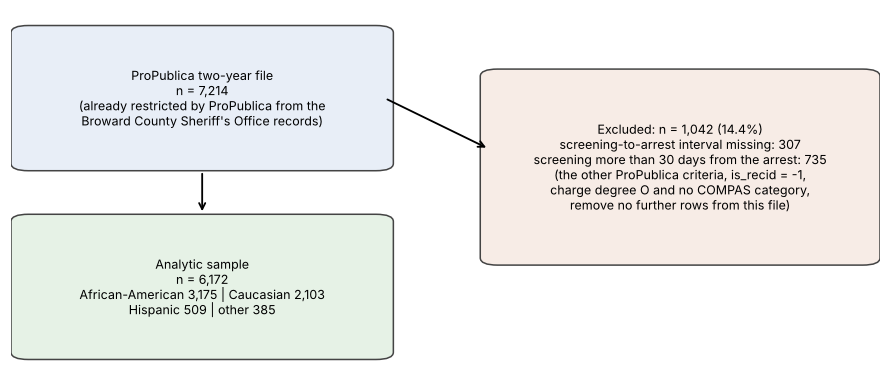

In [43]:
# ===== 11c. Round 2 analyses: setup, sample-selection flow, confusion-matrix counts =====
import hashlib, json, time
g = globals()
OUT2 = {}
def pc2(a, lo=2.5, hi=97.5): return [float(x) for x in np.nanpercentile(a, [lo, hi])]
with open(LOCAL_PATH, 'rb') as fh: OUT2['data_sha256'] = hashlib.sha256(fh.read()).hexdigest()
print('dataset sha256:', OUT2['data_sha256'])

# (i) sample-selection flow: apply ProPublica's criteria one at a time to the 7,214-row file
steps = [('Rows in the ProPublica two-year file', lambda f: np.ones(len(f), bool)),
         ('days_b_screening_arrest within +/-30 days of the COMPAS screening', lambda f: (f['days_b_screening_arrest'] <= 30) & (f['days_b_screening_arrest'] >= -30)),
         ('is_recid != -1 (recidivism information available)', lambda f: f['is_recid'] != -1),
         ('Ordinary traffic offences excluded (c_charge_degree != O)', lambda f: f['c_charge_degree'] != 'O'),
         ('COMPAS risk category available (score_text != N/A)', lambda f: f['score_text'] != 'N/A')]
keep = np.ones(len(pd.read_csv(LOCAL_PATH)), bool); flow = []
df_ = pd.read_csv(LOCAL_PATH); df_['race_grp'] = np.where(df_['race'].isin([AA, CA, 'Hispanic']), df_['race'], 'Other')
for lab, fn in steps:
    k = fn(df_).values if hasattr(fn(df_), 'values') else fn(df_)
    new = keep & k; removed = keep & ~new
    flow.append(dict(step=lab, n_after=int(new.sum()), removed=int(removed.sum()),
                     removed_by_race={r_: int((removed & (df_['race_grp'] == r_).values).sum()) for r_ in [AA, CA, 'Hispanic', 'Other']}))
    keep = new
assert keep.sum() == len(d), (keep.sum(), len(d))
OUT2['flow'] = flow
# non-exclusive view: how many rows fail each criterion on its own (rows can fail several)
OUT2['fail_each'] = {lab: int((~fn(df_)).sum()) for lab, fn in steps[1:]}
print('rows failing each criterion on its own:', OUT2['fail_each'])
for f in flow: print(f['n_after'], f['removed'], f['removed_by_race'], f['step'])

# excluded vs retained, by race and on key variables
exc, inc = df_[~keep], df_[keep]
def prof(f):
    return dict(n=len(f), pct_AA=100*(f.race == AA).mean(), pct_CA=100*(f.race == CA).mean(), pct_H=100*(f.race == 'Hispanic').mean(),
                pct_male=100*(f.sex == 'Male').mean(), age_mean=f.age.mean(), priors_mean=f.priors_count.mean(), recid=f.two_year_recid.mean(),
                decile_mean=f.decile_score.mean())
OUT2['excluded_profile'] = prof(exc); OUT2['retained_profile'] = prof(inc)
print('excluded', {k: round(v, 3) for k, v in OUT2['excluded_profile'].items()})
print('retained', {k: round(v, 3) for k, v in OUT2['retained_profile'].items()})
_a = ((~keep) & (df_.race == AA).values).sum(); _c = ((~keep) & (df_.race == CA).values).sum()
_t = st.chi2_contingency(np.array([[_a, (df_.race == AA).sum() - _a], [_c, (df_.race == CA).sum() - _c]]))
OUT2['excl_AA_vs_CA'] = dict(p=float(_t[1]), rate_aa=float(_a / (df_.race == AA).sum()), rate_ca=float(_c / (df_.race == CA).sum()))
print('AA vs CA exclusion rate:', OUT2['excl_AA_vs_CA'])
ct = pd.crosstab(~keep, df_['race_grp']); chi = st.chi2_contingency(ct)
OUT2['excl_race_chi2'] = dict(chi2=float(chi[0]), p=float(chi[1]), dof=int(chi[2]))
# does exclusion differ by race, conditional on being in the file? exclusion rate by group + recidivism among excluded
OUT2['excl_rate_by_race'] = {r_: float((~keep & (df_.race_grp == r_).values).sum() / (df_.race_grp == r_).sum()) for r_ in [AA, CA, 'Hispanic', 'Other']}
OUT2['excl_recid_by_race'] = {r_: (float(exc[exc.race_grp == r_].two_year_recid.mean()) if (exc.race_grp == r_).sum() else None) for r_ in [AA, CA, 'Hispanic', 'Other']}
print('exclusion rate by race', OUT2['excl_rate_by_race'], '| chi2', OUT2['excl_race_chi2'])
print('recid among excluded by race', OUT2['excl_recid_by_race'])

# (ii) confusion-matrix counts by group (test set, race-blind models and COMPAS) and pooled out-of-fold
def cm(y_, d_, m_):
    return dict(TN=int(((y_ == 0) & (d_ == 0) & m_).sum()), FP=int(((y_ == 0) & (d_ == 1) & m_).sum()),
                FN=int(((y_ == 1) & (d_ == 0) & m_).sum()), TP=int(((y_ == 1) & (d_ == 1) & m_).sum()))
OUT2['confusion'] = {'test': {}, 'oof': {}}
for m in ['Random Forest', 'XGBoost', 'Logistic regression', 'COMPAS']:
    dd = (dect >= 5).astype(int) if m == 'COMPAS' else (S[m] >= .5).astype(int)
    OUT2['confusion']['test'][m] = {AA: cm(yt, dd, isAA), CA: cm(yt, dd, isCA)}
dC_f = (decv >= 5).astype(int)
for m in ['Random Forest', 'XGBoost', 'Logistic regression', 'COMPAS']:
    dd = dC_f if m == 'COMPAS' else (oof[m] >= .5).astype(int)
    OUT2['confusion']['oof'][m] = {AA: cm(yv, dd, isAA_f), CA: cm(yv, dd, isCA_f)}
for sp in ('test', 'oof'):
    print(sp, {m: {gg: tuple(v.values()) for gg, v in z.items()} for m, z in OUT2['confusion'][sp].items()})

# (iii) flow diagram of the sample selection
fig, ax = plt.subplots(figsize=(8.2, 3.6)); ax.axis('off')
def box(x, y, w, h, txt, fc):
    ax.add_patch(mpatches.FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.02', fc=fc, ec='#444444', lw=1)); ax.text(x + w/2, y + h/2, txt, ha='center', va='center', fontsize=8.2)
ex = OUT2['excluded_profile']; n_ex = ex['n']
box(0.02, 0.58, 0.40, 0.36, f"ProPublica two-year file\nn = {len(df_):,}\n(already restricted by ProPublica from the\nBroward County Sheriff's Office records)", '#e8eef7')
box(0.02, 0.06, 0.40, 0.36, f"Analytic sample\nn = {int(keep.sum()):,}\nAfrican-American {int((df_[keep].race==AA).sum()):,} | Caucasian {int((df_[keep].race==CA).sum()):,}\nHispanic {int((df_[keep].race=='Hispanic').sum()):,} | other {int((~df_[keep].race.isin([AA,CA,'Hispanic'])).sum()):,}", '#e6f2e6')
_dbs = df_['days_b_screening_arrest']; OUT2['dbs_missing'] = int(_dbs.isna().sum()); OUT2['dbs_outside'] = int(((_dbs > 30) | (_dbs < -30)).sum())
print('screening-to-arrest interval: missing', OUT2['dbs_missing'], '| outside +/-30 days', OUT2['dbs_outside'])
box(0.56, 0.32, 0.42, 0.50, f"Excluded: n = {n_ex:,} ({100*n_ex/len(df_):.1f}%)\nscreening-to-arrest interval missing: {OUT2['dbs_missing']:,}\nscreening more than 30 days from the arrest: {OUT2['dbs_outside']:,}\n(the other ProPublica criteria, is_recid = -1,\ncharge degree O and no COMPAS category,\nremove no further rows from this file)", '#f7ece6')
ax.annotate('', xy=(0.22, 0.44), xytext=(0.22, 0.56), arrowprops=dict(arrowstyle='->', lw=1.2)); ax.annotate('', xy=(0.55, 0.62), xytext=(0.43, 0.76), arrowprops=dict(arrowstyle='->', lw=1.2))
ax.set_xlim(0, 1); ax.set_ylim(0, 1); plt.tight_layout(); savefig('figA1_sample_flow'); plt.show()


### 14.2 Reweighting diagnostics: weights, effective sample size, covariate balance, trimming and alternative specifications

In [44]:
# ===== 11c.2 Reweighting diagnostics, trimming, alternative specifications (Round 2, comment 2) =====
from sklearn.preprocessing import SplineTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, GradientBoostingRegressor
from joblib import Parallel, delayed
mask = isAA_f | isCA_f
Xm = X[mask].reset_index(drop=True); ym = yv[mask]; aam = isAA_f[mask]
dR = (oof['Random Forest'][mask] >= .5).astype(int); dCm = (decv[mask] >= 5).astype(int)
pri = Xm['priors_count'].values.astype(float); age_ = Xm['age'].values.astype(float)

def feat(Xd, spec):
    p = Xd['priors_count'].values.astype(float); a = Xd['age'].values.astype(float); lp = np.log1p(p)
    if spec == 'linear':   F = np.column_stack([lp, p, a, a**2])
    elif spec == 'spline':
        F1 = SplineTransformer(n_knots=5, degree=3).fit(a[:, None]).transform(a[:, None])
        F2 = SplineTransformer(n_knots=5, degree=3).fit(lp[:, None]).transform(lp[:, None])
        zs = lambda v: (v - v.mean()) / v.std()
        F = np.column_stack([F1, F2, zs(a) * zs(lp)])
    elif spec == 'all7':   F = np.column_stack([lp, p, a, a**2] + [Xd[c].values.astype(float) for c in Xd.columns if c not in ('priors_count', 'age')])
    elif spec == 'priors': F = np.column_stack([lp, p])
    elif spec == 'age':    F = np.column_stack([a, a**2])
    else:                  F = np.column_stack([a])
    return (F - F.mean(0)) / np.where(F.std(0) > 0, F.std(0), 1)

def weights(Xd, y_, a_, spec, trim=None, C=1e6):
    # odds weights for Caucasian non-recidivists (reweighting them to the African-American non-recidivist distribution)
    neg = (y_ == 0); F = feat(Xd, spec)
    if spec == 'gb':
        pr = np.zeros(len(y_))
        pr[neg] = cross_val_predict(HistGradientBoostingClassifier(max_depth=3, max_iter=100, learning_rate=.05, random_state=SEED),
                                    Xd.values[neg], a_[neg].astype(int), cv=5, method='predict_proba')[:, 1]
    else:
        mdl = LogisticRegression(C=C, max_iter=1000).fit(F[neg], a_[neg]); pr = mdl.predict_proba(F)[:, 1]
    pr = np.clip(pr, 1e-3, 1 - 1e-3); w = pr / (1 - pr)
    cn = neg & ~a_
    if trim is not None:
        cap = np.percentile(w[cn], trim); w = np.minimum(w, cap)
    return w, neg, cn

def share_closed(Xd, y_, a_, d_, spec, trim=None, C=1e6):
    w, neg, cn = weights(Xd, y_, a_, spec, trim, C); an = neg & a_
    fa, fc = d_[an].mean(), d_[cn].mean(); fcf = (w[cn] * d_[cn]).sum() / w[cn].sum()
    return (fcf - fc) / (fa - fc), fcf, fa, fc

def boot_share(spec, d_, trim=None, B_=300, C=1e6, seed=SEED + 7):
    rg = np.random.default_rng(seed); ix = rg.integers(0, len(ym), size=(B_, len(ym)))
    def one(i):
        try: return share_closed(Xm.iloc[i].reset_index(drop=True), ym[i], aam[i], d_[i], spec, trim, C)[0]
        except Exception: return np.nan
    return np.array(Parallel(n_jobs=2)(delayed(one)(i) for i in ix))

T0 = time.time(); OUT2['rw'] = {'diag': {}, 'share': {}}
# ---- diagnostics for the cell-based weights (main bins) and the parametric (linear-logit) weights ----
pb = pd.cut(pri, [-1, 0, 1, 2, 4, 7, 100], labels=False).astype(int); ab = pd.cut(age_, [0, 24, 34, 44, 100], labels=False).astype(int)
cellc = pb * 4 + ab; neg = (ym == 0)
nA = np.bincount(cellc[neg & aam], minlength=24); nC = np.bincount(cellc[neg & ~aam], minlength=24)
wcell = np.where(nC > 0, (nA / nA.sum()) / np.maximum(nC / nC.sum(), 1e-12), 0)
wi = wcell[cellc[neg & ~aam]]
kish = lambda w: float(w.sum()**2 / (w**2).sum())
OUT2['rw']['diag']['cells'] = dict(n_cells=int((nA + nC > 0).sum()), cells_lt10_C=int(((nC < 10) & (nA + nC > 0)).sum()), cells_lt5_C=int(((nC < 5) & (nA + nC > 0)).sum()),
    min_nonzero_C=int(nC[nC > 0].min()), aa_nonrecid_in_cells_lt10_C=int(nA[nC < 10].sum()), aa_nonrecid=int(nA.sum()), ca_nonrecid=int(nC.sum()),
    ess=kish(wi), max_w=float(wi.max()), w_p99=float(np.percentile(wi, 99)), top_cell_weight_share=float((wcell * nC).max() / (wcell * nC).sum()))
print('cell weights:', OUT2['rw']['diag']['cells'])

def smd(v, a_, w=None, neg_=None):
    # standardized mean difference AA vs Caucasian non-recidivists, Caucasian optionally weighted
    A = v[neg_ & a_]; Cc = v[neg_ & ~a_]
    mC = np.average(Cc, weights=w[neg_ & ~a_]) if w is not None else Cc.mean()
    return (A.mean() - mC) / np.sqrt((A.var(ddof=1) + Cc.var(ddof=1)) / 2)

covs = {'Age': age_, 'Prior charges': pri, 'log(1+prior charges)': np.log1p(pri), 'Juvenile felonies': Xm['juv_fel_count'].values.astype(float),
        'Juvenile misdemeanors': Xm['juv_misd_count'].values.astype(float), 'Juvenile other': Xm['juv_other_count'].values.astype(float),
        'Felony charge': Xm['c_charge_degree_M'].values.astype(float) * -1 + 1 if 'c_charge_degree_M' in Xm else np.zeros(len(Xm)),
        'Male': Xm['sex_Male'].values.astype(float)}
bal = {}
wpar, negp, cnp = weights(Xm, ym, aam, 'linear')
OUT2['rw']['diag']['param'] = dict(w_min=float(wpar[cnp].min()), w_p50=float(np.percentile(wpar[cnp], 50)), w_p95=float(np.percentile(wpar[cnp], 95)),
    w_p99=float(np.percentile(wpar[cnp], 99)), w_max=float(wpar[cnp].max()), ess=kish(wpar[cnp]), n_ca_nonrecid=int(cnp.sum()),
    ess_share=float(kish(wpar[cnp]) / cnp.sum()), top5_weight_share=float(np.sort(wpar[cnp])[-5:].sum() / wpar[cnp].sum()))
print('parametric weights:', {k: round(v, 3) for k, v in OUT2['rw']['diag']['param'].items()})
wfull = np.zeros(len(ym)); wfull[:] = 1.0; wfull[cnp] = wpar[cnp]
wcellfull = np.ones(len(ym)); wcellfull[neg & ~aam] = wi
for nm, v in covs.items():
    bal[nm] = dict(before=float(smd(v, aam, None, neg)), after_param=float(smd(v, aam, wfull, neg)), after_cell=float(smd(v, aam, wcellfull, neg)))
OUT2['rw']['diag']['balance'] = bal
print(pd.DataFrame(bal).T.round(3))

# ---- shares closed under alternative specifications, trimming, and propensity models (RF and COMPAS) ----
specs = [('linear logit, untrimmed', 'linear', None), ('linear logit, weights capped at 99th pct', 'linear', 99), ('linear logit, weights capped at 95th pct', 'linear', 95),
         ('spline logit (age, log priors, interaction)', 'spline', None), ('spline logit, capped at 99th pct', 'spline', 99),
         ('gradient-boosting propensity (cross-fitted)', 'gb', None)]
for dn, dd_ in (('RF', dR), ('COMPAS', dCm)):
    for lab, sp, tr in specs:
        pt = share_closed(Xm, ym, aam, dd_, sp, tr)
        nb_ = 200 if sp == 'gb' else 300
        bt = boot_share(sp, dd_, tr, B_=nb_)
        OUT2['rw']['share'][f'{dn}|{lab}'] = dict(closed=float(pt[0]), ci=pc2(bt), fpr_cf=float(pt[1]), fpr_aa=float(pt[2]), fpr_ca=float(pt[3]), n_boot=int(np.isfinite(bt).sum()))
        print(f'{dn:7s} {lab:48s} {pt[0]:.2f} [{np.nanpercentile(bt,2.5):.2f}, {np.nanpercentile(bt,97.5):.2f}]  ({time.time()-T0:.0f}s)')
json.dump(OUT2, open(f'{OUT_DIR}/round2_analyses.json', 'w'), indent=1, default=lambda o: o.item() if hasattr(o, 'item') else str(o))


cell weights: {'n_cells': 24, 'cells_lt10_C': 2, 'cells_lt5_C': 2, 'min_nonzero_C': 2, 'aa_nonrecid_in_cells_lt10_C': 8, 'aa_nonrecid': 1514, 'ca_nonrecid': 1281, 'ess': 929.1728788345498, 'max_w': 3.5254293262879792, 'w_p99': 3.0217965653896965, 'top_cell_weight_share': 0.13143989431968295}
parametric weights: {'w_min': 0.181, 'w_p50': 1.063, 'w_p95': 2.516, 'w_p99': 4.48, 'w_max': 13.759, 'ess': 818.268, 'n_ca_nonrecid': 1281, 'ess_share': 0.639, 'top5_weight_share': 0.029}
                       before  after_param  after_cell
Age                    -0.432        0.019      -0.036
Prior charges           0.342       -0.039       0.060
log(1+prior charges)    0.327       -0.037       0.021
Juvenile felonies       0.136        0.043       0.065
Juvenile misdemeanors   0.132       -0.016       0.040
Juvenile other         -0.062       -0.232      -0.175
Felony charge           0.200        0.094       0.102
Male                    0.035       -0.006      -0.008


RF      linear logit, untrimmed                          1.21 [1.03, 1.43]  (1s)


RF      linear logit, weights capped at 99th pct         1.14 [0.96, 1.35]  (2s)


RF      linear logit, weights capped at 95th pct         1.00 [0.80, 1.19]  (2s)


RF      spline logit (age, log priors, interaction)      1.06 [0.90, 1.22]  (4s)


RF      spline logit, capped at 99th pct                 0.98 [0.84, 1.13]  (6s)


... (3 outputs left out)

COMPAS  linear logit, weights capped at 95th pct         0.48 [0.36, 0.61]  (28s)


COMPAS  spline logit (age, log priors, interaction)      0.52 [0.40, 0.65]  (30s)


COMPAS  spline logit, capped at 99th pct                 0.46 [0.36, 0.58]  (32s)


COMPAS  gradient-boosting propensity (cross-fitted)      0.60 [0.38, 0.80]  (51s)


### 14.3 Interpreting the part of COMPAS's gap that age and prior charges do not close: alternative cut-offs and a flexible emulator

In [45]:
# ===== 11c.3 Interpreting the unexplained part of COMPAS's gap (Round 2, comment 3) =====
from sklearn.ensemble import HistGradientBoostingRegressor, HistGradientBoostingClassifier
from sklearn.model_selection import KFold
from scipy.stats import spearmanr
def share_cell(y_, a_, d_, cc):
    neg = (y_ == 0); k = cc.max() + 1
    wa = np.bincount(cc[neg & a_], minlength=k).astype(float); wc = np.bincount(cc[neg & ~a_], minlength=k).astype(float)
    fc = np.bincount(cc[neg & ~a_ & (d_ == 1)], minlength=k).astype(float); sup = (wa > 0) & (wc > 0)
    pa = wa / wa.sum(); fcf = (pa[sup] * np.where(wc[sup] > 0, fc[sup] / wc[sup], 0)).sum() / pa[sup].sum()
    fa = (d_[neg & a_] == 1).mean(); fcc = (d_[neg & ~a_] == 1).mean()
    return (fcf - fcc) / (fa - fcc), fa, fcc
rgb = np.random.default_rng(SEED + 11); ixb = rgb.integers(0, len(ym), size=(1000, len(ym)))
def cell_ci(d_):
    pt = share_cell(ym, aam, d_, cellc); bs = np.array([share_cell(ym[i], aam[i], d_[i], cellc[i])[0] for i in ixb])
    return pt, pc2(bs)

# (a) alternative cut-offs of the COMPAS decile score, and the race-blind RF at the matched flag rate
OUT2['compas_cut'] = {}
for cut in (4, 5, 6, 7, 8):
    dc_ = (decv[mask] >= cut).astype(int); fl = dc_.mean(); t_ = np.quantile(oof['Random Forest'][mask], 1 - fl); dr_ = (oof['Random Forest'][mask] >= t_).astype(int)
    (sc, fa, fcc), cic = cell_ci(dc_); (sr, fra, frc), cir = cell_ci(dr_)
    OUT2['compas_cut'][cut] = dict(flag=float(fl), compas=dict(fpr_aa=float(fa), fpr_ca=float(fcc), ratio=float(fa/fcc), gap=float(fa-fcc), closed=float(sc), ci=cic),
                                   rf=dict(fpr_aa=float(fra), fpr_ca=float(frc), ratio=float(fra/frc), gap=float(fra-frc), closed=float(sr), ci=cir, thr=float(t_)))
    print(f'decile>={cut}: flag {fl:.3f} | COMPAS FPR {fa:.3f}/{fcc:.3f} gap {fa-fcc:.3f} closed {sc:.2f} {cic} | RF(matched) gap {fra-frc:.3f} closed {sr:.2f} {cir}')

# (b) how well can the seven public inputs reproduce COMPAS? (cross-fitted flexible emulator)
Xv = X.values; kf = KFold(5, shuffle=True, random_state=SEED)
emu = np.zeros(len(yv))
for tr, te in kf.split(Xv):
    emu[te] = HistGradientBoostingRegressor(max_depth=4, max_iter=200, learning_rate=.05, random_state=SEED).fit(Xv[tr], decv[tr]).predict(Xv[te]) if 'HistGradientBoostingRegressor' in globals() else 0
r2 = 1 - ((decv - emu)**2).sum() / ((decv - decv.mean())**2).sum(); rho = spearmanr(decv, emu)[0]
flag_c = (decv >= 5).astype(int); emu_flag = np.zeros(len(yv))
for tr, te in kf.split(Xv):
    emu_flag[te] = HistGradientBoostingClassifier(max_depth=4, max_iter=200, learning_rate=.05, random_state=SEED).fit(Xv[tr], flag_c[tr]).predict_proba(Xv[te])[:, 1]
OUT2['emulator'] = dict(r2=float(r2), spearman=float(rho), auc_flag=float(roc_auc_score(flag_c, emu_flag)), acc_flag=float(((emu_flag >= .5) == flag_c).mean()),
                        mae_decile=float(np.abs(decv - emu).mean()), within1=float((np.abs(decv - emu) <= 1).mean()))
print('emulator:', OUT2['emulator'])
d_em = (emu_flag[mask] >= .5).astype(int); (se_, fa_, fc_), ci_em = cell_ci(d_em)
OUT2['emulator']['flag_gap'] = dict(fpr_aa=float(fa_), fpr_ca=float(fc_), closed=float(se_), ci=ci_em)
print(f'emulator flags: FPR {fa_:.3f}/{fc_:.3f}, share closed {se_:.2f} {ci_em}')
# residual: do COMPAS flags exceed what the seven inputs predict, by race, among non-recidivists?
res = flag_c - emu_flag; neg_all = (yv == 0)
def resid_by_race(ix):
    return [res[ix][(neg_all & isAA_f)[ix]].mean(), res[ix][(neg_all & isCA_f)[ix]].mean()]
pt = resid_by_race(np.arange(len(yv))); bt = np.array([resid_by_race(i) for i in idx_full[:1000]])
OUT2['emulator']['resid_nonrecid'] = dict(aa=float(pt[0]), ca=float(pt[1]), diff=float(pt[0]-pt[1]), diff_ci=pc2(bt[:, 0] - bt[:, 1]), aa_ci=pc2(bt[:, 0]), ca_ci=pc2(bt[:, 1]))
print('flag residual among non-recidivists (AA, CA, diff):', [round(x, 3) for x in pt], '| diff CI', OUT2['emulator']['resid_nonrecid']['diff_ci'])
json.dump(OUT2, open(f'{OUT_DIR}/round2_analyses.json', 'w'), indent=1, default=lambda o: o.item() if hasattr(o, 'item') else str(o))


decile>=4: flag 0.588 | COMPAS FPR 0.542/0.333 gap 0.208 closed 0.63 [0.5111027005514501, 0.7616362785225863] | RF(matched) gap 0.188 closed 0.96 [0.8502546995419332, 1.0858848623292927]


decile>=5: flag 0.478 | COMPAS FPR 0.423/0.220 gap 0.203 closed 0.46 [0.35175868628793444, 0.5705238771077793] | RF(matched) gap 0.163 closed 0.99 [0.8592040751812466, 1.139485264065802]


decile>=6: flag 0.379 | COMPAS FPR 0.314/0.135 gap 0.179 closed 0.38 [0.2700566092311228, 0.5064683861305384] | RF(matched) gap 0.131 closed 1.01 [0.8542682710889835, 1.1804096889827487]


decile>=7: flag 0.289 | COMPAS FPR 0.228/0.083 gap 0.145 closed 0.32 [0.2034829878587082, 0.459869822280054] | RF(matched) gap 0.112 closed 0.80 [0.6448627029120706, 0.9949792643909765]


decile>=8: flag 0.202 | COMPAS FPR 0.139/0.048 gap 0.092 closed 0.32 [0.1799731150813376, 0.4953601418819216] | RF(matched) gap 0.061 closed 0.95 [0.6862895377289584, 1.32189394069114]


emulator: {'r2': 0.47757225521919033, 'spearman': 0.7029229259844294, 'auc_flag': 0.8270970211889679, 'acc_flag': 0.7555087491898899, 'mae_decile': 1.620714864471307, 'within1': 0.37508101101749836}
emulator flags: FPR 0.331/0.166, share closed 0.81 [0.6917985525826009, 0.9540897861574834]
flag residual among non-recidivists (AA, CA, diff): [np.float64(0.011), np.float64(-0.062)] | diff CI [0.04111439132566535, 0.10388940734539104]


### 14.4 Equalized-odds post-processing: training versus test rates, interval estimates, equivalence test and 50 repeated splits

In [46]:
# ===== 11c.4 Equalized odds after post-processing: uncertainty, training vs test, equivalence, repeated splits (Round 2, comment 4) =====
from scipy.optimize import linprog
from sklearn.metrics import roc_curve
def eo_fit(Xtr_, ytr_, rtr_, seed_, n_jobs_=1):
    m = RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=20, random_state=seed_, class_weight='balanced', n_jobs=n_jobs_)
    oof_ = cross_val_predict(m, Xtr_, ytr_, cv=5, method='predict_proba')[:, 1]
    m.fit(Xtr_, ytr_)
    gA_, gC_ = (rtr_ == AA), (rtr_ == CA)
    fA_, tA_, hA_ = roc_curve(ytr_[gA_], oof_[gA_]); fC_, tC_, hC_ = roc_curve(ytr_[gC_], oof_[gC_])
    nA_, nC_ = len(fA_), len(fC_); pA_, pC_ = ytr_[gA_].mean(), ytr_[gC_].mean(); wA_, wC_ = gA_.sum(), gC_.sum()
    cobj = np.r_[-(wA_ * (pA_ * tA_ - (1 - pA_) * fA_)), -(wC_ * (pC_ * tC_ - (1 - pC_) * fC_))]
    Aeq = np.zeros((4, nA_ + nC_)); beq = np.zeros(4)
    Aeq[0, :nA_] = 1; beq[0] = 1; Aeq[1, nA_:] = 1; beq[1] = 1; Aeq[2, :nA_] = fA_; Aeq[2, nA_:] = -fC_; Aeq[3, :nA_] = tA_; Aeq[3, nA_:] = -tC_
    lam_ = linprog(cobj, A_eq=Aeq, b_eq=beq, bounds=(0, 1), method='highs').x
    lA_, lC_ = lam_[:nA_], lam_[nA_:]
    # parity thresholds: Caucasian at 0.5, African-American at the value that equalises training FPR
    fpr_at_ = lambda s, y, t: ((s >= t) & (y == 0)).sum() / (y == 0).sum()
    target = fpr_at_(oof_[gC_], ytr_[gC_], .5); grid = np.linspace(.3, .95, 651); tauA_ = min(grid, key=lambda t: abs(fpr_at_(oof_[gA_], ytr_[gA_], t) - target))
    train_rates = dict(fpr_aa=float(lA_ @ fA_), tpr_aa=float(lA_ @ tA_), fpr_ca=float(lC_ @ fC_), tpr_ca=float(lC_ @ tC_))
    return m, (hA_, lA_, hC_, lC_), tauA_, train_rates
def eo_apply(m, par, tauA_, Xte_, rte_):
    hA_, lA_, hC_, lC_ = par; s = m.predict_proba(Xte_)[:, 1]
    pp = lambda sc, th, l: sum(l[i] * (sc >= th[i]) for i in range(len(th)) if l[i] > 1e-9)
    q = (s >= .5).astype(float); a_, c_ = (rte_ == AA), (rte_ == CA)
    qe = q.copy(); qe[a_] = pp(s[a_], hA_, lA_); qe[c_] = pp(s[c_], hC_, lC_)
    qp = q.copy(); qp[a_] = (s[a_] >= tauA_).astype(float)
    return s, q, qe, qp
def grp_rates(y_, q_, a_, c_):
    f = lambda gm: dict(fpr=(q_ * ((y_ == 0) & gm)).sum() / ((y_ == 0) & gm).sum(), fnr=((1 - q_) * ((y_ == 1) & gm)).sum() / ((y_ == 1) & gm).sum(),
                       ppv=(q_ * ((y_ == 1) & gm)).sum() / (q_ * gm).sum(), flag=(q_ * gm).sum() / gm.sum())
    A, C_ = f(a_), f(c_); sub_ = a_ | c_
    acc = (q_ * y_ + (1 - q_) * (1 - y_))[sub_].mean()
    return dict(A=A, C=C_, fpr_ratio=A['fpr'] / C_['fpr'], fpr_diff=A['fpr'] - C_['fpr'], fnr_diff=A['fnr'] - C_['fnr'], fnr_ratio=A['fnr'] / C_['fnr'],
                tpr_diff=C_['fnr'] - A['fnr'], ppv_diff=A['ppv'] - C_['ppv'], acc=acc)

# ---- main split: the rule of Section 4.10 (refitted here to expose training-set and test-set rates) ----
race_all = np.asarray(race); assert len(race_all) == len(yv); ti = np.asarray(X_te.index); tri = np.asarray(X_tr.index)
yt = yv[ti]; rt = race_all[ti]; isAA = (rt == AA); isCA = (rt == CA); dect = decv[ti]
assert idx.shape[1] == len(yt), (idx.shape, len(yt))
ytr_a = yv[tri]; rtr_a = race_all[tri]; ytr_dummy = None
 
m0, par0, tau0, trr0 = eo_fit(X_tr, ytr_a, rtr_a, SEED)
s0, q0, qe0, qp0 = eo_apply(m0, par0, tau0, X_te, rt)
print('training-set rates under the learned rule (African-American / Caucasian): FPR %.3f / %.3f, TPR %.3f / %.3f' % (trr0['fpr_aa'], trr0['fpr_ca'], trr0['tpr_aa'], trr0['tpr_ca']))
OUT2['eo'] = {'train_rates': trr0}
def boot_rates(q_, ix):
    out = {k: [] for k in ('fpr_ratio', 'fpr_diff', 'fnr_diff', 'fnr_ratio', 'tpr_diff', 'ppv_diff', 'acc', 'fpr_aa', 'fpr_ca', 'fnr_aa', 'fnr_ca')}
    for i in ix:
        r_ = grp_rates(yt[i], q_[i], isAA[i], isCA[i])
        for k in ('fpr_ratio', 'fpr_diff', 'fnr_diff', 'fnr_ratio', 'tpr_diff', 'ppv_diff', 'acc'): out[k].append(r_[k])
        out['fpr_aa'].append(r_['A']['fpr']); out['fpr_ca'].append(r_['C']['fpr']); out['fnr_aa'].append(r_['A']['fnr']); out['fnr_ca'].append(r_['C']['fnr'])
    return {k: np.array(v) for k, v in out.items()}
ix1000 = idx[:1000]
tol = dict(ratio=(0.80, 1.25), diff=0.05)
for name, q_ in (('baseline', q0), ('equalized_odds', qe0), ('fpr_parity', qp0)):
    pt = grp_rates(yt, q_, isAA, isCA); bt = boot_rates(q_, ix1000)
    rec = dict(point={k: float(v) for k, v in pt.items() if not isinstance(v, dict)}, A=pt['A'], C=pt['C'], ci={k: pc2(v) for k, v in bt.items()}, ci90={k: pc2(v, 5, 95) for k, v in bt.items()})
    rec['equiv'] = dict(fpr_ratio=bool(rec['ci90']['fpr_ratio'][0] >= tol['ratio'][0] and rec['ci90']['fpr_ratio'][1] <= tol['ratio'][1]),
                        fpr_diff=bool(abs(rec['ci90']['fpr_diff'][0]) <= tol['diff'] and abs(rec['ci90']['fpr_diff'][1]) <= tol['diff']),
                        fnr_diff=bool(abs(rec['ci90']['fnr_diff'][0]) <= tol['diff'] and abs(rec['ci90']['fnr_diff'][1]) <= tol['diff']))
    OUT2['eo'][name] = rec
    print(f"{name:15s} FPR AA/CA {pt['A']['fpr']:.3f}/{pt['C']['fpr']:.3f} ratio {pt['fpr_ratio']:.2f} {rec['ci']['fpr_ratio']} diff {pt['fpr_diff']:+.3f} {rec['ci']['fpr_diff']} | FNR AA/CA {pt['A']['fnr']:.3f}/{pt['C']['fnr']:.3f} diff {pt['fnr_diff']:+.3f} {rec['ci']['fnr_diff']} | TPR diff {pt['tpr_diff']:+.3f} | PPV {pt['A']['ppv']:.3f}/{pt['C']['ppv']:.3f} | acc {pt['acc']:.3f} | equiv {rec['equiv']}")
OUT2['eo']['tolerance'] = tol

# ---- repeated splits: the rule is refitted on every training partition and evaluated on the held-out partition ----
def one_split(seed_):
    Xtr_, Xte_, ytr_, yte_, rtr_, rte_ = train_test_split(X, y, race, test_size=.3, random_state=seed_, stratify=y)
    ytr_, yte_, rtr_, rte_ = np.asarray(ytr_), np.asarray(yte_), np.asarray(rtr_), np.asarray(rte_)
    m_, par_, tau_, trr_ = eo_fit(Xtr_, ytr_, rtr_, seed_)
    s_, q_, qe_, qp_ = eo_apply(m_, par_, tau_, Xte_, rte_); a_, c_ = (rte_ == AA), (rte_ == CA); out = {'seed': seed_, 'train_fpr_gap': trr_['fpr_aa'] - trr_['fpr_ca'], 'train_tpr_gap': trr_['tpr_aa'] - trr_['tpr_ca']}
    for nm, qq in (('base', q_), ('eo', qe_), ('par', qp_)):
        r_ = grp_rates(yte_, qq, a_, c_)
        out.update({f'{nm}_fpr_ratio': r_['fpr_ratio'], f'{nm}_fpr_diff': r_['fpr_diff'], f'{nm}_fnr_diff': r_['fnr_diff'], f'{nm}_fnr_ratio': r_['fnr_ratio'], f'{nm}_ppv_diff': r_['ppv_diff'],
                    f'{nm}_acc': r_['acc'], f'{nm}_fpr_ca': r_['C']['fpr'], f'{nm}_fpr_aa': r_['A']['fpr'], f'{nm}_ppv_aa': r_['A']['ppv'], f'{nm}_ppv_ca': r_['C']['ppv'],
                    f'{nm}_fnr_aa': r_['A']['fnr'], f'{nm}_fnr_ca': r_['C']['fnr']})
    out['n_train'], out['n_test'] = len(ytr_), len(yte_)
    return out
T0 = time.time()
res_eo = Parallel(n_jobs=2)(delayed(one_split)(s_) for s_ in range(1000, 1050))
dfe = pd.DataFrame(res_eo); dfe.to_csv(f'{OUT_DIR}/eo_repeated_splits_50.csv', index=False)
J = len(dfe); fac = 1 / J + dfe.n_test[0] / dfe.n_train[0]; tcr = st.t.ppf(.975, J - 1)
def nbi(v):
    m = v.mean(); se = np.sqrt(fac * v.var(ddof=1)); return dict(mean=float(m), lo=float(m - tcr * se), hi=float(m + tcr * se), sd=float(v.std(ddof=1)))
OUT2['eo']['repeated'] = {c: nbi(dfe[c]) for c in dfe.columns if c not in ('seed', 'n_train', 'n_test')}
OUT2['eo']['repeated']['acc_cost_eo'] = nbi(dfe['base_acc'] - dfe['eo_acc']); OUT2['eo']['repeated']['acc_cost_par'] = nbi(dfe['base_acc'] - dfe['par_acc'])
# equivalence on the repeated splits: 90% corrected interval inside the tolerance?
tc90 = st.t.ppf(.95, J - 1)
for c, lim in (('eo_fpr_diff', .05), ('eo_fnr_diff', .05), ('par_fpr_diff', .05), ('par_fnr_diff', .05)):
    m = dfe[c].mean(); se = np.sqrt(fac * dfe[c].var(ddof=1)); OUT2['eo']['repeated'][c + '_ci90'] = [float(m - tc90 * se), float(m + tc90 * se)]
for c in ('base_fpr_ratio', 'eo_fpr_ratio', 'eo_fpr_diff', 'eo_fnr_diff', 'eo_fnr_ratio', 'eo_ppv_diff', 'base_ppv_diff', 'eo_fpr_ca', 'base_fpr_ca', 'acc_cost_eo', 'par_fpr_ratio', 'par_fnr_diff', 'acc_cost_par'):
    v = OUT2['eo']['repeated'][c]; print(f'{c:15s} {v["mean"]:+.3f} [{v["lo"]:+.3f}, {v["hi"]:+.3f}] sd {v["sd"]:.3f}')
print('training-partition gaps (should be ~0):', dfe.train_fpr_gap.abs().max(), dfe.train_tpr_gap.abs().max(), f'[{time.time()-T0:.0f}s]')
json.dump(OUT2, open(f'{OUT_DIR}/round2_analyses.json', 'w'), indent=1, default=lambda o: o.item() if hasattr(o, 'item') else str(o))


training-set rates under the learned rule (African-American / Caucasian): FPR 0.305 / 0.305, TPR 0.619 / 0.619
baseline        FPR AA/CA 0.400/0.212 ratio 1.88 [1.5421575333340993, 2.3786894422498017] diff +0.188 [0.12885257504773456, 0.24784377919884115] | FNR AA/CA 0.231/0.517 diff -0.286 [-0.3569377985189653, -0.21306937311702626] | TPR diff +0.286 | PPV 0.688/0.574 | acc 0.684 | equiv {'fpr_ratio': False, 'fpr_diff': False, 'fnr_diff': False}
equalized_odds  FPR AA/CA 0.303/0.281 ratio 1.08 [0.891128034326987, 1.3054256540301423] diff +0.021 [-0.03305703530278931, 0.07672492041125228] | FNR AA/CA 0.360/0.438 diff -0.078 [-0.15063242750378575, -0.004473872800468361] | TPR diff +0.078 | PPV 0.708/0.542 | acc 0.664 | equiv {'fpr_ratio': False, 'fpr_diff': False, 'fnr_diff': False}


fpr_parity      FPR AA/CA 0.196/0.212 ratio 0.92 [0.7022379319344565, 1.206148698084373] diff -0.017 [-0.06991209376990347, 0.03784137771410984] | FNR AA/CA 0.466/0.517 diff -0.051 [-0.1240369252559135, 0.029123791001151367] | TPR diff +0.051 | PPV 0.758/0.574 | acc 0.666 | equiv {'fpr_ratio': False, 'fpr_diff': False, 'fnr_diff': False}


base_fpr_ratio  +1.737 [+1.523, +1.950] sd 0.159
eo_fpr_ratio    +0.986 [+0.848, +1.124] sd 0.103
eo_fpr_diff     -0.005 [-0.043, +0.033] sd 0.028
eo_fnr_diff     -0.018 [-0.073, +0.036] sd 0.040
eo_fnr_ratio    +0.962 [+0.841, +1.082] sd 0.090
eo_ppv_diff     +0.134 [+0.084, +0.184] sd 0.037
base_ppv_diff   +0.084 [+0.039, +0.128] sd 0.033
eo_fpr_ca       +0.267 [+0.196, +0.338] sd 0.053
base_fpr_ca     +0.226 [+0.199, +0.252] sd 0.020
acc_cost_eo     +0.021 [+0.010, +0.031] sd 0.008
par_fpr_ratio   +1.010 [+0.842, +1.179] sd 0.125
par_fnr_diff    -0.047 [-0.098, +0.004] sd 0.038
acc_cost_par    +0.011 [+0.000, +0.022] sd 0.008
training-partition gaps (should be ~0): 3.164135620181696e-15 6.5503158452884236e-15 [60s]


### 14.5 Uncertainty: 20,000-replicate simultaneous threshold intervals and retraining-aware out-of-bag intervals

In [47]:
# ===== 11c.5 Uncertainty: 20,000-replicate simultaneous threshold intervals; retraining-aware (out-of-bag) intervals (Round 2, comment 5) =====
T0 = time.time()
def cnts(y_, d_, g_, ix=None):
    if ix is None: ix = np.arange(len(y_))[None, :]
    yb, db, gb = y_[ix], d_[ix], g_[ix]
    neg, pos, pp = (yb == 0) & gb, (yb == 1) & gb, (db == 1) & gb
    fp = (neg & (db == 1)).sum(1); nneg = neg.sum(1); fn = (pos & (db == 0)).sum(1); npos = pos.sum(1); tp = (pos & (db == 1)).sum(1); npp = pp.sum(1)
    with np.errstate(divide='ignore', invalid='ignore'): return dict(FPR=fp/nneg, FNR=fn/npos, PPV=tp/npp, FP=fp, FLAG=npp/gb.sum(1))
p_rf = S['Random Forest']; thr = np.round(np.arange(0.20, 0.801, 0.05), 2); alpha = 0.05 / len(thr)
def sweep_big(B_=20000, chunk=2500, seed_=SEED + 5):
    rg = np.random.default_rng(seed_); R_ = {t: [] for t in thr}; D_ = {t: [] for t in thr}
    for _ in range(B_ // chunk):
        ix = rg.integers(0, len(yt), size=(chunk, len(yt)), dtype=np.int32)
        for t in thr:
            dd = (p_rf >= t).astype(int); a, c = cnts(yt, dd, isAA, ix), cnts(yt, dd, isCA, ix)
            with np.errstate(divide='ignore', invalid='ignore'): R_[t].append(a['FPR'] / c['FPR'])
            D_[t].append(a['FPR'] - c['FPR'])
    return {t: np.concatenate(R_[t]) for t in thr}, {t: np.concatenate(D_[t]) for t in thr}
Rb, Db = sweep_big()
rows = []
for t in thr:
    dd = (p_rf >= t).astype(int); a, c = cnts(yt, dd, isAA), cnts(yt, dd, isCA); r2k = cnts(yt, dd, isAA, idx)['FPR'] / cnts(yt, dd, isCA, idx)['FPR']
    lo_, hi_ = 100 * alpha / 2, 100 * (1 - alpha / 2)
    rows.append(dict(t=float(t), ratio=float(a['FPR'][0] / c['FPR'][0]), lo2k=float(np.nanpercentile(r2k, lo_)), hi2k=float(np.nanpercentile(r2k, hi_)),
                     lo20k=float(np.nanpercentile(Rb[t], lo_)), hi20k=float(np.nanpercentile(Rb[t], hi_)), lo95=float(np.nanpercentile(Rb[t], 2.5)), hi95=float(np.nanpercentile(Rb[t], 97.5)),
                     d_lo20k=float(np.nanpercentile(Db[t], lo_)), d_hi20k=float(np.nanpercentile(Db[t], hi_)), fp_ca=int(c['FP'][0]), n_valid=int(np.isfinite(Rb[t]).sum())))
OUT2['sweep20k'] = rows
for r_ in rows: print(f"t={r_['t']:.2f} ratio {r_['ratio']:.2f}  99.6% B=2k [{r_['lo2k']:.2f}, {r_['hi2k']:.2f}]  B=20k [{r_['lo20k']:.2f}, {r_['hi20k']:.2f}]  FPca={r_['fp_ca']}  tail obs: {int(0.002*20000)} vs 4")
OUT2['sweep20k_maxshift'] = dict(lo=float(max(abs(r_['lo20k'] - r_['lo2k']) for r_ in rows if np.isfinite(r_['lo20k']) and np.isfinite(r_['lo2k']))),
                                  hi=float(max(abs(r_['hi20k'] - r_['hi2k']) for r_ in rows if np.isfinite(r_['hi20k']) and np.isfinite(r_['hi2k']))))
print('max endpoint shift B=2k -> 20k:', OUT2['sweep20k_maxshift'], f'[{time.time()-T0:.0f}s]')

# ---- retraining-aware out-of-bag bootstrap on the full sample: every replicate retrains the Random Forest ----
yfull = yv; nfull = len(yv); mAA = isAA_f; mCA = isCA_f; dcomp = (decv >= 5).astype(int)
cell_full = np.full(nfull, -1)
pbf = pd.cut(X['priors_count'].values, [-1, 0, 1, 2, 4, 7, 100], labels=False).astype(int); abf = pd.cut(X['age'].values, [0, 24, 34, 44, 100], labels=False).astype(int); cell_full = pbf * 4 + abf
def oob_rep(seed_):
    rg = np.random.default_rng(seed_); ib = rg.integers(0, nfull, nfull); oob_m = np.ones(nfull, bool); oob_m[ib] = False
    m = RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=20, random_state=seed_, class_weight='balanced', n_jobs=1).fit(X.iloc[ib], yfull[ib])
    s_ = m.predict_proba(X.iloc[oob_m])[:, 1]; yo = yfull[oob_m]; ao, co = mAA[oob_m], mCA[oob_m]; do = dcomp[oob_m]; sub = ao | co
    out = {'seed': int(seed_), 'n_oob': int(oob_m.sum()), 'auc_rf': roc_auc_score(yo, s_), 'auc_compas': roc_auc_score(yo, decv[oob_m])}
    def fprs(dd):
        return (((dd == 1) & (yo == 0) & ao).sum() / ((yo == 0) & ao).sum(), ((dd == 1) & (yo == 0) & co).sum() / ((yo == 0) & co).sum())
    for t in thr:
        fa, fc = fprs((s_ >= t).astype(int)); out[f'ratio_{t:.2f}'] = fa / fc if fc > 0 else np.nan; out[f'diff_{t:.2f}'] = fa - fc
    fa, fc = fprs(do); out['ratio_compas'] = fa / fc; out['diff_compas'] = fa - fc
    # matched flag rate (COMPAS's flag rate on the same OOB defendants)
    tt = np.quantile(s_[sub], 1 - do[sub].mean()); fa, fc = fprs((s_ >= tt).astype(int)); out['ratio_rf_matched'] = fa / fc
    # reweighting: share of the gap closed (main bins, priors x age) for RF at 0.5 and COMPAS (>=5)
    cc = cell_full[oob_m][sub]; yy = yo[sub]; aa_ = ao[sub]
    for nm, dd in (('rf', (s_[sub] >= .5).astype(int)), ('compas', do[sub])):
        neg = yy == 0; k = 24
        wa = np.bincount(cc[neg & aa_], minlength=k).astype(float); wc = np.bincount(cc[neg & ~aa_], minlength=k).astype(float); fcnt = np.bincount(cc[neg & ~aa_ & (dd == 1)], minlength=k).astype(float)
        sup = (wa > 0) & (wc > 0); pa = wa / wa.sum(); fcf = (pa[sup] * np.where(wc[sup] > 0, fcnt[sup] / wc[sup], 0)).sum() / pa[sup].sum()
        fa_ = (dd[neg & aa_] == 1).mean(); fc_ = (dd[neg & ~aa_] == 1).mean(); out[f'closed_{nm}'] = (fcf - fc_) / (fa_ - fc_)
    return out
res_oob = Parallel(n_jobs=2)(delayed(oob_rep)(s_) for s_ in range(5000, 5300))
do_ = pd.DataFrame(res_oob); do_.to_csv(f'{OUT_DIR}/oob_retrain_300.csv', index=False)
OUT2['oob'] = {c: dict(mean=float(do_[c].mean()), ci=pc2(do_[c].values), sd=float(do_[c].std(ddof=1))) for c in do_.columns if c not in ('seed',)}
OUT2['oob']['B'] = int(len(do_)); OUT2['oob']['diff_rf_minus_compas_ratio'] = dict(mean=float((do_['ratio_0.50'] - do_['ratio_compas']).mean()), ci=pc2((do_['ratio_0.50'] - do_['ratio_compas']).values))
for c in ('auc_rf', 'auc_compas', 'ratio_0.50', 'ratio_compas', 'ratio_rf_matched', 'closed_rf', 'closed_compas'):
    v = OUT2['oob'][c]; print(f'{c:18s} {v["mean"]:.3f} [{v["ci"][0]:.3f}, {v["ci"][1]:.3f}]')
print('RF - COMPAS FPR ratio (OOB, retrained):', OUT2['oob']['diff_rf_minus_compas_ratio'], f'[{time.time()-T0:.0f}s]')
json.dump(OUT2, open(f'{OUT_DIR}/round2_analyses.json', 'w'), indent=1, default=lambda o: o.item() if hasattr(o, 'item') else str(o))


t=0.20 ratio 1.02  99.6% B=2k [1.00, 1.05]  B=20k [1.00, 1.05]  FPca=395  tail obs: 40 vs 4
t=0.25 ratio 1.09  99.6% B=2k [1.04, 1.16]  B=20k [1.04, 1.16]  FPca=360  tail obs: 40 vs 4
t=0.30 ratio 1.21  99.6% B=2k [1.09, 1.36]  B=20k [1.10, 1.33]  FPca=298  tail obs: 40 vs 4
t=0.35 ratio 1.37  99.6% B=2k [1.17, 1.60]  B=20k [1.18, 1.59]  FPca=228  tail obs: 40 vs 4
t=0.40 ratio 1.51  99.6% B=2k [1.25, 1.90]  B=20k [1.25, 1.86]  FPca=169  tail obs: 40 vs 4
t=0.45 ratio 1.63  99.6% B=2k [1.29, 2.22]  B=20k [1.28, 2.12]  FPca=127  tail obs: 40 vs 4
t=0.50 ratio 1.88  99.6% B=2k [1.43, 2.64]  B=20k [1.37, 2.67]  FPca=86  tail obs: 40 vs 4
t=0.55 ratio 1.84  99.6% B=2k [1.27, 2.82]  B=20k [1.22, 2.83]  FPca=60  tail obs: 40 vs 4
t=0.60 ratio 2.22  99.6% B=2k [1.28, 4.25]  B=20k [1.29, 4.25]  FPca=32  tail obs: 40 vs 4
t=0.65 ratio 2.88  99.6% B=2k [1.50, 7.15]  B=20k [1.42, 7.36]  FPca=18  tail obs: 40 vs 4
t=0.70 ratio 2.58  99.6% B=2k [1.04, 8.45]  B=20k [1.05, 9.84]  FPca=12  tail obs: 4

auc_rf             0.732 [0.717, 0.746]
auc_compas         0.709 [0.692, 0.725]
ratio_0.50         1.738 [1.481, 2.048]
ratio_compas       1.924 [1.653, 2.231]
ratio_rf_matched   1.733 [1.475, 2.040]
closed_rf          0.953 [0.787, 1.146]
closed_compas      0.457 [0.315, 0.633]
RF - COMPAS FPR ratio (OOB, retrained): {'mean': -0.18599511615053743, 'ci': [-0.5176693816705114, 0.19196006635582322]} [88s]


### 14.6 Practical significance at matched operating points, cost scenarios and monitoring precision

In [48]:
# ===== 11c.6 Practical significance at matched operating points; cost scenarios; monitoring precision (Round 2, comments 6 and 10) =====
T0 = time.time(); nf = len(yv); per = 1000.0 / nf
dC_all = decv.copy(); s_rf = oof['Random Forest']
def cm_counts(y_, d_, ix):
    yb, db = y_[ix], d_[ix]
    return dict(TP=((yb == 1) & (db == 1)).sum(1), FP=((yb == 0) & (db == 1)).sum(1), FN=((yb == 1) & (db == 0)).sum(1), TN=((yb == 0) & (db == 0)).sum(1))
ix_pt = np.arange(nf)[None, :]; ixb6 = idx_full[:2000]
OUT2['practical'] = {'ops': {}, 'cost': {}}
for cut in (4, 5, 6, 7, 8):
    dc_ = (decv >= cut).astype(int); fl = dc_.mean(); t_ = np.quantile(s_rf, 1 - fl); dr_ = (s_rf >= t_).astype(int)
    # use the same number of flags for RF as COMPAS flags exactly (break ties by score rank)
    k = int(dc_.sum()); order = np.argsort(-s_rf, kind='stable'); dr_ = np.zeros(nf, int); dr_[order[:k]] = 1
    pt_c, pt_r = cm_counts(yv, dc_, ix_pt), cm_counts(yv, dr_, ix_pt); bc, br = cm_counts(yv, dc_, ixb6), cm_counts(yv, dr_, ixb6)
    rec = {'flag_rate': float(fl), 'compas': {k_: float(v[0] * per) for k_, v in pt_c.items()}, 'rf': {k_: float(v[0] * per) for k_, v in pt_r.items()}, 'diff': {}}
    for k_ in ('TP', 'FP', 'FN', 'TN'): rec['diff'][k_] = dict(point=float((pt_r[k_][0] - pt_c[k_][0]) * per), ci=[float(x * per) for x in np.percentile(br[k_] - bc[k_], [2.5, 97.5])])
    ppv = lambda c_: c_['TP'] / (c_['TP'] + c_['FP']); sens = lambda c_: c_['TP'] / (c_['TP'] + c_['FN'])
    rec['ppv'] = dict(compas=float(ppv(pt_c)[0]), rf=float(ppv(pt_r)[0]), diff=float(ppv(pt_r)[0] - ppv(pt_c)[0]), ci=pc2(ppv(br) - ppv(bc)))
    rec['sens'] = dict(compas=float(sens(pt_c)[0]), rf=float(sens(pt_r)[0]), diff=float(sens(pt_r)[0] - sens(pt_c)[0]), ci=pc2(sens(br) - sens(bc)))
    OUT2['practical']['ops'][cut] = rec
    print(f"flag {fl:.3f}: per 1,000 defendants  TP {rec['compas']['TP']:.0f}->{rec['rf']['TP']:.0f} (diff {rec['diff']['TP']['point']:+.1f} {np.round(rec['diff']['TP']['ci'],1)})  FP {rec['compas']['FP']:.0f}->{rec['rf']['FP']:.0f} ({rec['diff']['FP']['point']:+.1f})  FN diff {rec['diff']['FN']['point']:+.1f}  PPV {rec['ppv']['compas']:.3f}->{rec['ppv']['rf']:.3f} {np.round(rec['ppv']['ci'],3)}")
# AUC difference expressed as a pairwise ranking probability and as extra correct pairings
auc_rf_f, auc_c_f = roc_auc_score(yv, s_rf), roc_auc_score(yv, decv); n1, n0 = (yv == 1).sum(), (yv == 0).sum()
OUT2['practical']['auc'] = dict(rf=float(auc_rf_f), compas=float(auc_c_f), diff=float(auc_rf_f - auc_c_f), pairs_per_1000=float(1000 * (auc_rf_f - auc_c_f)))
print('pooled OOF AUC', auc_rf_f, auc_c_f, 'extra correctly ordered (recidivist, non-recidivist) pairs per 1,000 pairs:', 1000 * (auc_rf_f - auc_c_f))

# cost scenarios on the main split: threshold for each instrument chosen on TRAINING data to minimise expected cost, evaluated on the test set
tri2 = np.asarray(X_tr.index); ytr2 = yv[tri2]; oof_tr2 = cross_val_predict(RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=20, random_state=SEED, class_weight='balanced'), X_tr, ytr2, cv=5, method='predict_proba')[:, 1]
dtr2 = decv[tri2]; ste = rf.predict_proba(X_te)[:, 1]; ti2 = np.asarray(X_te.index); yte2 = yv[ti2]; dte2 = decv[ti2]
ixc = idx[:2000]
def cost_pc(y_, d_, ix, r_):
    c_ = cm_counts(y_, d_, ix); return (c_['FP'] + r_ * c_['FN']) / ix.shape[1] * 1000
for r_ in (0.5, 1, 2, 3, 5):
    cand_rf = np.unique(np.round(np.linspace(0.05, 0.95, 181), 3)); cr = [(((oof_tr2 >= t) & (ytr2 == 0)).sum() + r_ * ((oof_tr2 < t) & (ytr2 == 1)).sum()) for t in cand_rf]; t_rf = cand_rf[int(np.argmin(cr))]
    cc = [(((dtr2 >= c) & (ytr2 == 0)).sum() + r_ * ((dtr2 < c) & (ytr2 == 1)).sum()) for c in range(1, 11)]; c_best = int(np.argmin(cc)) + 1
    d_r = (ste >= t_rf).astype(int); d_c = (dte2 >= c_best).astype(int); ixp = np.arange(len(yte2))[None, :]
    cr_pt, cc_pt = cost_pc(yte2, d_r, ixp, r_)[0], cost_pc(yte2, d_c, ixp, r_)[0]; dlt = cost_pc(yte2, d_r, ixc, r_) - cost_pc(yte2, d_c, ixc, r_)
    OUT2['practical']['cost'][str(r_)] = dict(thr_rf=float(t_rf), cut_compas=int(c_best), flag_rf=float(d_r.mean()), flag_compas=float(d_c.mean()), cost_rf=float(cr_pt), cost_compas=float(cc_pt), diff=float(cr_pt - cc_pt), ci=pc2(dlt),
                                              always_flag=float(((yte2 == 0).mean())*1000), never_flag=float(r_ * (yte2 == 1).mean()*1000))
    print(f"FN:FP cost {r_}: RF thr {t_rf:.2f} (flags {d_r.mean():.2f}) cost {cr_pt:.0f}; COMPAS >= {c_best} (flags {d_c.mean():.2f}) cost {cc_pt:.0f}; diff {cr_pt-cc_pt:+.1f} {np.round(pc2(dlt),1)} per 1,000 (units of one false positive)")

# monitoring precision: how many false positives per group are needed for a stated precision of the FPR ratio?
rows = []
for fpr0 in (0.20, 0.30, 0.40):
    for nfp in (30, 50, 100, 200, 400):
        # delta method for log(FPR_AA / FPR_CA), equal numbers of false positives in both groups: Var = (1-f_A)/FP_A + (1-f_C)/FP_C
        fa, fc = fpr0 * 1.9, fpr0   # a ratio near the observed 1.9
        se = np.sqrt((1 - fa) / nfp + (1 - fc) / nfp); rows.append(dict(fpr_ca=fpr0, fp_per_group=nfp, nonrecid_ca=int(nfp / fc), nonrecid_aa=int(nfp / fa), se_log=float(se), half_factor=float(np.exp(1.96 * se))))
OUT2['monitor_precision'] = rows
for r_ in rows:
    if r_['fpr_ca'] == 0.2: print(r_)
# empirical check on the data: sampling distribution of the FPR ratio at tau=0.5 for cohorts with a given number of Caucasian false positives
rg = np.random.default_rng(SEED + 21); pool_neg_AA = np.where((yv == 0) & isAA_f)[0]; pool_neg_CA = np.where((yv == 0) & isCA_f)[0]; dd_all = (s_rf >= .5).astype(int)
emp = []
for ncoh in (150, 300, 600, 1200):
    ratios = []; fps = []
    for _ in range(2000):
        a_i = rg.choice(pool_neg_AA, ncoh); c_i = rg.choice(pool_neg_CA, ncoh); fa, fc = dd_all[a_i].mean(), dd_all[c_i].mean()
        if fc > 0: ratios.append(fa / fc); fps.append(dd_all[c_i].sum())
    ratios = np.array(ratios); true = dd_all[pool_neg_AA].mean() / dd_all[pool_neg_CA].mean()
    emp.append(dict(nonrecid_per_group=ncoh, mean_fp_ca=float(np.mean(fps)), median_ratio=float(np.median(ratios)), p5=float(np.percentile(ratios, 5)), p95=float(np.percentile(ratios, 95)), rel_width=float((np.percentile(ratios, 95) - np.percentile(ratios, 5)) / true)))
OUT2['monitor_empirical'] = dict(true_ratio=float(true), rows=emp)
for e in emp: print(e)
json.dump(OUT2, open(f'{OUT_DIR}/round2_analyses.json', 'w'), indent=1, default=lambda o: o.item() if hasattr(o, 'item') else str(o)); print(f'[{time.time()-T0:.0f}s]')


flag 0.554: per 1,000 defendants  TP 328->338 (diff +10.0 [ 1.9 17.8])  FP 226->216 (-10.0)  FN diff -10.0  PPV 0.592->0.610 [0.007 0.03 ]


flag 0.446: per 1,000 defendants  TP 281->289 (diff +8.4 [ 0. 17.])  FP 165->157 (-8.4)  FN diff -8.4  PPV 0.630->0.649 [0.004 0.035]


flag 0.351: per 1,000 defendants  TP 235->242 (diff +6.6 [-1.9 15.2])  FP 116->109 (-6.6)  FN diff -6.6  PPV 0.670->0.689 [0.001 0.035]


flag 0.266: per 1,000 defendants  TP 186->191 (diff +5.5 [-3.6 14.1])  FP 80->75 (-5.5)  FN diff -5.5  PPV 0.698->0.719 [-0.001  0.041]


flag 0.185: per 1,000 defendants  TP 137->140 (diff +2.9 [-5.8 11.5])  FP 48->45 (-2.9)  FN diff -2.9  PPV 0.740->0.756 [-0.012  0.043]
pooled OOF AUC 0.7318210750945281 0.7097888069940436 extra correctly ordered (recidivist, non-recidivist) pairs per 1,000 pairs: 22.03226810048453


FN:FP cost 0.5: RF thr 0.64 (flags 0.20) cost 199; COMPAS >= 8 (flags 0.18) cost 201; diff -1.9 [-15.9  12.7] per 1,000 (units of one false positive)
FN:FP cost 1: RF thr 0.51 (flags 0.45) cost 313; COMPAS >= 6 (flags 0.35) cost 336; diff -23.8 [-47.5  -0.5] per 1,000 (units of one false positive)
FN:FP cost 2: RF thr 0.42 (flags 0.58) cost 437; COMPAS >= 3 (flags 0.65) cost 472; diff -35.6 [-71.3  -0.5] per 1,000 (units of one false positive)
FN:FP cost 3: RF thr 0.34 (flags 0.78) cost 508; COMPAS >= 2 (flags 0.79) cost 516; diff -8.6 [-41.6  25.9] per 1,000 (units of one false positive)


FN:FP cost 5: RF thr 0.23 (flags 0.98) cost 549; COMPAS >= 1 (flags 1.00) cost 545; diff +3.8 [-10.8  21.1] per 1,000 (units of one false positive)
{'fpr_ca': 0.2, 'fp_per_group': 30, 'nonrecid_ca': 150, 'nonrecid_aa': 78, 'se_log': 0.21756225162774295, 'half_factor': 1.5317670646581731}
{'fpr_ca': 0.2, 'fp_per_group': 50, 'nonrecid_ca': 250, 'nonrecid_aa': 131, 'se_log': 0.16852299546352717, 'half_factor': 1.3913925373867961}
{'fpr_ca': 0.2, 'fp_per_group': 100, 'nonrecid_ca': 500, 'nonrecid_aa': 263, 'se_log': 0.11916375287812986, 'half_factor': 1.2630898179940646}
{'fpr_ca': 0.2, 'fp_per_group': 200, 'nonrecid_ca': 1000, 'nonrecid_aa': 526, 'se_log': 0.08426149773176358, 'half_factor': 1.1795730318156634}
{'fpr_ca': 0.2, 'fp_per_group': 400, 'nonrecid_ca': 2000, 'nonrecid_aa': 1052, 'se_log': 0.05958187643906493, 'half_factor': 1.123872687627057}


{'nonrecid_per_group': 150, 'mean_fp_ca': 33.752, 'median_ratio': 1.7222222222222223, 'p5': 1.2954545454545454, 'p95': 2.3849498327759195, 'rel_width': 0.6339599798740044}
{'nonrecid_per_group': 300, 'mean_fp_ca': 67.5185, 'median_ratio': 1.7233805668016193, 'p5': 1.3845706618962432, 'p95': 2.152607561929596, 'rel_width': 0.4469084569284715}
{'nonrecid_per_group': 600, 'mean_fp_ca': 135.369, 'median_ratio': 1.7174742781281116, 'p5': 1.4938908613769681, 'p95': 2.0, 'rel_width': 0.29449685837958406}
{'nonrecid_per_group': 1200, 'mean_fp_ca': 270.6125, 'median_ratio': 1.717813588850174, 'p5': 1.5485844017094017, 'p95': 1.9156795180722894, 'rel_width': 0.2136068097673321}
[4s]


### 14.7 Race-aware versus race-blind models at matched operating points, across complexity, class weighting and calibration

In [49]:
# ===== 11c.7 Race-aware vs race-blind at matched operating points; complexity, hyper-parameter and calibration grid (Round 2, comment 7) =====
from sklearn.calibration import CalibratedClassifierCV
T0 = time.time(); nf = len(yv); Xr_df = X_r
def fpr_pair(s_, thr_, ix=None):
    dd = (s_ >= thr_).astype(int); a, c = cnts_local(yv, dd, isAA_f, ix), cnts_local(yv, dd, isCA_f, ix); return a['FPR'], c['FPR']
def cnts_local(y_, d_, g_, ix=None):
    if ix is None: ix = np.arange(len(y_))[None, :]
    yb, db, gb = y_[ix], d_[ix], g_[ix]; neg = (yb == 0) & gb
    return dict(FPR=((db == 1) & neg).sum(1) / neg.sum(1))
ixb7 = idx_full[:1000]
def matched_stats(s_blind, s_aware, thr_blind, label):
    # (a) matched overall flag rate: aware threshold chosen so that the share of flagged AA+CA defendants equals the blind model's
    sub = isAA_f | isCA_f; fl = (s_blind[sub] >= thr_blind).mean(); thr_a = np.quantile(s_aware[sub], 1 - fl)
    fa_b, fc_b = fpr_pair(s_blind, thr_blind); fa_a, fc_a = fpr_pair(s_aware, thr_a)
    rb_, ra_ = fa_b[0] / fc_b[0], fa_a[0] / fc_a[0]
    # paired bootstrap; threshold of the aware model re-derived inside every replicate
    dl = []
    for i in ixb7:
        m_ = sub[i]; flr = (s_blind[i][m_] >= thr_blind).mean(); ta = np.quantile(s_aware[i][m_], 1 - flr)
        yy = yv[i]; aa_, cc_ = isAA_f[i], isCA_f[i]
        f = lambda sc, t: (((sc[i] >= t) & (yy == 0) & aa_).sum() / ((yy == 0) & aa_).sum()) / (((sc[i] >= t) & (yy == 0) & cc_).sum() / max(((sc[i] >= t) & (yy == 0) & cc_).sum(), 1) * 0 + ((sc[i] >= t) & (yy == 0) & cc_).sum() / ((yy == 0) & cc_).sum() + 1e-12)
        dl.append(f(s_aware, ta) - f(s_blind, thr_blind))
    out = dict(label=label, flag_rate=float(fl), thr_aware=float(thr_a), ratio_blind=float(rb_), ratio_aware=float(ra_), diff=float(ra_ - rb_), ci=pc2(np.array(dl)),
               fpr_aa_blind=float(fa_b[0]), fpr_ca_blind=float(fc_b[0]), fpr_aa_aware=float(fa_a[0]), fpr_ca_aware=float(fc_a[0]))
    # (b) matched overall FPR among non-recidivists (AA + CA): threshold of each model set to give the same pooled FPR
    negs = sub & (yv == 0); tgt = (s_blind[negs] >= thr_blind).mean(); thr_f = np.quantile(s_aware[negs], 1 - tgt)
    fa_f, fc_f = fpr_pair(s_aware, thr_f); out['matched_fpr'] = dict(ratio_aware=float(fa_f[0] / fc_f[0]), thr=float(thr_f), tpr_blind=float(((s_blind >= thr_blind) & (yv == 1) & sub).sum() / ((yv == 1) & sub).sum()), tpr_aware=float(((s_aware >= thr_f) & (yv == 1) & sub).sum() / ((yv == 1) & sub).sum()))
    # (c) matched sensitivity (TPR)
    pos = sub & (yv == 1); tpr_t = (s_blind[pos] >= thr_blind).mean(); thr_t = np.quantile(s_aware[pos], 1 - tpr_t); fa_t, fc_t = fpr_pair(s_aware, thr_t); out['matched_tpr'] = dict(ratio_aware=float(fa_t[0] / fc_t[0]), thr=float(thr_t))
    return out
OUT2['aware'] = {'main': None, 'grid': [], 'calib': []}
rf_params = dict(n_estimators=300, max_depth=6, min_samples_leaf=20, random_state=SEED, class_weight='balanced', n_jobs=2)
s_b, s_a = oof['Random Forest'], oof_r['Random Forest']
OUT2['aware']['main'] = matched_stats(s_b, s_a, .5, 'main specification (depth 6, leaf 20, class-balanced)')
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in OUT2['aware']['main'].items() if k not in ('matched_fpr', 'matched_tpr')}, OUT2['aware']['main']['matched_fpr'], OUT2['aware']['main']['matched_tpr'])
# at the fixed 0.5 threshold, for reference (the comparison reported in Section 4.9)
fa_b, fc_b = fpr_pair(s_b, .5); fa_a, fc_a = fpr_pair(s_a, .5); OUT2['aware']['fixed05'] = dict(blind=float(fa_b[0] / fc_b[0]), aware=float(fa_a[0] / fc_a[0]), flag_blind=float((s_b[isAA_f | isCA_f] >= .5).mean()), flag_aware=float((s_a[isAA_f | isCA_f] >= .5).mean()))
print('fixed 0.5:', OUT2['aware']['fixed05'])

# grid: model complexity and class weighting (pooled 5-fold OOF, same folds as the main analysis)
for depth in (3, 4, 6, 8, None):
    for leaf in (5, 20, 50):
        p_ = dict(rf_params, max_depth=depth, min_samples_leaf=leaf)
        sb = cross_val_predict(RandomForestClassifier(**p_), X, y, cv=folds, method='predict_proba')[:, 1]; sa = cross_val_predict(RandomForestClassifier(**p_), X_r, y, cv=folds, method='predict_proba')[:, 1]
        o = matched_stats(sb, sa, np.quantile(sb[isAA_f | isCA_f], 1 - (sb[isAA_f | isCA_f] >= .5).mean()) if False else .5, f'depth {depth}, leaf {leaf}')
        fa_b, fc_b = fpr_pair(sb, .5); fa_a, fc_a = fpr_pair(sa, .5); o['fixed05'] = dict(blind=float(fa_b[0] / fc_b[0]), aware=float(fa_a[0] / fc_a[0]))
        o['auc_blind'] = float(roc_auc_score(yv, sb)); o['auc_aware'] = float(roc_auc_score(yv, sa)); OUT2['aware']['grid'].append(o)
        print(f"depth {str(depth):>4} leaf {leaf:>2}: AUC {o['auc_blind']:.3f}/{o['auc_aware']:.3f} | fixed-0.5 ratio {o['fixed05']['blind']:.2f}->{o['fixed05']['aware']:.2f} | matched flag {o['ratio_blind']:.2f}->{o['ratio_aware']:.2f} ({o['diff']:+.2f} {np.round(o['ci'],2)}) | matched FPR -> {o['matched_fpr']['ratio_aware']:.2f}  [{time.time()-T0:.0f}s]")
# unweighted forest (probabilities on the natural scale; threshold at the sample base rate) and calibrated versions (training-only calibration inside each fold)
base = yv.mean()
for lab, mk, thr_ in (('unweighted, threshold = base rate', lambda: RandomForestClassifier(**dict(rf_params, class_weight=None)), base),
                      ('isotonic-calibrated (inner 5-fold), threshold 0.5', lambda: CalibratedClassifierCV(RandomForestClassifier(**dict(rf_params)), method='isotonic', cv=5), .5),
                      ('Platt-calibrated (inner 5-fold), threshold 0.5', lambda: CalibratedClassifierCV(RandomForestClassifier(**dict(rf_params)), method='sigmoid', cv=5), .5)):
    sb = cross_val_predict(mk(), X, y, cv=folds, method='predict_proba')[:, 1]; sa = cross_val_predict(mk(), X_r, y, cv=folds, method='predict_proba')[:, 1]
    o = matched_stats(sb, sa, thr_, lab); fa_b, fc_b = fpr_pair(sb, thr_); fa_a, fc_a = fpr_pair(sa, thr_); o['fixed'] = dict(blind=float(fa_b[0] / fc_b[0]), aware=float(fa_a[0] / fc_a[0]), thr=float(thr_))
    o['flag_blind_fixed'] = float((sb[isAA_f | isCA_f] >= thr_).mean()); o['flag_aware_fixed'] = float((sa[isAA_f | isCA_f] >= thr_).mean()); OUT2['aware']['calib'].append(o)
    print(f"{lab}: fixed threshold ratio {o['fixed']['blind']:.2f} -> {o['fixed']['aware']:.2f} (flags {o['flag_blind_fixed']:.2f}/{o['flag_aware_fixed']:.2f}) | matched flag {o['ratio_blind']:.2f}->{o['ratio_aware']:.2f} ({o['diff']:+.2f} {np.round(o['ci'],2)})  [{time.time()-T0:.0f}s]")

# repeated stratified splits (training variability): matched-flag-rate change in the FPR ratio, race-aware minus race-blind forest
def split_aware(seed_):
    Xtr_, Xte_, ytr_, yte_, rtr_, rte_ = train_test_split(X, y, race, test_size=.3, random_state=seed_, stratify=y)
    mb = RandomForestClassifier(**dict(rf_params, random_state=seed_, n_jobs=1)).fit(Xtr_, ytr_); ma = RandomForestClassifier(**dict(rf_params, random_state=seed_, n_jobs=1)).fit(X_r.loc[Xtr_.index], ytr_)
    sb, sa = mb.predict_proba(Xte_)[:, 1], ma.predict_proba(X_r.loc[Xte_.index])[:, 1]; yt_, rt_ = np.asarray(yte_), np.asarray(rte_); a_, c_ = rt_ == AA, rt_ == CA; sub = a_ | c_
    fr = lambda s, t: (((s >= t) & (yt_ == 0) & a_).sum() / ((yt_ == 0) & a_).sum()) / (((s >= t) & (yt_ == 0) & c_).sum() / ((yt_ == 0) & c_).sum())
    fl = (sb[sub] >= .5).mean(); ta = np.quantile(sa[sub], 1 - fl)
    return dict(seed=seed_, fixed_blind=fr(sb, .5), fixed_aware=fr(sa, .5), matched_aware=fr(sa, ta), n_train=len(ytr_), n_test=len(yt_))
rs = pd.DataFrame(Parallel(n_jobs=2)(delayed(split_aware)(s_) for s_ in range(1000, 1050))); J = len(rs); fac = 1 / J + rs.n_test[0] / rs.n_train[0]; tcr = st.t.ppf(.975, J - 1)
def nb_ci(v): m = v.mean(); se = np.sqrt(fac * v.var(ddof=1)); return dict(mean=float(m), lo=float(m - tcr * se), hi=float(m + tcr * se))
OUT2['aware']['splits'] = dict(fixed_blind=nb_ci(rs.fixed_blind), fixed_aware=nb_ci(rs.fixed_aware), matched_aware=nb_ci(rs.matched_aware), d_fixed=nb_ci(rs.fixed_aware - rs.fixed_blind),
                               d_matched=nb_ci(rs.matched_aware - rs.fixed_blind), share_matched_gt0=float((rs.matched_aware > rs.fixed_blind).mean()))
rs.to_csv(f'{OUT_DIR}/race_aware_matched_splits_50.csv', index=False); print('50 splits:', OUT2['aware']['splits'], f'[{time.time()-T0:.0f}s]')
json.dump(OUT2, open(f'{OUT_DIR}/round2_analyses.json', 'w'), indent=1, default=lambda o: o.item() if hasattr(o, 'item') else str(o))


{'label': 'main specification (depth 6, leaf 20, class-balanced)', 'flag_rate': 0.477, 'thr_aware': 0.499, 'ratio_blind': 1.719, 'ratio_aware': 2.087, 'diff': 0.368, 'ci': [0.27177675085094416, 0.5008379512286706], 'fpr_aa_blind': 0.388, 'fpr_ca_blind': 0.226, 'fpr_aa_aware': 0.412, 'fpr_ca_aware': 0.198} {'ratio_aware': 2.0834869283263977, 'thr': 0.4992341407679874, 'tpr_blind': 0.6616995569875151, 'tpr_aware': 0.6612968183648812} {'ratio_aware': 2.0968640514617194, 'thr': 0.4988685260232597}
fixed 0.5: {'blind': 1.7185553061849497, 'aware': 2.100088417795134, 'flag_blind': 0.47726411519514966, 'flag_aware': 0.47631678666161426}


depth    3 leaf  5: AUC 0.726/0.723 | fixed-0.5 ratio 1.63->2.43 | matched flag 1.63->2.47 (+0.85 [0.67 1.06]) | matched FPR -> 2.46  [6s]


depth    3 leaf 20: AUC 0.726/0.723 | fixed-0.5 ratio 1.62->2.46 | matched flag 1.62->2.48 (+0.86 [0.69 1.09]) | matched FPR -> 2.46  [11s]


depth    3 leaf 50: AUC 0.726/0.723 | fixed-0.5 ratio 1.64->2.52 | matched flag 1.64->2.57 (+0.93 [0.73 1.15]) | matched FPR -> 2.53  [16s]


depth    4 leaf  5: AUC 0.728/0.727 | fixed-0.5 ratio 1.70->2.44 | matched flag 1.70->2.39 (+0.69 [0.52 0.83]) | matched FPR -> 2.38  [22s]


depth    4 leaf 20: AUC 0.729/0.726 | fixed-0.5 ratio 1.70->2.39 | matched flag 1.70->2.41 (+0.71 [0.56 0.89]) | matched FPR -> 2.40  [27s]


... (10 outputs left out)

unweighted, threshold = base rate: fixed threshold ratio 1.72 -> 2.12 (flags 0.48/0.48) | matched flag 1.72->2.12 (+0.40 [0.29 0.52])  [88s]


isotonic-calibrated (inner 5-fold), threshold 0.5: fixed threshold ratio 1.77 -> 2.44 (flags 0.45/0.43) | matched flag 1.77->2.30 (+0.53 [0.38 0.7 ])  [119s]


Platt-calibrated (inner 5-fold), threshold 0.5: fixed threshold ratio 1.80 -> 2.38 (flags 0.43/0.43) | matched flag 1.80->2.43 (+0.63 [0.44 0.79])  [150s]


50 splits: {'fixed_blind': {'mean': 1.7367240986324088, 'lo': 1.5230319915564487, 'hi': 1.950416205708369}, 'fixed_aware': {'mean': 2.264497784281765, 'lo': 1.8929006985708894, 'hi': 2.6360948699926405}, 'matched_aware': {'mean': 2.3032721239861154, 'lo': 1.8974747748226837, 'hi': 2.709069473149547}, 'd_fixed': {'mean': 0.5277736856493559, 'lo': 0.24542745893510165, 'hi': 0.8101199123636101}, 'd_matched': {'mean': 0.5665480253537065, 'lo': 0.25336191268465263, 'hi': 0.8797341380227603}, 'share_matched_gt0': 1.0} [173s]


### 14.8 One training-only calibration strategy for every instrument; group-specific calibration after recalibration

In [50]:
# ===== 11c.8 One training-only calibration strategy for all instruments; group-specific diagnostics after recalibration (Round 2, comment 8) =====
from sklearn.isotonic import IsotonicRegression
T0 = time.time(); import statsmodels.api as sm
ti3 = np.asarray(X_te.index); tri3 = np.asarray(X_tr.index); ytr3, yte3 = yv[tri3], yv[ti3]; rte3 = race_all[ti3]; aa3, ca3 = rte3 == AA, rte3 == CA
mk = {'Random Forest': lambda: RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=20, random_state=SEED, class_weight='balanced'),
      'XGBoost': lambda: XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, random_state=SEED, eval_metric='logloss'),
      'Logistic regression': lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight='balanced'))}
raw_tr, raw_te = {}, {}
for k, f_ in mk.items():
    raw_tr[k] = cross_val_predict(f_(), X_tr, ytr3, cv=5, method='predict_proba')[:, 1]; raw_te[k] = f_().fit(X_tr, ytr3).predict_proba(X_te)[:, 1]
raw_tr['COMPAS'] = decv[tri3] / 10.0; raw_te['COMPAS'] = decv[ti3] / 10.0
lg = lambda p: np.log(np.clip(p, 1e-4, 1 - 1e-4) / (1 - np.clip(p, 1e-4, 1 - 1e-4)))
def calibrators(s_tr, y_tr_):
    z = lg(s_tr) if s_tr.max() <= 1 and s_tr.min() > 0 else s_tr
    platt = LogisticRegression(C=1e6, max_iter=1000).fit(lg(s_tr).reshape(-1, 1), y_tr_) if True else None
    iso = IsotonicRegression(out_of_bounds='clip', y_min=0, y_max=1).fit(s_tr, y_tr_)
    return platt, iso
def cal_int_slope(y_, p_):
    z = lg(p_); m = sm.GLM(y_, sm.add_constant(z), family=sm.families.Binomial()).fit(); slope = m.params[1]
    m0 = sm.GLM(y_, np.ones(len(y_)), family=sm.families.Binomial(), offset=z).fit(); return float(m0.params[0]), float(slope)
def ece(y_, p_, nb=10):
    q = np.quantile(p_, np.linspace(0, 1, nb + 1)); b = np.clip(np.searchsorted(q[1:-1], p_, side='right'), 0, nb - 1); return float(sum((b == i).mean() * abs(y_[b == i].mean() - p_[b == i].mean()) for i in range(nb) if (b == i).any()))
OUT2['calib'] = {}; ixc3 = idx[:1000]
for k in ('Random Forest', 'XGBoost', 'Logistic regression', 'COMPAS'):
    s_tr, s_te = raw_tr[k], raw_te[k]; platt, iso = calibrators(s_tr, ytr3)
    ver = {'uncalibrated': s_te if k != 'COMPAS' else None, 'Platt': platt.predict_proba(lg(s_te).reshape(-1, 1))[:, 1], 'isotonic': iso.predict(s_te)}
    if k == 'COMPAS':   # uncalibrated decile/10 is not a probability: report Platt and isotonic only
        pass
    OUT2['calib'][k] = {}
    for vn, p_ in ver.items():
        if p_ is None: continue
        rec = dict(brier=float(brier_score_loss(yte3, p_)), auc=float(roc_auc_score(yte3, p_)))
        rec['all'] = dict(zip(('intercept', 'slope'), cal_int_slope(yte3, p_))); rec['ece'] = ece(yte3, p_)
        for gn, gm in ((AA, aa3), (CA, ca3)):
            ii, ss = cal_int_slope(yte3[gm], p_[gm]); bs = [cal_int_slope(yte3[gm][j], p_[gm][j]) for j in [rg_.integers(0, gm.sum(), gm.sum()) for rg_ in [np.random.default_rng(SEED + q) for q in range(200)]]]
            rec[gn] = dict(intercept=ii, slope=ss, int_ci=pc2([b[0] for b in bs]), slope_ci=pc2([b[1] for b in bs]), mean_pred=float(p_[gm].mean()), obs=float(yte3[gm].mean()), ece=ece(yte3[gm], p_[gm]))
        # decisions at calibrated 0.5 and at the matched flag rate (COMPAS decile >= 5 flag rate on the test set)
        dd = (p_ >= .5).astype(int); a_ = ((dd == 1) & (yte3 == 0) & aa3).sum() / ((yte3 == 0) & aa3).sum(); c_ = ((dd == 1) & (yte3 == 0) & ca3).sum() / ((yte3 == 0) & ca3).sum()
        rec['at05'] = dict(flag=float(dd.mean()), fpr_aa=float(a_), fpr_ca=float(c_), ratio=float(a_ / c_) if c_ > 0 else None, acc=float((dd == yte3).mean()))
        fl = (decv[ti3] >= 5).mean(); t_ = np.quantile(p_, 1 - fl); dd = (p_ >= t_).astype(int); a_ = ((dd == 1) & (yte3 == 0) & aa3).sum() / ((yte3 == 0) & aa3).sum(); c_ = ((dd == 1) & (yte3 == 0) & ca3).sum() / ((yte3 == 0) & ca3).sum()
        rec['matched'] = dict(flag=float(dd.mean()), ratio=float(a_ / c_), acc=float((dd == yte3).mean()))
        OUT2['calib'][k][vn] = rec
        print(f"{k:20s} {vn:12s} Brier {rec['brier']:.3f} | overall int/slope {rec['all']['intercept']:+.2f}/{rec['all']['slope']:.2f} ECE {rec['ece']:.3f} | AA int {rec[AA]['intercept']:+.2f} slope {rec[AA]['slope']:.2f} | CA int {rec[CA]['intercept']:+.2f} slope {rec[CA]['slope']:.2f} | at 0.5: flag {rec['at05']['flag']:.2f} FPR ratio {rec['at05']['ratio'] if rec['at05']['ratio'] is None else round(rec['at05']['ratio'],2)} | matched ratio {rec['matched']['ratio']:.2f}")
print(f'[{time.time()-T0:.0f}s]')
json.dump(OUT2, open(f'{OUT_DIR}/round2_analyses.json', 'w'), indent=1, default=lambda o: o.item() if hasattr(o, 'item') else str(o))


Random Forest        uncalibrated Brier 0.209 | overall int/slope -0.15/1.34 ECE 0.059 | AA int -0.02 slope 1.41 | CA int -0.28 slope 1.08 | at 0.5: flag 0.46 FPR ratio 1.88 | matched ratio 1.92


Random Forest        Platt        Brier 0.206 | overall int/slope +0.03/1.03 ECE 0.027 | AA int +0.10 slope 1.08 | CA int -0.05 slope 0.83 | at 0.5: flag 0.39 FPR ratio 1.78 | matched ratio 1.92


Random Forest        isotonic     Brier 0.207 | overall int/slope +0.02/0.90 ECE 0.022 | AA int +0.08 slope 1.00 | CA int -0.04 slope 0.60 | at 0.5: flag 0.45 FPR ratio 1.87 | matched ratio 1.87


XGBoost              uncalibrated Brier 0.209 | overall int/slope +0.04/0.86 ECE 0.039 | AA int +0.12 slope 0.87 | CA int -0.02 slope 0.71 | at 0.5: flag 0.37 FPR ratio 1.89 | matched ratio 1.88


XGBoost              Platt        Brier 0.209 | overall int/slope +0.03/1.05 ECE 0.034 | AA int +0.15 slope 1.07 | CA int -0.07 slope 0.86 | at 0.5: flag 0.36 FPR ratio 1.99 | matched ratio 1.88


XGBoost              isotonic     Brier 0.209 | overall int/slope +0.03/1.02 ECE 0.020 | AA int +0.14 slope 1.05 | CA int -0.07 slope 0.83 | at 0.5: flag 0.37 FPR ratio 1.91 | matched ratio 1.88


Logistic regression  uncalibrated Brier 0.210 | overall int/slope -0.17/1.01 ECE 0.045 | AA int -0.08 slope 1.05 | CA int -0.23 slope 0.80 | at 0.5: flag 0.46 FPR ratio 1.62 | matched ratio 1.75


Logistic regression  Platt        Brier 0.209 | overall int/slope +0.01/1.04 ECE 0.037 | AA int +0.10 slope 1.08 | CA int -0.05 slope 0.82 | at 0.5: flag 0.36 FPR ratio 1.93 | matched ratio 1.75


Logistic regression  isotonic     Brier 0.207 | overall int/slope +0.02/1.01 ECE 0.021 | AA int +0.10 slope 1.08 | CA int -0.04 slope 0.77 | at 0.5: flag 0.33 FPR ratio 1.98 | matched ratio 1.59


COMPAS               Platt        Brier 0.219 | overall int/slope +0.02/1.06 ECE 0.049 | AA int +0.18 slope 0.88 | CA int -0.16 slope 1.10 | at 0.5: flag 0.27 FPR ratio 2.32 | matched ratio 1.81


COMPAS               isotonic     Brier 0.214 | overall int/slope +0.02/1.02 ECE 0.013 | AA int +0.13 slope 0.99 | CA int -0.12 slope 0.90 | at 0.5: flag 0.35 FPR ratio 2.2 | matched ratio 1.81
[13s]


### 14.9 Tipping-point sensitivity to undetected re-offending

In [51]:
# ===== 11c.9 Tipping-point sensitivity to undetected re-offending among observed non-recidivists (Round 2, comment 9) =====
# Let u_g be the share of group g's observed non-recidivists who actually re-offended without being arrested. If such people are flagged at the same rate as
# detected re-offenders (the sensitivity TPR_g), the FPR among people who truly did not re-offend is (FPR_g - u_g * TPR_g) / (1 - u_g).
# This is an illustration of how much differential under-detection the observed disparity can tolerate, not an estimate of u_g.
sub = isAA_f | isCA_f; dd = (oof['Random Forest'] >= .5).astype(int)
def gs(gm): return dd[gm & (yv == 0)].mean(), dd[gm & (yv == 1)].mean()
fA, tA = gs(isAA_f); fC, tC = gs(isCA_f)
adj = lambda f, t, u: (f - u * t) / (1 - u)
grid = [0.0, 0.05, 0.10, 0.20]; rows = []
for uC in grid:
    for uA in grid:
        a_, c_ = adj(fA, tA, uA), adj(fC, tC, uC); rows.append(dict(u_aa=uA, u_ca=uC, fpr_aa=float(a_), fpr_ca=float(c_), ratio=float(a_ / c_), diff=float(a_ - c_)))
# tipping point: smallest u_aa that removes the ratio (ratio = 1) for each assumed u_ca
tip = {}
for uC in grid:
    target = adj(fC, tC, uC); uA_star = (fA - target) / (tA - target) if (tA - target) != 0 else np.nan; tip[str(uC)] = float(uA_star)
OUT2['label_bias'] = dict(observed=dict(fpr_aa=float(fA), fpr_ca=float(fC), tpr_aa=float(tA), tpr_ca=float(tC), ratio=float(fA / fC)), grid=rows, tipping=tip)
print('observed FPR', round(fA, 3), round(fC, 3), 'ratio', round(fA / fC, 2), '| TPR', round(tA, 3), round(tC, 3))
print(pd.DataFrame(rows).pivot(index='u_ca', columns='u_aa', values='ratio').round(2))
print('u_aa needed for ratio = 1, by assumed u_ca:', {k: round(v, 3) for k, v in tip.items()})
json.dump(OUT2, open(f'{OUT_DIR}/round2_analyses.json', 'w'), indent=1, default=lambda o: o.item() if hasattr(o, 'item') else str(o))


observed FPR 0.388 0.226 ratio 1.72 | TPR 0.737 0.51
u_aa  0.00  0.05  0.10  0.20
u_ca                        
0.00  1.72  1.64  1.55  1.33
0.05  1.84  1.75  1.66  1.43
0.10  2.00  1.90  1.80  1.55
0.20  2.51  2.39  2.26  1.94
u_aa needed for ratio = 1, by assumed u_ca: {'0.0': 0.317, '0.05': 0.336, '0.1': 0.357, '0.2': 0.4}


### 14.10 Run metadata

In [52]:
# ===== 11c.10 Run metadata: exact versions, seeds, data hash, saved configuration =====
import sys, subprocess
meta = dict(python=platform.python_version(), numpy=np.__version__, pandas=pd.__version__, sklearn=sklearn.__version__, xgboost=xgboost.__version__, shap=shap.__version__,
            statsmodels=sm.__version__, scipy=__import__('scipy').__version__, data_file='compas-scores-two-years.csv', data_sha256=OUT2['data_sha256'], data_rows=int(len(pd.read_csv(LOCAL_PATH))),
            analytic_sample=int(len(yv)), seeds=dict(main=SEED, bootstrap_full=SEED + 1, repeated_splits='range(1000, 1050)', oob_retrain='range(5000, 5300)', sweep_20k=SEED + 5, race_aware_splits='range(1000, 1050)'),
            bootstrap=dict(test_set_B=B, sweep_B=20000, oob_B=300, reweight_B='300 (200 for gradient boosting)', eo_boot_B=1000),
            models=dict(rf='RandomForest(n_estimators=300, max_depth=6, min_samples_leaf=20, class_weight=balanced)', xgb='XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8)', lr='StandardScaler + LogisticRegression(class_weight=balanced)'),
            outputs=sorted(os.listdir(OUT_DIR)))
json.dump(meta, open(f'{OUT_DIR}/run_metadata.json', 'w'), indent=1); print(json.dumps({k: v for k, v in meta.items() if k != 'outputs'}, indent=1)[:1800])


{
 "python": "3.13.18",
 "numpy": "2.5.3",
 "pandas": "3.0.5",
 "sklearn": "1.8.0",
 "xgboost": "3.4.1",
 "shap": "0.54.1",
 "statsmodels": "0.15.0",
 "scipy": "1.18.1",
 "data_file": "compas-scores-two-years.csv",
 "data_sha256": "6b6535ba5e5771017e82729639313b11b4f4e17958d66e5beec4817fb9a8e499",
 "data_rows": 7214,
 "analytic_sample": 6172,
 "seeds": {
  "main": 42,
  "bootstrap_full": 43,
  "repeated_splits": "range(1000, 1050)",
  "oob_retrain": "range(5000, 5300)",
  "sweep_20k": 47,
  "race_aware_splits": "range(1000, 1050)"
 },
 "bootstrap": {
  "test_set_B": 2000,
  "sweep_B": 20000,
  "oob_B": 300,
  "reweight_B": "300 (200 for gradient boosting)",
  "eo_boot_B": 1000
 },
 "models": {
  "rf": "RandomForest(n_estimators=300, max_depth=6, min_samples_leaf=20, class_weight=balanced)",
  "xgb": "XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8)",
  "lr": "StandardScaler + LogisticRegression(class_weight=balanced)"
 }
}
